## Problem Statement

### Business Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

### Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired the firm EasyVisa for data-driven solutions. You as a data  scientist at EasyVisa have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

### Data Description

The data contains the different attributes of employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

## Environment and Imports

Dependencies are pinned and managed with [uv](https://docs.astral.sh/uv/) (`pyproject.toml` / `uv.lock`). Run `uv sync` once, then launch with `uv run jupyter lab`. The cell below reports the resolved versions in the active environment.

In [1]:
from importlib.metadata import version
import sys

print(f"Python version: {sys.version.split()[0]}")
print("-" * 20)

# Versions are managed by uv (see pyproject.toml / uv.lock); this just reports
# what is resolved in the active environment.
libraries = ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'xgboost', 'ipykernel', 'jupyter-client', 'jupyter-core', 'ipython', 'scipy']
for lib in libraries:
    print(f"{lib} version: {version(lib)}")

Python version: 3.13.12
--------------------
numpy version: 2.4.6
pandas version: 3.0.3
matplotlib version: 3.11.0
seaborn version: 0.13.2
scikit-learn version: 1.9.0
xgboost version: 3.3.0
ipykernel version: 7.3.0
jupyter-client version: 8.9.1
jupyter-core version: 5.9.1
ipython version: 9.15.0
scipy version: 1.18.0


In [2]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# import libraries for machine learning
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# import XGBoost
import xgboost as xgb

# import libraries for data analyses
from scipy import stats

# For warnings suppression
import warnings
warnings.filterwarnings("ignore")

# To handle imbalanced data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# For cross-validation and model evaluation
from sklearn.model_selection import StratifiedKFold, cross_val_score

# For model tuning
from sklearn.model_selection import RandomizedSearchCV

# Ensemble classifiers
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

# Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Specific metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

## Import Dataset

In [3]:
# Load the dataset. Path is resolved relative to the repo so the notebook runs
# from either notebooks/ (nbconvert default) or the project root (Jupyter Lab).
from pathlib import Path

_csv = next(p for p in (Path('../data/EasyVisa.csv'), Path('data/EasyVisa.csv')) if p.exists())
df = pd.read_csv(_csv)

## Overview of the Dataset

#### View the first and last 5 rows of the dataset

In [4]:
# Display options are being set for better readability
def set_pandas_display_options():
    """
    Set pandas display options for better readability.
    Shows all columns, adjusts display width, and sets maximum column width.
    """
    pd.set_option('display.max_columns', None)  # Show all columns
    pd.set_option('display.width', None)        # Width of the display in characters
    pd.set_option('display.max_colwidth', None) # Maximum width of columns
    pd.set_option('display.max_rows', None)     # Show all rows
    pd.set_option('display.expand_frame_repr', False)  # Prevent DataFrame from being cut
    pd.set_option('display.float_format', lambda x: '%.3f' % x)  # Format decimals

    # Call the function when needed
set_pandas_display_options()

# Now display the first 5 rows and last 5 rows
pd.concat([df.head(), df.tail()])

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.203,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.650,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.860,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.030,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.390,Year,Y,Certified
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.570,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.790,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.850,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.770,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.910,Year,Y,Certified


#### Understand the shape of the dataset.

In [5]:

# First set the display options
set_pandas_display_options()

# Then run the dataset shape and structure code
print(f"Dataset Shape: {df.shape}, Number of Rows: {df.shape[0]}, Number of Columns: {df.shape[1]}")

# Column information
print("\nColumn Names:")
print(df.columns.tolist())

# Count of non-null values in each column
print("\nNon-null Counts:")
print(df.count())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Count of unique values in each column
print("\nUnique Values per Column:")
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

Dataset Shape: (25480, 12), Number of Rows: 25480, Number of Columns: 12

Column Names:
['case_id', 'continent', 'education_of_employee', 'has_job_experience', 'requires_job_training', 'no_of_employees', 'yr_of_estab', 'region_of_employment', 'prevailing_wage', 'unit_of_wage', 'full_time_position', 'case_status']

Non-null Counts:
case_id                  25480
continent                25480
education_of_employee    25480
has_job_experience       25480
requires_job_training    25480
no_of_employees          25480
yr_of_estab              25480
region_of_employment     25480
prevailing_wage          25480
unit_of_wage             25480
full_time_position       25480
case_status              25480
dtype: int64

Missing Values:
case_id                  0
continent                0
education_of_employee    0
has_job_experience       0
requires_job_training    0
no_of_employees          0
yr_of_estab              0
region_of_employment     0
prevailing_wage          0
unit_of_wage          

#### Check the data types of the columns for the dataset

In [6]:
# Data types of each column
print("\nData Types:")
print(df.dtypes)


Data Types:
case_id                      str
continent                    str
education_of_employee        str
has_job_experience           str
requires_job_training        str
no_of_employees            int64
yr_of_estab                int64
region_of_employment         str
prevailing_wage          float64
unit_of_wage                 str
full_time_position           str
case_status                  str
dtype: object


## Exploratory Data Analysis (EDA)

#### Let's check the statistical summary of the data-- Numerical and Categorical Data.

In [7]:
# Basic statistics for numeric columns
print("\nSummary Statistics:")
print("Numerical Summary:\n", df.describe())
print("Categorical Summary:\n", df.describe(include='object'))



Summary Statistics:
Numerical Summary:
        no_of_employees  yr_of_estab  prevailing_wage
count        25480.000    25480.000        25480.000
mean          5667.043     1979.410        74455.815
std          22877.929       42.367        52815.942
min            -26.000     1800.000            2.137
25%           1022.000     1976.000        34015.480
50%           2109.000     1997.000        70308.210
75%           3504.000     2005.000       107735.513
max         602069.000     2016.000       319210.270
Categorical Summary:
        case_id continent education_of_employee has_job_experience requires_job_training region_of_employment unit_of_wage full_time_position case_status
count    25480     25480                 25480              25480                 25480                25480        25480              25480       25480
unique   25480         6                     4                  2                     2                    5            4                  2           2
t

# Data Summary Report

## Numerical Summary: Insights:
- **no_of_employees** shows a high mean with a very large standard deviation and an extremely high maximum value, suggesting a **right-skewed distribution** with some very large employers.
- **yr_of_estab** ranges from 1800 to 2016, with a median of 1997, indicating that most establishments are relatively recent; however, the value of **1800** is unusual and may be a **data quality issue**.
- **prevailing_wage** has a wide range from 2.14 to 319,210.27 and a median around 70k, indicating **right-skewness** and potential underreporting or data entry errors at the low end.

### Red Flags:
- ❗ A **negative employee count** (-26) suggests a data entry error.
- ❗ The establishment year of **1800** might be erroneous and should be verified.
- ❗ The very low wage value (2.14) calls for a review of data consistency and correct unit handling.

---

## Categorical Summary: Insights:
- **case_id** is unique for each record, which is ideal for a primary key.
- **continent**: A significant portion of the data (16,861/25,480) is from Asia, indicating a **regional concentration**.
- **education_of_employee** shows that **Bachelor's** is the most common qualification.
- **unit_of_wage** is predominantly "Year", suggesting you might need to normalize if other units exist.
- **case_status** shows a bias (67% "Certified"), revealing a **class imbalance** that could affect any classification models.

### Red Flags:
- ❗ There is **class imbalance** in `case_status` which might skew modeling.
- ❗ The imbalance in **full_time_position** or other categorical distributions could bias results if not handled correctly.
- ❗ The categorical field `requires_job_training` is heavily skewed toward "N", so its predictive value may be limited.

---


#### Fixing the negative values in number of employees columns

#### 1. Assessment of the negative values

In [8]:
# Check how many negative values exist
negative_count = (df['no_of_employees'] < 0).sum()
print(f"Number of negative employee counts: {negative_count}")

# Look at the distribution of these negative values
print(df[df['no_of_employees'] < 0]['no_of_employees'].value_counts())

# Check if these negative values have any pattern with other variables
print(df[df['no_of_employees'] < 0].describe())

Number of negative employee counts: 33
no_of_employees
-11    9
-14    8
-26    7
-25    5
-17    4
Name: count, dtype: int64
       no_of_employees  yr_of_estab  prevailing_wage
count           33.000       33.000           33.000
mean           -17.758     1991.303        64842.333
std              6.285       20.598        47513.249
min            -26.000     1923.000          103.970
25%            -25.000     1984.000        27599.350
50%            -14.000     1999.000        58488.500
75%            -11.000     2005.000       100463.580
max            -11.000     2014.000       167851.800


In [9]:
# First set the display options for better readability
set_pandas_display_options()

# Get all rows with negative employee counts
negative_employees_df = df[df['no_of_employees'] < 0]

# Print the total count
print(f"Total records with negative employee counts: {len(negative_employees_df)}")
print("-" * 80)

# Display all records with negative employee counts
print("All records with negative employee counts:")
print(negative_employees_df)
print("-" * 80)

# Display records grouped by specific negative values
for value in [-11, -14, -26, -25, -17]:
    filtered_df = df[df['no_of_employees'] == value]
    print(f"\nRecords with employee count = {value} ({len(filtered_df)} records):")
    print(filtered_df)
    print("-" * 80)

Total records with negative employee counts: 33
--------------------------------------------------------------------------------
All records with negative employee counts:
         case_id      continent education_of_employee has_job_experience requires_job_training  no_of_employees  yr_of_estab region_of_employment  prevailing_wage unit_of_wage full_time_position case_status
245      EZYV246         Europe              Master's                  N                     N              -25         1980            Northeast        39452.990         Year                  Y   Certified
378      EZYV379           Asia            Bachelor's                  N                     Y              -11         2011            Northeast        32506.140         Year                  Y      Denied
832      EZYV833  South America              Master's                  Y                     N              -17         2002                South       129701.940         Year                  Y   Certified


In [10]:
# First set the display options for better readability
set_pandas_display_options()

# Get indices of rows with -17 employee count
indices_with_neg17 = df[df['no_of_employees'] == -17].index.tolist()

# For each index, display the row before, the row itself, and the row after
for idx in indices_with_neg17:
    # Calculate previous and next indices, ensuring they're within bounds
    prev_idx = max(0, idx - 1)
    next_idx = min(len(df) - 1, idx + 1)
    
    # Create a small dataframe with the 3 rows
    context_df = df.loc[[prev_idx, idx, next_idx]]
    
    print(f"\nContext for row with index {idx} (employee count = -17):")
    print(context_df)
    print("-" * 80)


Context for row with index 832 (employee count = -17):
     case_id      continent education_of_employee has_job_experience requires_job_training  no_of_employees  yr_of_estab region_of_employment  prevailing_wage unit_of_wage full_time_position case_status
831  EZYV832           Asia            Bachelor's                  N                     N             2333         2006                South        34229.450         Year                  Y   Certified
832  EZYV833  South America              Master's                  Y                     N              -17         2002                South       129701.940         Year                  Y   Certified
833  EZYV834           Asia              Master's                  Y                     N             1250         1851            Northeast        66433.790         Year                  N   Certified
--------------------------------------------------------------------------------

Context for row with index 13471 (employee count =

#### 2. Insights of Negative Values Assessment

* There does not appear to be any pattern though they do not appear to be random errors.
* There is no documentation of the data source to justify the presence of negative values.
* Given the small number of affected records (33), this issue is unlikely to significantly impact the model performance.

#### 3. Recommendation: Remove negative values in the no_of_employees column and reset the df location id's.

In [11]:
# 33 rows (0.13%) have negative no_of_employees. Sign is implausible and the
# true magnitude is unverifiable, so these records are dropped as unusable.
# Raw data/EasyVisa.csv is untouched; this filter is fully reproducible from it.
df = df[df['no_of_employees'] >= 0].reset_index(drop=True)

# Check for negative values again
df.loc[df['no_of_employees'] < 0]


,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status


### Investigate the year of establishment column

Established before 1900: 2108 (8.28%)
count   25447.000
mean     1979.395
std        42.386
min      1800.000
25%      1976.000
50%      1997.000
75%      2005.000
max      2016.000
Name: yr_of_estab, dtype: float64
Skew: -2.036


<Axes: title={'center': 'Year of Establishment'}, ylabel='Frequency'>

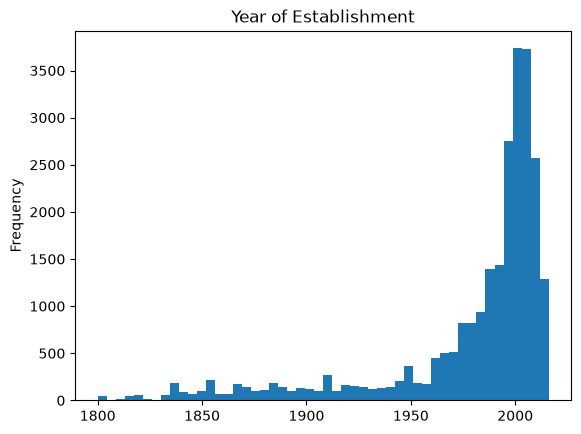

In [12]:
# Quantify the pre-1900 establishment years before deciding to keep them
pre1900 = (df['yr_of_estab'] < 1900).sum()
print(f"Established before 1900: {pre1900} ({pre1900 / len(df) * 100:.2f}%)")
print(df['yr_of_estab'].describe())
print("Skew:", round(df['yr_of_estab'].skew(), 3))
df['yr_of_estab'].plot(kind='hist', bins=50, title='Year of Establishment')


### Observations

1. There are a number of companies with the year of establishment prior to 1900.  Unsure if these are data entry errors or valid entries.  There is nothing in the documentation and we will proceed assuming it is true.
2. This dataset is left skewed. 

#### Let's check the count of each unique category in each of the categorical variables

In [13]:
print("Categorical Summary:\n", df.describe(include='object'))

Categorical Summary:
        case_id continent education_of_employee has_job_experience requires_job_training region_of_employment unit_of_wage full_time_position case_status
count    25447     25447                 25447              25447                 25447                25447        25447              25447       25447
unique   25447         6                     4                  2                     2                    5            4                  2           2
top     EZYV01      Asia            Bachelor's                  Y                     N            Northeast         Year                  Y   Certified
freq         1     16840                 10220              14786                 22498                 7189        22933              22741       17001


### Wage variables: prevailing_wage and unit_of_wage

We analyze `prevailing_wage` **as reported** and treat `unit_of_wage` as a categorical feature. We do **not** rescale the wage by its unit. The next cell shows why: Week, Month, and Year wages share the same numeric range, so the unit label is not a real per-period multiplier in this dataset. Multiplying by 52 / 12 / 2080 fabricates million-dollar salaries and inflates skew from ~0.76 to ~9. Raw `prevailing_wage` is only mildly right-skewed and needs no transform for the tree ensembles used here.

Prevailing Wage Statistics (raw, as reported):
Min: 2.1367, Max: 319210.27
Mean: 74468.28, Median: 70312.50
Skewness: 0.76

Raw prevailing_wage by unit_of_wage:
                  min    median        max  count
unit_of_wage                                     
Hour            2.137   373.204    999.919   2153
Month        1599.280 81826.010 264362.950     89
Week         2183.230 85075.820 280175.950    272
Year          100.000 76172.830 319210.270  22933


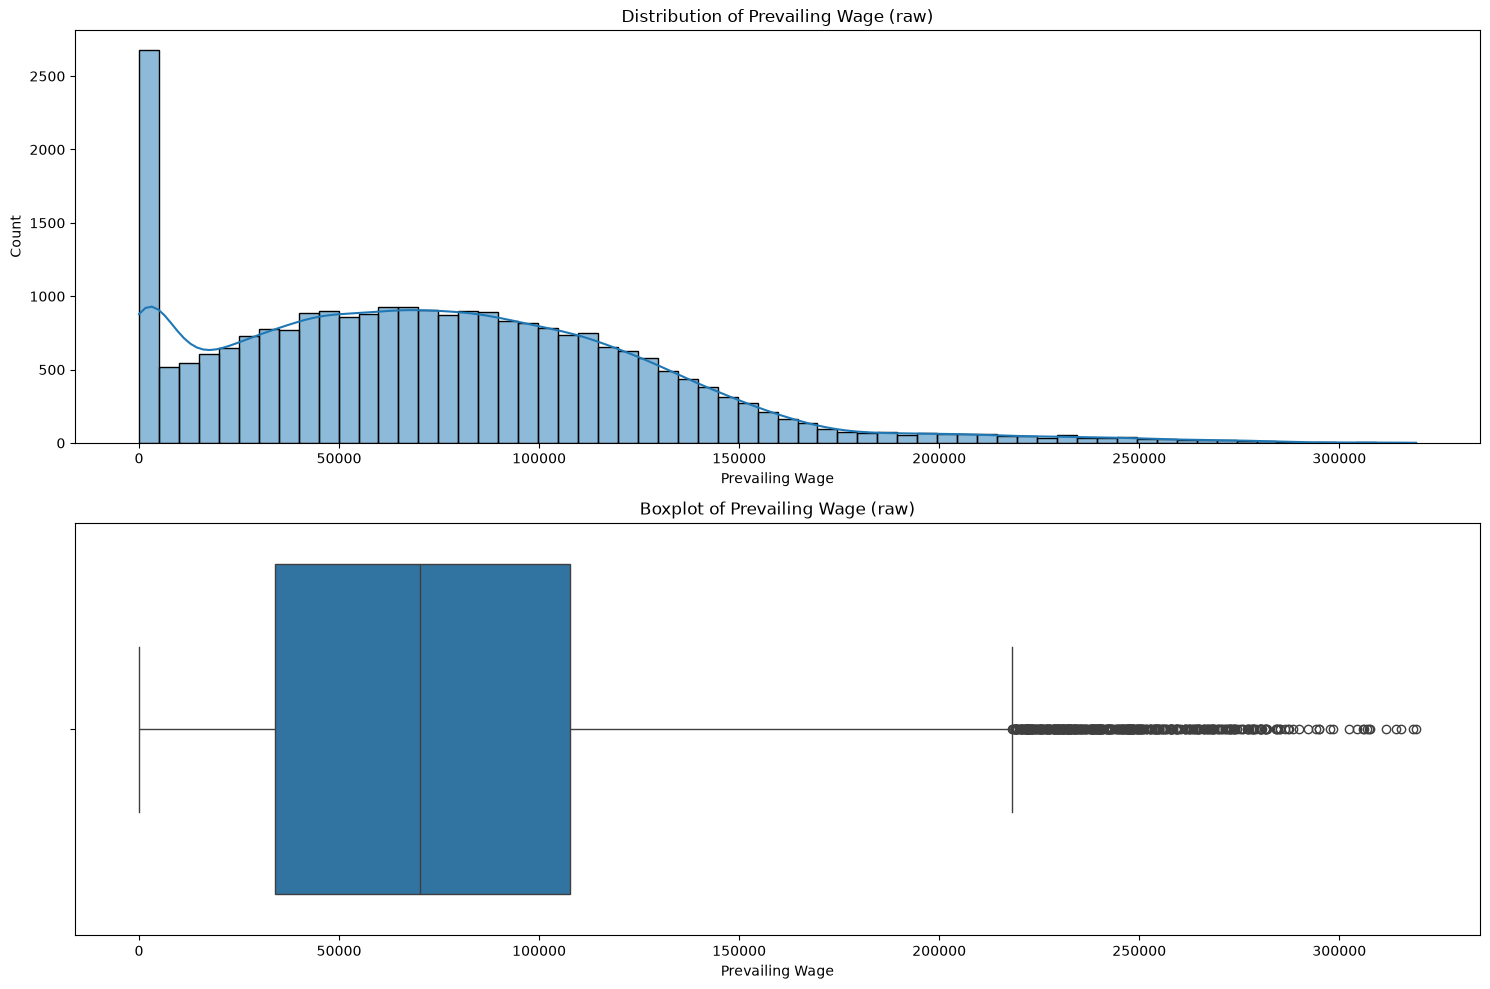

In [14]:
# Examine prevailing_wage as reported (no unit-based rescaling -- see note above)
print("Prevailing Wage Statistics (raw, as reported):")
print(f"Min: {df['prevailing_wage'].min()}, Max: {df['prevailing_wage'].max()}")
print(f"Mean: {df['prevailing_wage'].mean():.2f}, Median: {df['prevailing_wage'].median():.2f}")
print(f"Skewness: {df['prevailing_wage'].skew():.2f}")

# Evidence the unit label is not a true scaling factor: Week/Month/Year overlap,
# only Hour is on a distinct (smaller) scale.
print("\nRaw prevailing_wage by unit_of_wage:")
print(df.groupby('unit_of_wage')['prevailing_wage'].agg(['min', 'median', 'max', 'count']))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
sns.histplot(df['prevailing_wage'], kde=True, ax=ax1)
ax1.set_title('Distribution of Prevailing Wage (raw)')
ax1.set_xlabel('Prevailing Wage')
sns.boxplot(x=df['prevailing_wage'], ax=ax2)
ax2.set_title('Boxplot of Prevailing Wage (raw)')
ax2.set_xlabel('Prevailing Wage')
plt.tight_layout()
plt.show()

### Univariate Analysis

In [15]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [16]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot


Analyzing no_of_employees:
Min: 12, Max: 602069
Mean: 5674.4153338311, Median: 2112.0
Skewness: 12.257841915422253


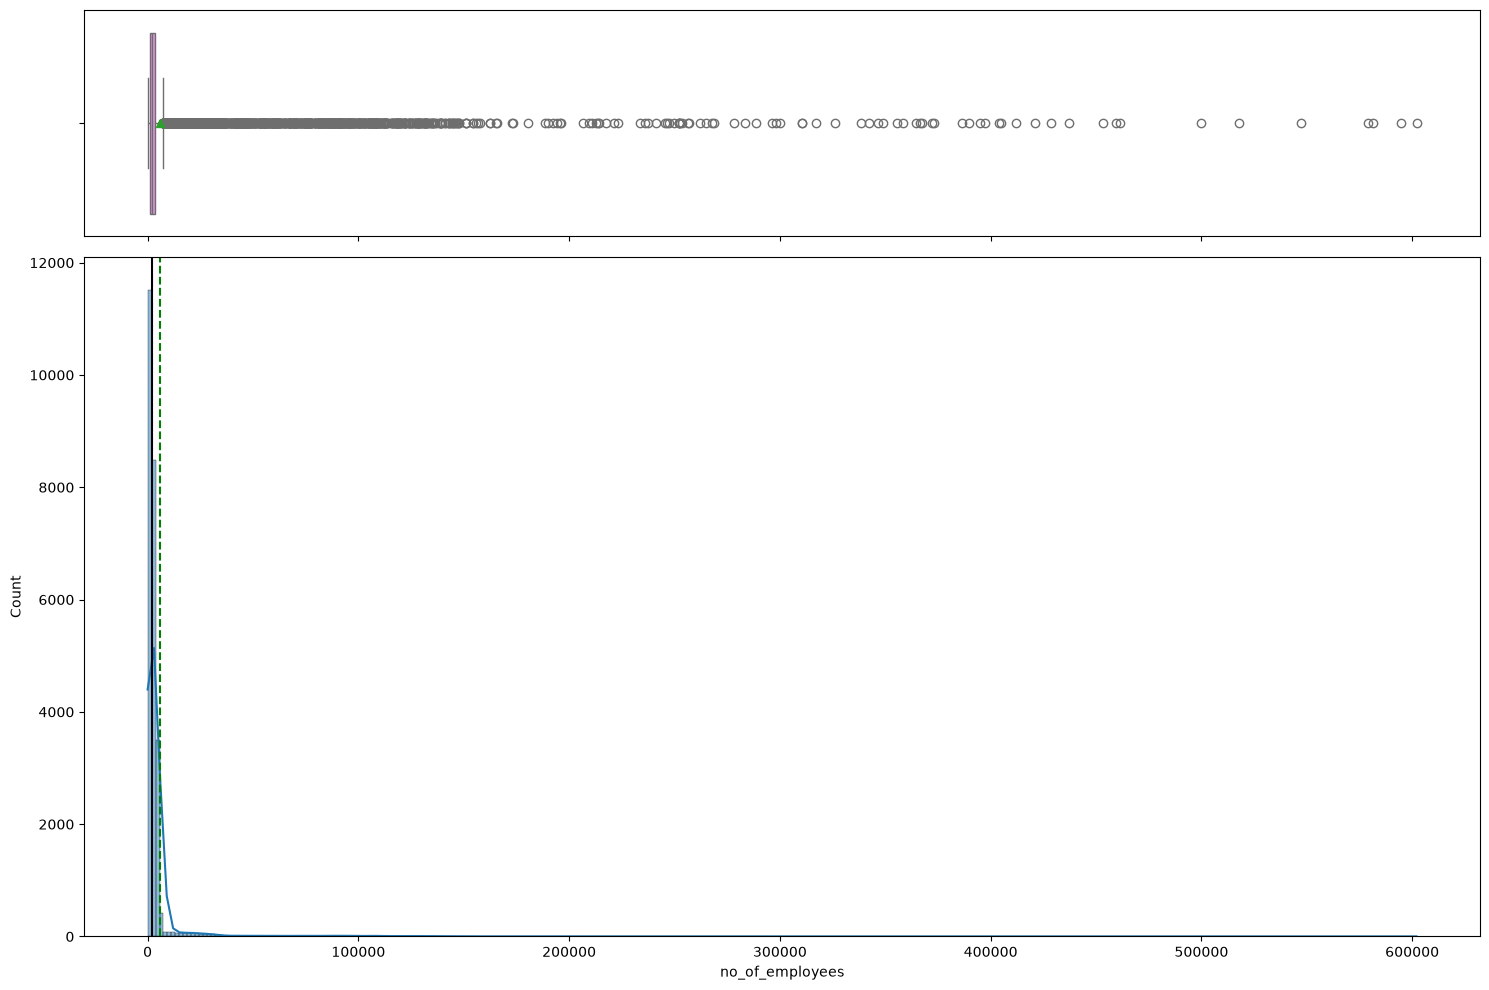


Analyzing yr_of_estab:
Min: 1800, Max: 2016
Mean: 1979.394506228632, Median: 1997.0
Skewness: -2.0361671588588717


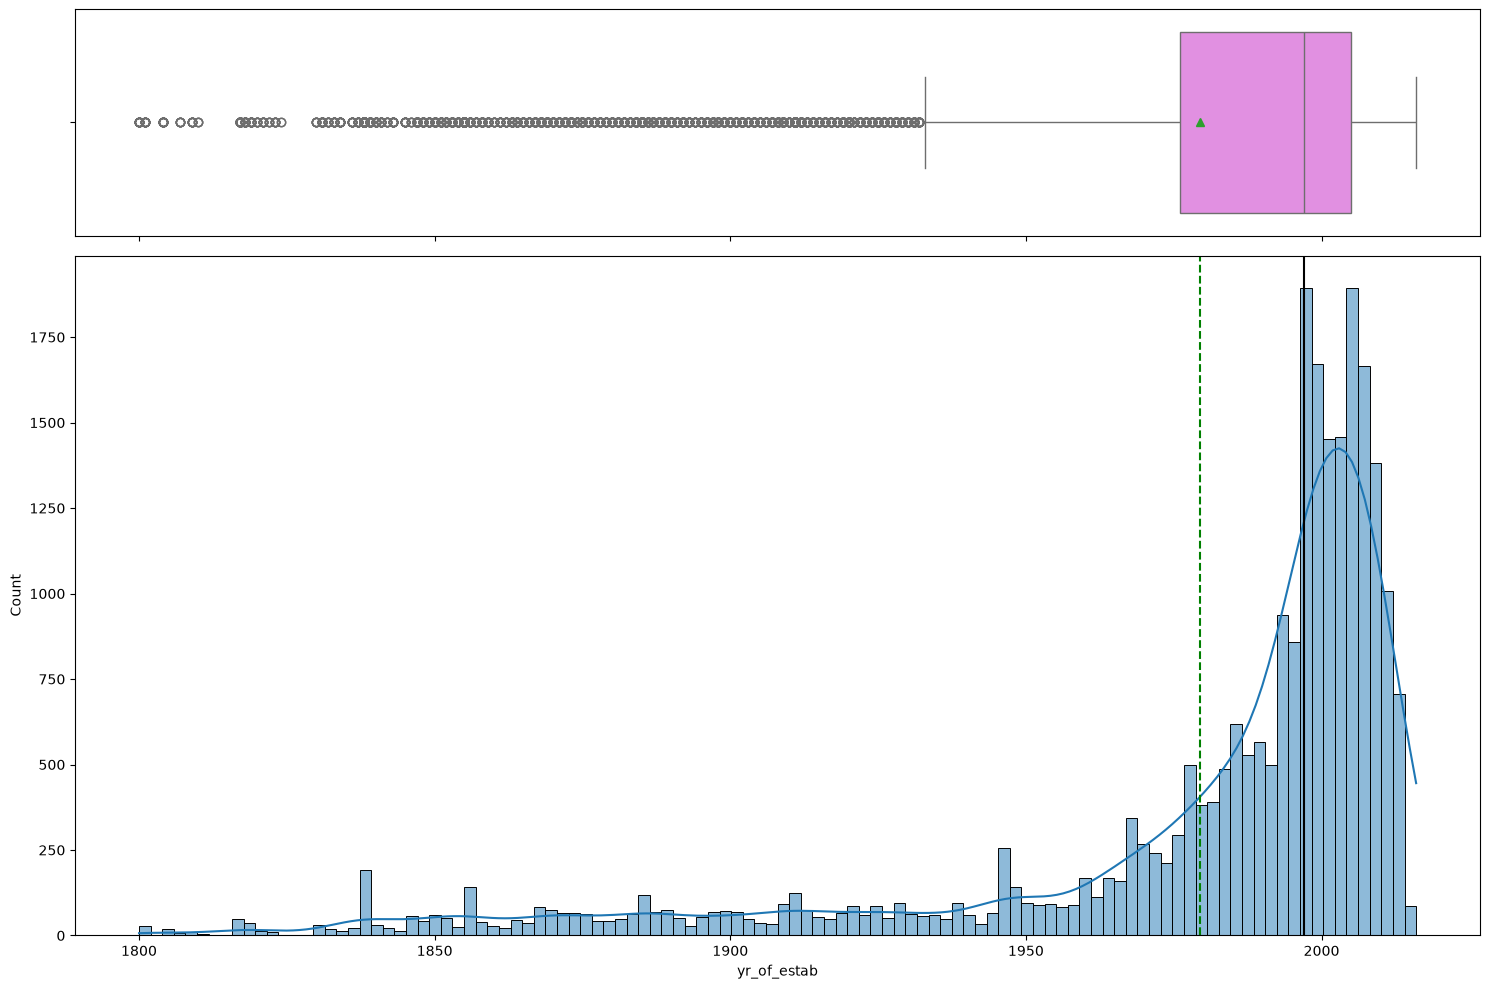


Analyzing prevailing_wage:
Min: 2.1367, Max: 319210.27
Mean: 74468.28147948677, Median: 70312.5
Skewness: 0.7560780264054282


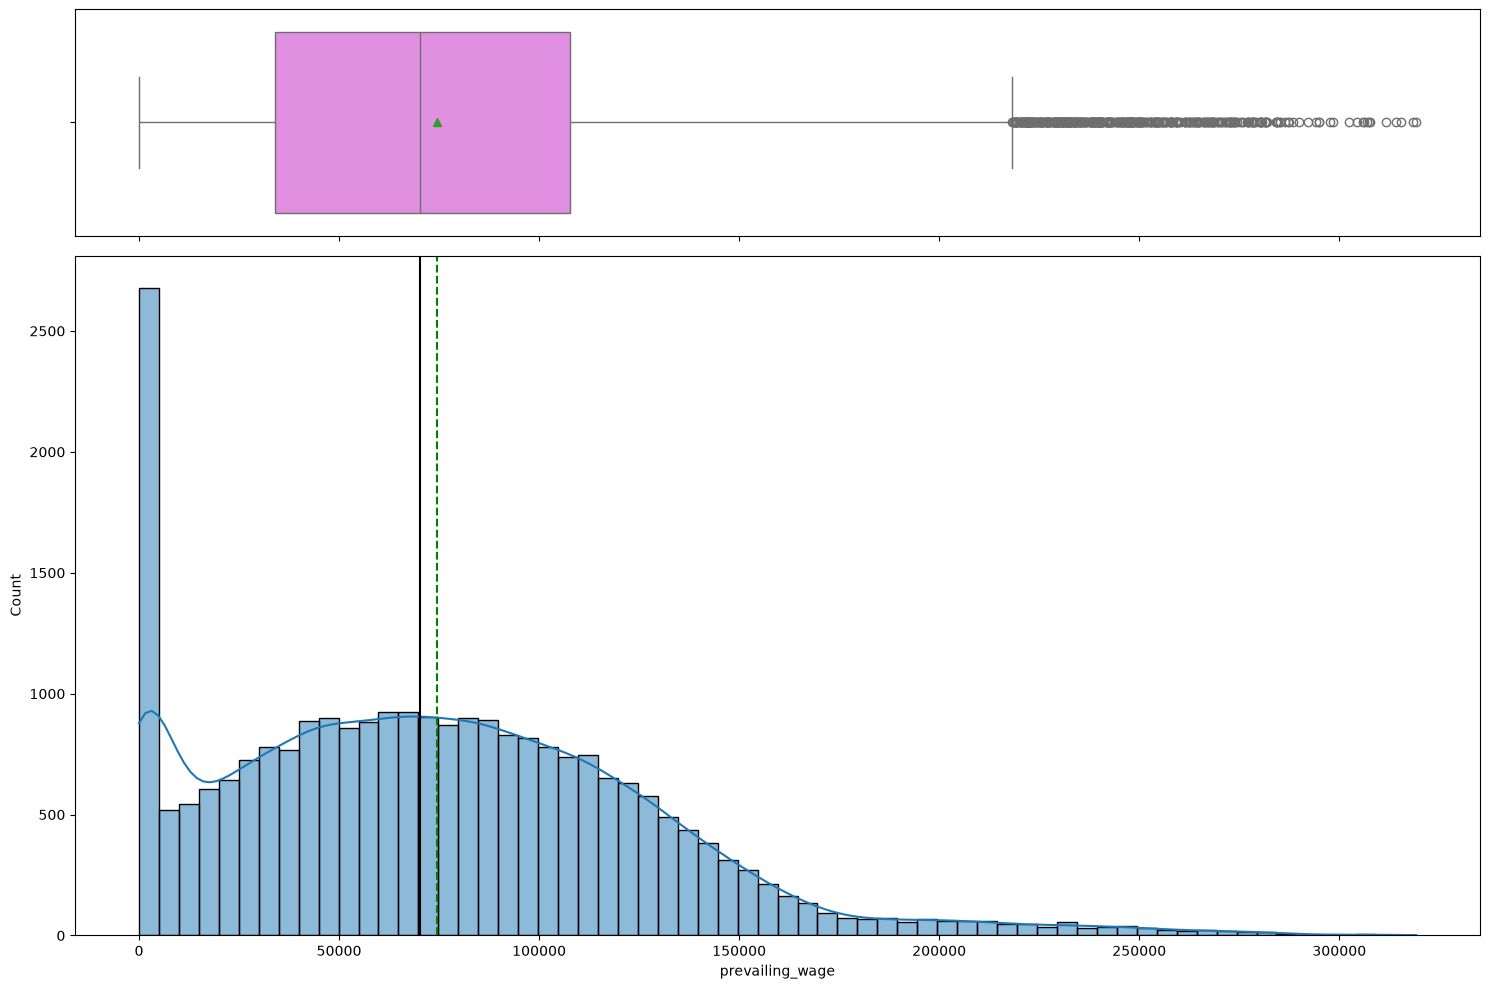


Analyzing continent:
Number of unique values: 6
continent
Asia            0.662
Europe          0.146
North America   0.129
South America   0.033
Africa          0.022
Name: proportion, dtype: float64


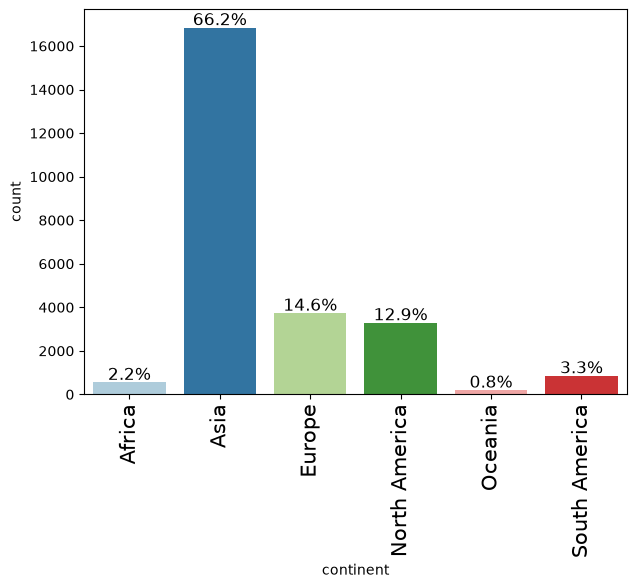

<Figure size 640x480 with 0 Axes>


Analyzing education_of_employee:
Number of unique values: 4
education_of_employee
Bachelor's    0.402
Master's      0.378
High School   0.134
Doctorate     0.086
Name: proportion, dtype: float64


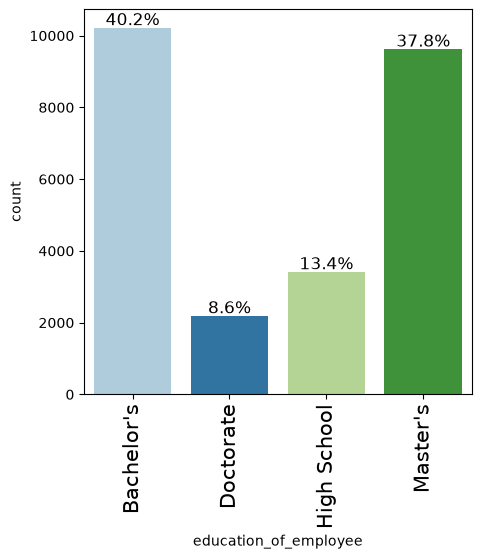

<Figure size 640x480 with 0 Axes>


Analyzing has_job_experience:
Number of unique values: 2
has_job_experience
Y   0.581
N   0.419
Name: proportion, dtype: float64


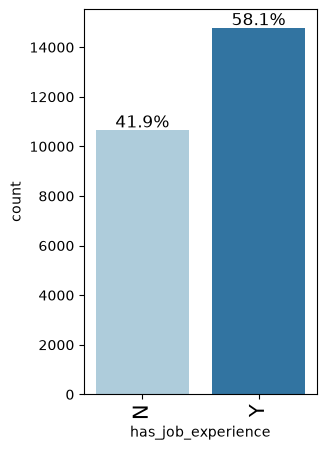

<Figure size 640x480 with 0 Axes>


Analyzing requires_job_training:
Number of unique values: 2
requires_job_training
N   0.884
Y   0.116
Name: proportion, dtype: float64


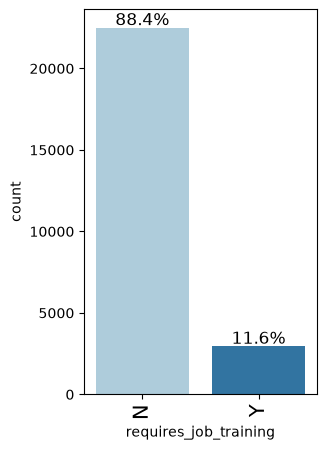

<Figure size 640x480 with 0 Axes>


Analyzing region_of_employment:
Number of unique values: 5
region_of_employment
Northeast   0.283
South       0.275
West        0.258
Midwest     0.169
Island      0.015
Name: proportion, dtype: float64


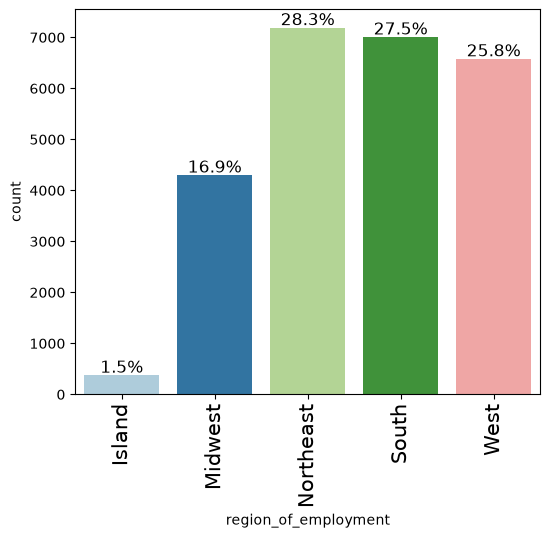

<Figure size 640x480 with 0 Axes>


Analyzing unit_of_wage:
Number of unique values: 4
unit_of_wage
Year    0.901
Hour    0.085
Week    0.011
Month   0.003
Name: proportion, dtype: float64


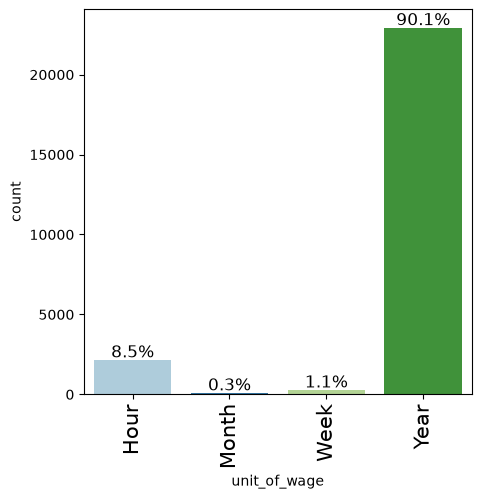

<Figure size 640x480 with 0 Axes>


Analyzing full_time_position:
Number of unique values: 2
full_time_position
Y   0.894
N   0.106
Name: proportion, dtype: float64


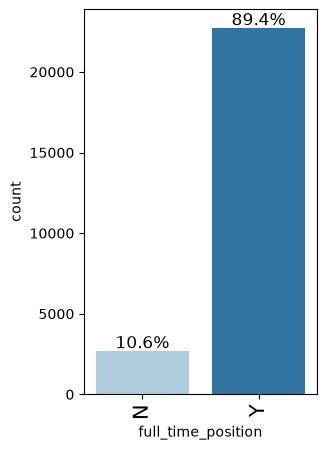

<Figure size 640x480 with 0 Axes>


Analyzing case_status:
Number of unique values: 2
case_status
Certified   0.668
Denied      0.332
Name: proportion, dtype: float64


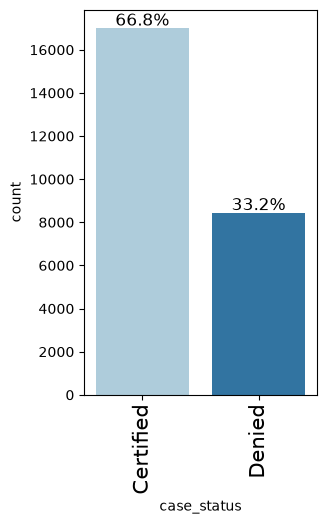

<Figure size 640x480 with 0 Axes>

In [17]:
# First, separate variables by type
numerical_features = ['no_of_employees', 'yr_of_estab', 'prevailing_wage']
categorical_features = ['continent', 'education_of_employee', 'has_job_experience', 
                       'requires_job_training', 'region_of_employment', 
                       'unit_of_wage', 'full_time_position', 'case_status']

# Analyze numerical variables
for feature in numerical_features:
    print(f"\nAnalyzing {feature}:")
    print(f"Min: {df[feature].min()}, Max: {df[feature].max()}")
    print(f"Mean: {df[feature].mean()}, Median: {df[feature].median()}")
    print(f"Skewness: {df[feature].skew()}")
    histogram_boxplot(df, feature, kde=True)
    plt.tight_layout()
    plt.show()

# Analyze categorical variables
for feature in categorical_features:
    print(f"\nAnalyzing {feature}:")
    print(f"Number of unique values: {df[feature].nunique()}")
    print(df[feature].value_counts(normalize=True).head())
    labeled_barplot(df, feature, perc=True)
    plt.tight_layout()
    plt.show()

#### Observation on Number of Employees

1. The number of employees is right skewed.
2. The median is 2109 employees.
3. The mean is 5667 employees.
4. The standard deviation is 12265 employees.
5. The minimum is 11 employees.
6. The maximum is 602069 employees.
7. The skewness is 12.265272741810568.

##### Model Implications

1. Extreme Skewness: With a skewness of 12.27 (heavily right-skewed), this variable will definitely need transformation. Log transformation would be particularly effective here.
2. Outlier Influence: The maximum (602,069) is vastly different from the median (2,109), indicating potential outliers that could disproportionately influence the model.
3. Feature Engineering:
    - Consider creating company size categories (small, medium, large, enterprise)
    - Log transformation will make this variable more normally distributed
4. Model Selection Impact:
    - Tree-based models can handle this skewness better than linear models
    - If using linear models, transformation is essential   

#### Observations on Year of Establishment

1. The year of establishment is left skewed.
2. The median is 2010.
3. The mean is 1979.
4. The standard deviation is 10.
5. The minimum is 1800.
6. The maximum is 2016.
7. There are a number of companies with the year of establishment prior to 1900.  Unsure if these are data entry errors or valid entries.  There is nothing in the documentation and we will proceed assuming it is true.
8. The skewness is -2.037301271676438.  

##### Model Implications

1. Skewness Transformation: With a skewness of -2.04 (left-skewed), this variable will need transformation before using in algorithms sensitive to non-normal distributions (like linear models). Consider log transformation or Box-Cox.
2. Feature Engineering:
- Create a "company_age" feature (2016 - yr_of_estab) which might be more intuitive
- Consider binning into categories like "historic" (pre-1900), "established" (1900-1980), "mature" (1980-2000), "recent" (2000-2010), "startup" (2010+)
3. Outlier Handling: The very old establishments (1800s) should be examined in bivariate analysis to see if they have distinctive approval patterns.
4. Mean-Median Gap: The large difference between mean (1979) and median (2010) confirms the strong skewness and suggests most companies are relatively new.
5. Model Selection Impact: Tree-based models can handle this skewness better than linear models. If using linear models, transformation is essential.

#### Observations for Prevailing Wage

1. Mild right-skew: Raw `prevailing_wage` has a skewness of ~0.76 (not the 8.98 produced by unit-standardization). Mean (~$74.5k) and median (~$70.3k) are close.
2. Mixed units share one scale: Week, Month, and Year prevailing wages occupy the same numeric range (medians ~$85k / $82k / $76k). Only Hour sits on a distinct, smaller scale (median ~$373). The `unit_of_wage` label is therefore not a true per-period multiplier in this dataset.
3. Data-quality tail: A subset of Year-unit rows report implausibly low annual wages (down to $100; ~2,200 rows below $20k). Likely entry errors, left in place because tree ensembles tolerate them.
4. unit_of_wage is predictive on its own: certification rate is ~35% for Hour rows vs ~70% for Year rows (base ~67%), so the unit carries strong standalone signal preserved by keeping it categorical.

##### Model Implications

1. Preprocessing: Use raw `prevailing_wage` as the numeric feature and keep `unit_of_wage` categorical. No unit rescaling and no log transform are needed for the tree ensembles used here.
2. Algorithm fit: Random forest, bagging, and gradient boosting are scale-invariant and robust to the residual skew and the low-wage tail. A log transform would only matter if we later fit linear or distance-based models.
3. Feature engineering: Relative-position features (wage quantile) can still help, but flat absolute-wage thresholds are not meaningful because Hour and annual units share the column at different scales.

#### Observations on Continent
1. Class Imbalance: This is a highly imbalanced categorical feature, with Asia being the dominant category.
2. Representativeness: The dataset primarily represents Asian applicants, which may limit the model's ability to generalize to applicants from other continents.
3. Statistical Power: For minority continents, you'll have less statistical power to detect patterns specific to those regions.
4. Model Bias: Your model might become biased toward patterns common among Asian applicants and might not perform well for other continents.

##### Model Implications

1. Feature Engineering Options:
- Consider binary encoding (Asia vs. Non-Asia) if the minority classes show similar patterns
- Group very small categories into an "Other" category if they have similar visa approval rates
- Keep as-is if each continent shows distinct approval patterns despite the imbalance
2. Model Evaluation Strategy:
- Stratify your train/test splits by continent to ensure all continents are represented in both sets
- Evaluate model performance separately for each continent to identify potential biases
3. Bivariate Analysis Focus:
- Carefully examine approval rates by continent to see if there are significant differences
- Look for interaction effects between continent and other variables (education, wage, etc.)
4. Business Context:
- This imbalance likely reflects real-world visa application patterns, with most applicants coming from Asia
- Consider whether this matches domain knowledge about visa applications
5. Sampling Considerations:
- If using resampling techniques for the target variable, consider stratifying by continent
- Be cautious with techniques that might further distort the continent distribution.


#### Observations on Education

1. The education level distribution is relatively balanced, with Bachelor's and Master's degrees making up the majority (78%) of applicants.
2. Bachelor's degree holders are the most common (40.2%), closely followed by Master's degree holders (37.8%).
3. High School graduates represent a smaller but significant portion (13.4%) of applicants.
4. Doctorate holders are the least common (8.6%), which aligns with general workforce education patterns.

##### Model Implications

1. Ordinal Nature: This variable has a natural ordering (High School < Bachelor's < Master's < Doctorate) that could be leveraged in modeling.
2. Feature Engineering Options:
    - Consider ordinal encoding (0-3) to preserve the education hierarchy
    - Alternatively, create binary features like "has_graduate_degree" (Master's or Doctorate)
    - For tree-based models, one-hot encoding would work well
3. Predictive Potential:
    - Education level likely correlates strongly with visa approval rates
    - Higher education typically indicates specialized skills that may be in higher demand
4. Interaction Possibilities:
    - Examine how education interacts with prevailing wage
    - Look for patterns across continent and education level combinations
    - Consider if education requirements vary by industry or company size
5. Class Balance:
    - The distribution is balanced enough that no special handling is needed for modeling
    - All categories have sufficient representation for reliable analysis

#### Observations on Region of Employment

1. The region distribution is relatively balanced across the three major regions: Northeast (28.2%), South (27.5%), and West (25.8%).
2. The Midwest represents a smaller but significant portion (16.9%) of employment locations.
3. Island regions are notably underrepresented (1.5%), which may reflect the smaller population and economic activity in these areas.
4. Overall, the distribution reflects the general economic activity and population distribution across U.S. regions.

##### Modeling Implications

1. Categorical Encoding:
- One-hot encoding would be appropriate for this variable
- No need for special handling of minority classes except possibly for "Island"
2. Island Region Consideration:
- With only 1.5% representation, the "Island" category may have insufficient data for reliable patterns
- Consider whether to keep it separate or merge with another region based on approval patterns
3. Geographic Insights:
- Different regions may have different industry concentrations and labor market conditions
- These regional economic differences could influence visa approval rates
4. Interaction Possibilities:
- Examine interactions between region and prevailing wage (accounting for cost of living differences)
- Look for patterns in the types of companies (size, age) across different regions
- Consider if education requirements vary by region
5. Predictive Potential:
- Region may correlate with visa approval rates due to different economic needs and immigration patterns
- Some regions may have higher demand for specific skills or industries

#### Observations and Model Implications for Unit of Wage

1. Dominant Category: The vast majority (90.1%) of wages are reported on an annual basis.
2. Minority Categories: Hourly wages represent a small portion (8.5%), while weekly (1.1%) and monthly (0.3%) are very rare.
3. Imbalanced Distribution: This is a highly imbalanced categorical variable with one dominant class.
4. Standardization Impact: The standardization we performed was crucial for the 9.9% of cases not reported annually.
5. Job Type Indicator: Different wage units might correlate with different job types or employment arrangements (e.g., hourly for contract work, annual for salaried positions).

##### Model Implications
1. Feature Engineering:
- Now that we've created the standardized annual wage, this variable may be redundant
- Consider creating a binary feature "is_hourly_wage" (combining the three non-annual categories may be more useful than keeping them separate)
- The unit might serve as a proxy for job type or employment arrangement
2. Handling Imbalance:
- Due to the extreme imbalance, one-hot encoding would create sparse features
- Binary encoding (annual vs. non-annual) would be more effective
- For tree-based models, the original categorical encoding can be used
3. Potential Interactions:
- Examine if hourly wages have different approval patterns compared to annual wages
- Investigate if the unit of wage interacts with full-time status
- Check if certain education levels or job types correlate with specific wage units
4. Bivariate Analysis Focus:
- Compare approval rates between annual and non-annual wage units
- Examine if the standardized wage distribution differs significantly by wage unit
- Look for patterns in which types of jobs or companies use non-annual wage reporting
5. Modeling Strategy:
- Since we've already standardized the wage, consider:
- Dropping this variable entirely if it shows little predictive power
- Keeping only a binary version (annual vs. non-annual)
- Using it as a control variable in feature interactions
6. Data Quality Consideration:
- The extremely low proportion of monthly wages (0.3%) may not provide sufficient signal
- Consider whether the standardization process correctly handled all wage units
This variable provided critical context for standardizing wages, but now that we've created the standardized annual wage, its direct predictive value may be limited. Its main value might be as an indicator of employment type or in interaction with other variables.

#### Observations on job experience

#### Observations on Binary Employment Features

1. Job Experience:
- Well-balanced distribution with 58.1% having job experience and 41.9% without
- This suggests a mix of entry-level and experienced applicants in the dataset
2. Job Training Requirements:
- Heavily imbalanced with 88.4% not requiring job training and only 11.6% requiring it
- Most visa applications are for roles where the applicant is expected to be ready to work without additional training
3. Employment Type:
- Predominantly full-time positions (89.4%) with only 10.6% part-time positions
- This aligns with visa programs typically targeting permanent, full-time employment

##### Model Implications
1. Feature Encoding
- These binary variables can be encoded as 0/1 or kept as Y/N for most algorithms
- For has_job_experience, no special handling is needed due to balanced distribution
- For the imbalanced features (requires_job_training and full_time_position), consider:
- Monitoring their importance in tree-based models
- Examining their impact on model performance when included/excluded
2. Predictive Power:
- has_job_experience likely has strong predictive power due to its balanced distribution
- The imbalanced variables may still be important if the minority class strongly correlates with visa decisions
- full_time_position may be particularly relevant as immigration policies often favor permanent positions
3. Interaction Analysis:
- Examine how job experience interacts with education level
- Investigate if job training requirements vary by industry or company age
- Analyze whether part-time positions show different approval patterns across wage levels
4. Class Imbalance Handling:
- No special sampling techniques needed for has_job_experience
- For the imbalanced features, their predictive power should be evaluated carefully
- Consider creating composite features that combine these characteristics
5. Bivariate Focus Areas:
- Compare approval rates between experienced and inexperienced applicants
- Examine if the small percentage of roles requiring training have different approval patterns
- Investigate whether part-time positions face different approval challenges

#### Observations on Case Status (Target Variable)

1. The target variable case_status shows a moderate imbalance with 66.8% of applications being Certified and 33.2% being Denied.
2. This 2:1 ratio indicates that while there is class imbalance, it's not extreme, and both classes have substantial representation in the dataset.
3. The approval rate of 66.8% provides a baseline against which to measure model performance.

##### Model Implications
1. Classification Approach:
- This is a binary classification problem with moderate class imbalance
- The imbalance is not severe enough to require extreme measures, but should still be addressed
2. Performance Metrics:
- Accuracy alone would be misleading due to the imbalance
- Focus on balanced metrics such as:
- F1-score
- AUC-ROC
- Precision and recall
- Balanced accuracy
3. Imbalanced Learning Techniques:
- Consider using techniques from the imbalanced-learn library:
- SMOTE for synthetic minority oversampling
- Class weights in algorithms that support them
- Ensemble methods specifically designed for imbalanced data
4. Threshold Optimization:
- The default 0.5 probability threshold may not be optimal
- Consider threshold tuning based on business requirements (e.g., minimizing false negatives vs. false positives)
5. Validation Strategy:
- Use stratified cross-validation to maintain the class distribution across folds
- Consider evaluating model performance separately on each class
6. Business Context:
- The 33.2% denial rate represents significant opportunity for improvement
- Focus on identifying key factors that distinguish between approved and denied applications

## Model Implications from Univariate Analysis
### A. Data Preprocessing Strategy
1. Numerical Variables:
Prevailing Wage: Use raw `prevailing_wage` (mild skew ~0.76); no unit rescaling and no log transform needed for tree ensembles
Number of Employees: Highly right-skewed (skewness 12.27); trees handle it as-is, log only if linear models are added
Year of Establishment: Consider creating a company_age feature from yr_of_estab (left-skewed with skewness -2.04)
Data Cleaning: Note implausibly low Year-unit wages (down to $100); left in place for tree models
2. Categorical Variables:
Continent: Handle the imbalance (Asia 66.2%) through appropriate encoding or stratification
Education Level: Use ordinal encoding for education_of_employee to preserve the natural hierarchy
Binary Variables: Use as-is, with attention to the imbalanced ones (requires_job_training, full_time_position)
Region of Employment: Well-balanced except for the Island category (1.5%)
Unit of Wage: Keep as a categorical feature; it carries strong standalone signal (Hour ~35% vs Year ~70% certification) and should NOT be folded into wage magnitude
### B. Model Selection Recommendations
1. Primary Recommendation: Tree-based ensemble models
Can handle the various distributions and imbalances in the dataset
Naturally capture non-linear relationships and interactions
Scale-invariant and robust to the residual wage skew and low-wage tail
2. Secondary Approach: Linear models with appropriate preprocessing
Would require a log transform on prevailing_wage and explicit interaction terms
Consider regularization to handle potential multicollinearity
### C. Feature Engineering Priorities
1. Wage-Related Features:
Use raw `prevailing_wage` as the primary numeric feature
Optionally a rank-based wage quantile to capture relative position (robust to the mixed-unit scale)
Avoid flat absolute-wage thresholds, which conflate Hour-unit and annual-unit rows
2. Company Features:
Company age from year of establishment
Log-transformed employee count (if linear models are used)
Company maturity index (combining age and size)
3. Composite Features:
Experience-education combination
Job complexity indicator (combining education, training, and wage)
unit_of_wage as an hourly-vs-salaried indicator
### D. Handling Target Class Imbalance
1. Moderate Imbalance Strategy:
The 66.8% Certified vs. 33.2% Denied split requires attention but not extreme measures
Use class weights or SMOTE from imbalanced-learn
Ensure evaluation metrics account for class imbalance (F1, AUC-ROC)
### E. Evaluation Framework
1. Cross-Validation Approach:
Use stratified k-fold cross-validation to maintain class distributions
Consider multi-level stratification (by both target and continent)
2. Performance Metrics:
Primary: Balanced accuracy, F1-score, AUC-ROC
Secondary: Precision and recall for the minority class (Denied)
Consider business-specific cost functions if false positives and false negatives have different impacts
### F. Key Insights on Wage Handling
1. No standardization: Week/Month/Year prevailing wages share one numeric scale, so unit-based rescaling is invalid and was removed. Raw `prevailing_wage` is only mildly skewed.
2. Unit of Wage as signal: 90.1% of wages are reported annually, hourly (8.5%) being the main alternative. The unit is a meaningful job-type/target signal kept as its own categorical feature.
3. Data Quality Focus: Investigate the implausibly low Year-unit wages as potential errors; retained for tree models that tolerate them.

### Bivariate Analysis

**Creating functions that will help us with further analysis.**

In [18]:
### function to plot distributions wrt target


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
        stat="density",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
        stat="density",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

In [19]:
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

#### Those with higher education may want to travel abroad for a well-paid job. Let's find out if education has any impact on visa certification

#### Analyzing the impact of education on visa certification ####

Approval rates by education level:
case_status            Certified  Denied
education_of_employee                   
Bachelor's                 0.623   0.377
Doctorate                  0.873   0.127
High School                0.341   0.659
Master's                   0.786   0.214

Stacked bar plot of case status by education level:
case_status            Certified  Denied    All
education_of_employee                          
All                        17001    8446  25447
Bachelor's                  6362    3858  10220
High School                 1164    2252   3416
Master's                    7565    2057   9622
Doctorate                   1910     279   2189
------------------------------------------------------------------------------------------------------------------------


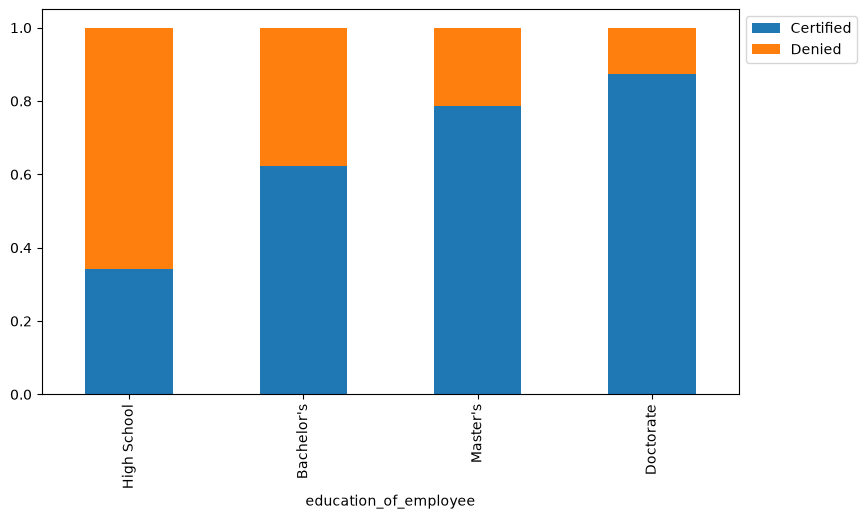


Chi-square test: chi2=2764.6344, p-value=0.0000
There is a statistically significant relationship between education level and visa certification (p<0.05)

Average annual wage by education level:
education_of_employee
Doctorate     64556.271
High School   71598.598
Bachelor's    73427.276
Master's      78847.756
Name: prevailing_wage, dtype: float64


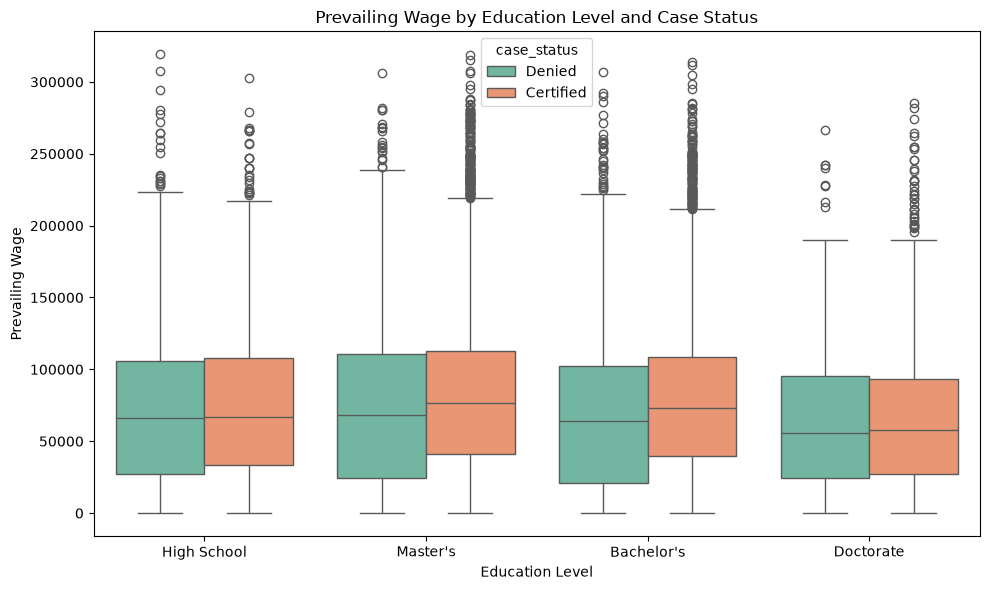


Education distribution by continent (percentages):
education_of_employee  Bachelor's  Doctorate  High School  Master's
continent                                                          
Africa                      0.260      0.098        0.120     0.522
Asia                        0.425      0.055        0.136     0.384
Europe                      0.349      0.226        0.131     0.294
North America               0.372      0.078        0.122     0.428
Oceania                     0.344      0.115        0.188     0.354
South America               0.391      0.105        0.161     0.343

Summary of education impact on visa certification:
- High School: 34.1% certification rate
- Master's: 78.6% certification rate
- Bachelor's: 62.3% certification rate
- Doctorate: 87.3% certification rate


In [20]:
# Import required library if not already imported
from scipy import stats

# Analyzing the impact of education on visa certification
print("#### Analyzing the impact of education on visa certification ####")

# 1. Calculate approval rates by education level
education_approval = pd.crosstab(df['education_of_employee'], df['case_status'], normalize='index')
print("\nApproval rates by education level:")
print(education_approval)

# 2. Create stacked bar plot
print("\nStacked bar plot of case status by education level:")
stacked_barplot(df, 'education_of_employee', 'case_status')

# 3. Chi-square test to determine statistical significance
contingency_table = pd.crosstab(df['education_of_employee'], df['case_status'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
print(f"\nChi-square test: chi2={chi2:.4f}, p-value={p:.4f}")
if p < 0.05:
    print("There is a statistically significant relationship between education level and visa certification (p<0.05)")
else:
    print("There is no statistically significant relationship between education level and visa certification (p>=0.05)")

# 4. Examine education and wage relationship
print("\nAverage annual wage by education level:")
education_wage = df.groupby('education_of_employee')['prevailing_wage'].mean().sort_values()
print(education_wage)

# 5. Visualize education and wage relationship with case status
plt.figure(figsize=(10, 6))
sns.boxplot(x='education_of_employee', y='prevailing_wage', hue='case_status', data=df, palette='Set2')
plt.title('Prevailing Wage by Education Level and Case Status')
plt.xlabel('Education Level')
plt.ylabel('Prevailing Wage')
plt.tight_layout()
plt.show()

# 6. Additional insight: Education distribution by continent
print("\nEducation distribution by continent (percentages):")
continent_edu = pd.crosstab(df['continent'], df['education_of_employee'], normalize='index')
print(continent_edu)

# 7. Summary of findings
print("\nSummary of education impact on visa certification:")
for edu in df['education_of_employee'].unique():
    cert_rate = education_approval.loc[edu, 'Certified'] * 100
    print(f"- {edu}: {cert_rate:.1f}% certification rate")

#### Lets' similarly check for the continents and find out how the visa status vary across different continents.

case_status    Certified  Denied    All
continent                              
All                17001    8446  25447
Asia               11001    5839  16840
North America       2037    1250   3287
Europe              2953     774   3727
South America        492     359    851
Africa               396     154    550
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


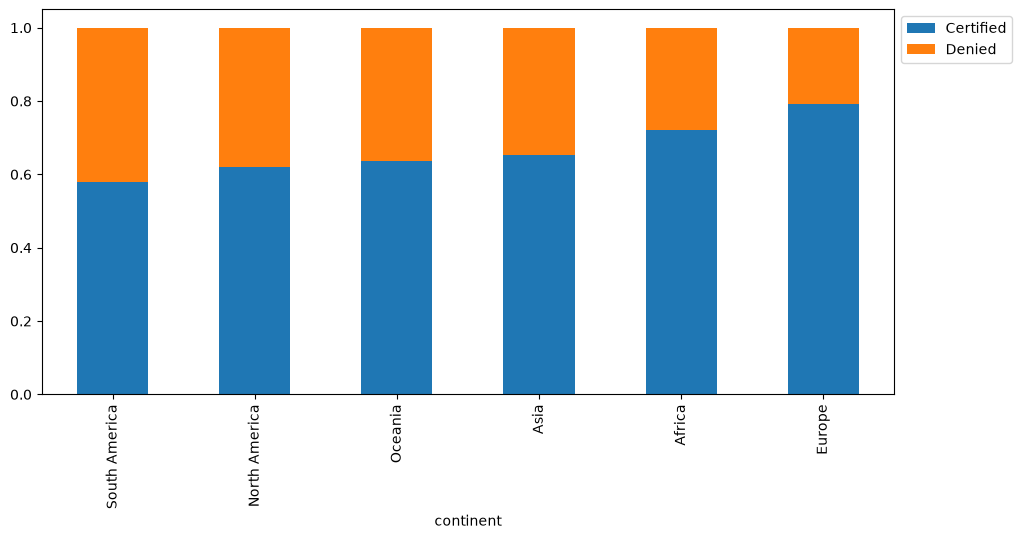


Chi-square test: chi2=349.4559, p-value=0.0000
There is a statistically significant relationship between continent and visa certification (p<0.05)


In [21]:
# Analyzing how visa status varies across different continents
stacked_barplot(df, 'continent', 'case_status')

# Chi-square test of independence
contingency_table = pd.crosstab(df['continent'], df['case_status'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
print(f"\nChi-square test: chi2={chi2:.4f}, p-value={p:.4f}")
if p < 0.05:
    print("There is a statistically significant relationship between continent and visa certification (p<0.05)")
else:
    print("There is no statistically significant relationship between continent and visa certification (p>=0.05)")

#### Experienced professionals might look abroad for opportunities to improve their lifestyles and career development. Let's see if having work experience has any influence over visa certification

case_status         Certified  Denied    All
has_job_experience                          
All                     17001    8446  25447
N                        5986    4675  10661
Y                       11015    3771  14786
------------------------------------------------------------------------------------------------------------------------


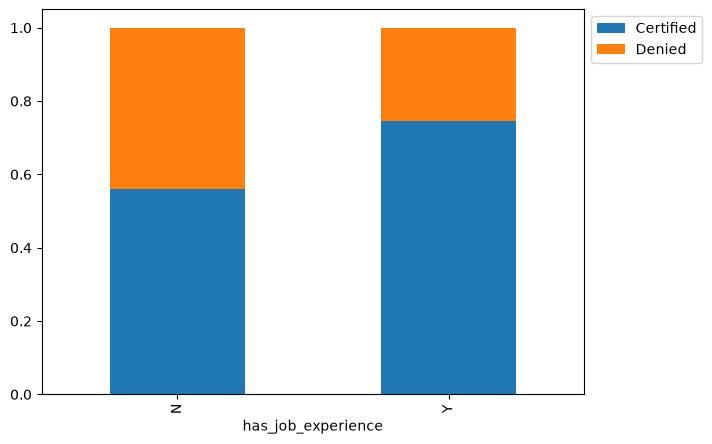


Chi-square test: chi2=939.5814, p-value=0.0000
There is a statistically significant relationship between job experience and visa certification (p<0.05)


In [22]:
# Analyzing if work experience influences visa certification
stacked_barplot(df, 'has_job_experience', 'case_status')

# Chi-square test of independence
contingency_table = pd.crosstab(df['has_job_experience'], df['case_status'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
print(f"\nChi-square test: chi2={chi2:.4f}, p-value={p:.4f}")
if p < 0.05:
    print("There is a statistically significant relationship between job experience and visa certification (p<0.05)")
else:
    print("There is no statistically significant relationship between job experience and visa certification (p>=0.05)")

#### Checking if the prevailing wage is similar across all the regions of the US

##### Please note prevailing wage without the attached unit of wage is not very useful. Prevailing wage has been converted to a standardized wage. 

#### Checking if the prevailing wage is similar across all the regions of the US


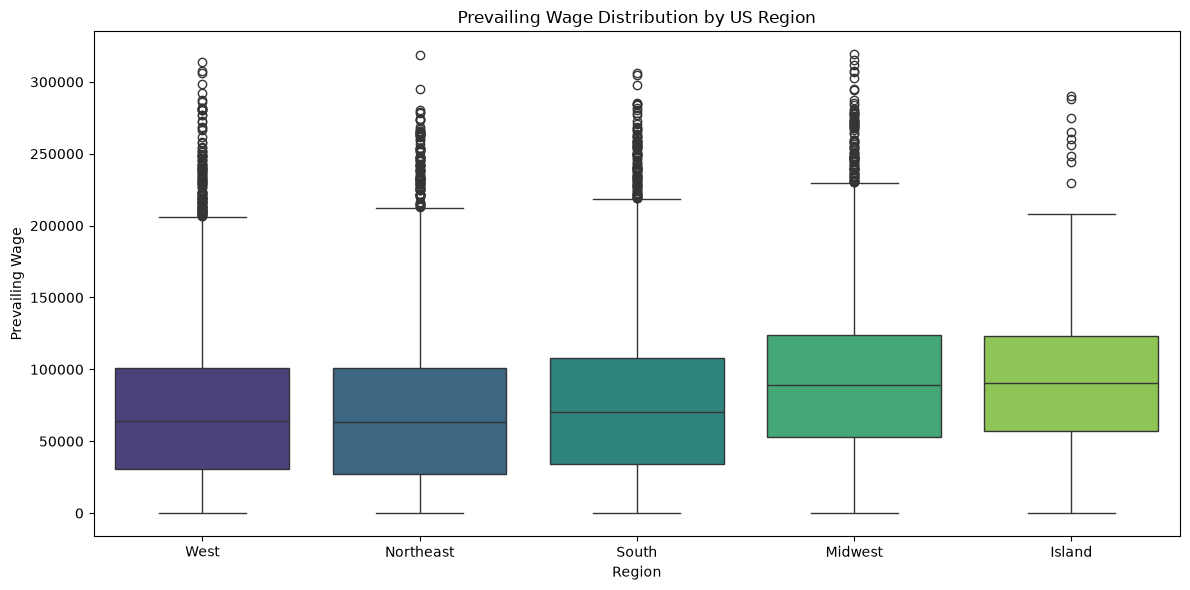


Prevailing Wage Statistics by Region:
                          mean    median       std
region_of_employment                              
Island               91712.750 90678.170 53836.060
Midwest              91691.670 89153.910 54576.360
Northeast            67886.110 63276.740 51560.440
South                74064.960 70192.670 52480.960
West                 69852.120 64358.440 50647.070

ANOVA test: F-statistic=169.1823, p-value=0.0000
There are statistically significant differences in wages across regions (p<0.05)


In [23]:
# Analyzing if prevailing wage is similar across US regions
print("#### Checking if the prevailing wage is similar across all the regions of the US")

# Create boxplot of prevailing wages by region
plt.figure(figsize=(12, 6))
sns.boxplot(x='region_of_employment', y='prevailing_wage', data=df, palette='viridis')
plt.title('Prevailing Wage Distribution by US Region')
plt.xlabel('Region')
plt.ylabel('Prevailing Wage')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Calculate summary statistics by region
wage_by_region = df.groupby('region_of_employment')['prevailing_wage'].agg(['mean', 'median', 'std']).round(2)
print("\nPrevailing Wage Statistics by Region:")
print(wage_by_region)

# Perform ANOVA test to check if the differences are statistically significant
from scipy import stats
regions = df['region_of_employment'].unique()
wage_groups = [df[df['region_of_employment'] == region]['prevailing_wage'] for region in regions]
f_stat, p_value = stats.f_oneway(*wage_groups)
print(f"\nANOVA test: F-statistic={f_stat:.4f}, p-value={p_value:.4f}")
if p_value < 0.05:
    print("There are statistically significant differences in wages across regions (p<0.05)")
else:
    print("There are no statistically significant differences in wages across regions (p>=0.05)")

#### The US government has established a prevailing wage to protect local talent and foreign workers. Let's analyze the data and see if the visa status changes with the prevailing wage

Let's analyze the data and see if the visa status changes with the prevailing wage.


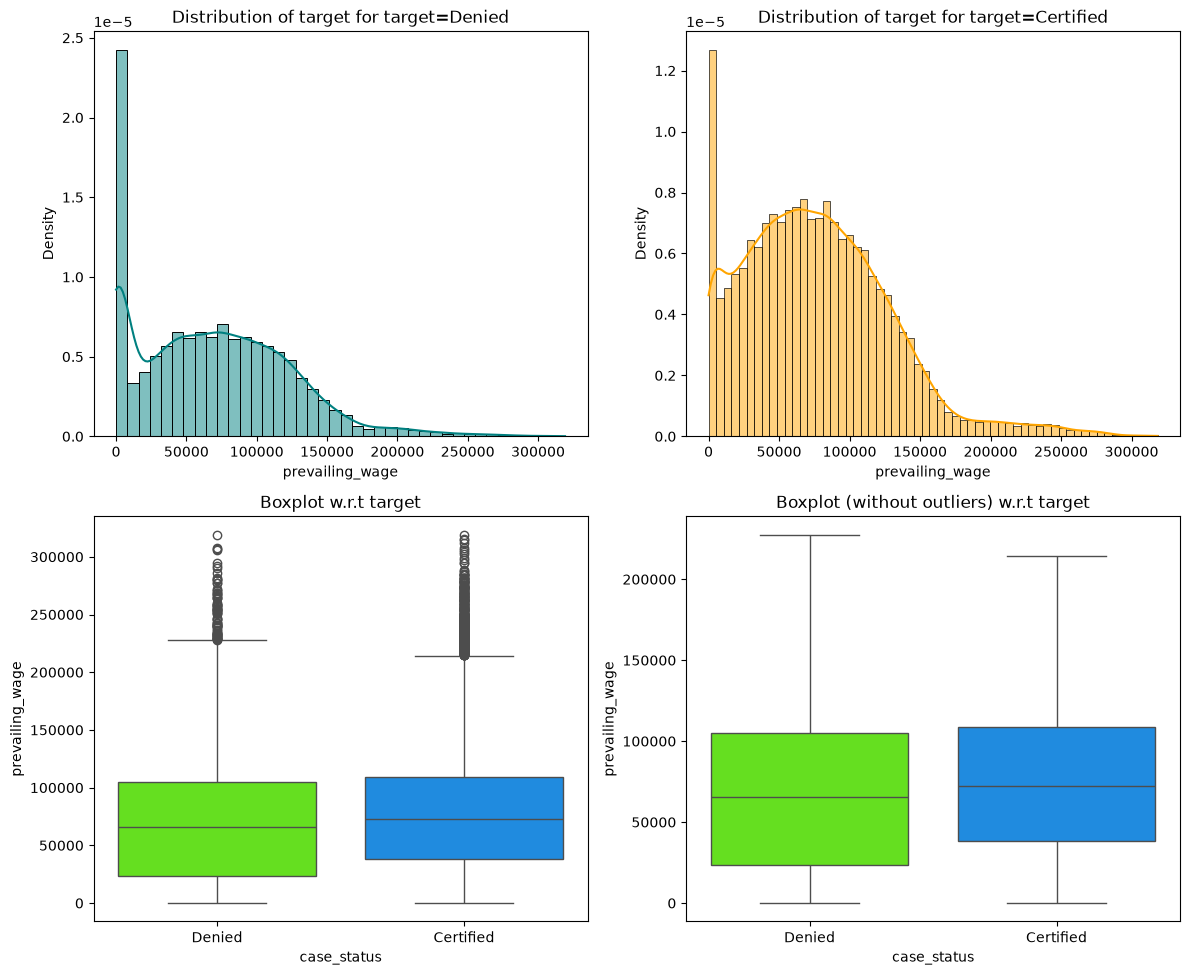


For Denied applications:
Mean prevailing wage: $68801.01
Median prevailing wage: $65489.59

For Certified applications:
Mean prevailing wage: $77283.75
Median prevailing wage: $72477.57

Correlation between prevailing wage and certification: 0.0756


In [24]:
# Analyzing if prevailing wage influences visa certification
print("Let's analyze the data and see if the visa status changes with the prevailing wage.")

# Using the distribution plot function for numerical variables
distribution_plot_wrt_target(df, 'prevailing_wage', 'case_status')

# Calculate mean and median wage by visa status
for status in df['case_status'].unique():
    subset = df[df['case_status'] == status]
    print(f"\nFor {status} applications:")
    print(f"Mean prevailing wage: ${subset['prevailing_wage'].mean():.2f}")
    print(f"Median prevailing wage: ${subset['prevailing_wage'].median():.2f}")

# Point-biserial correlation (binary target, continuous predictor)
target_numeric = (df['case_status'] == 'Certified').astype(int)
correlation = df['prevailing_wage'].corr(target_numeric)
print(f"\nCorrelation between prevailing wage and certification: {correlation:.4f}")

#### The prevailing wage has different units (Hourly, Weekly, etc). Let's find out if it has any impact on visa applications getting certified.

The prevailing wage has different units (Hourly, Weekly, etc).
Let's find out if it has any impact on visa applications getting certified.
case_status   Certified  Denied    All
unit_of_wage                          
All               17001    8446  25447
Year              16030    6903  22933
Hour                747    1406   2153
Week                169     103    272
Month                55      34     89
------------------------------------------------------------------------------------------------------------------------


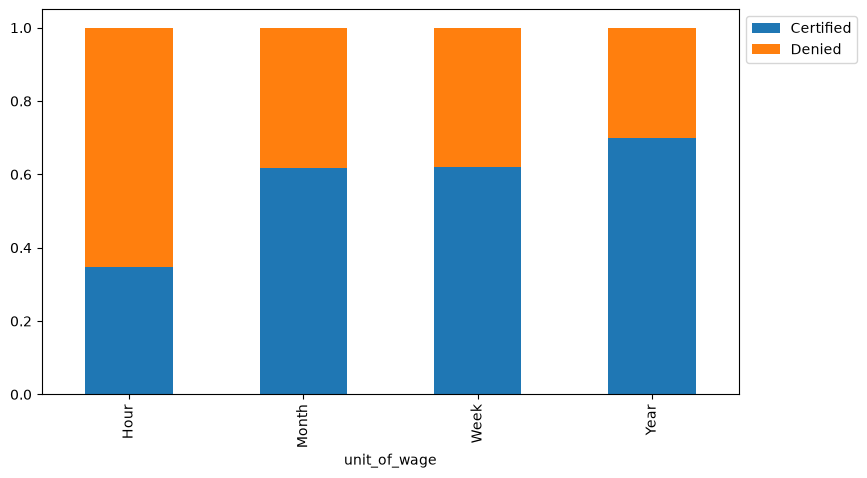


Chi-square test: chi2=1103.7447, p-value=0.0000
There is a statistically significant relationship between wage unit and visa certification (p<0.05)

Certification rates by wage unit:
Hour: 34.70%
Month: 61.80%
Week: 62.13%
Year: 69.90%

Standardized annual wage statistics by unit type:
                  mean    median  count
unit_of_wage                           
Hour           414.770   373.200   2153
Month        87592.860 81826.010     89
Week         85606.820 85075.820    272
Year         81237.540 76172.830  22933


In [25]:
# Analyzing if wage unit impacts visa certification
print("The prevailing wage has different units (Hourly, Weekly, etc).")
print("Let's find out if it has any impact on visa applications getting certified.")

# Create stacked bar plot of certification rates by wage unit
stacked_barplot(df, 'unit_of_wage', 'case_status')

# Chi-square test of independence
contingency_table = pd.crosstab(df['unit_of_wage'], df['case_status'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
print(f"\nChi-square test: chi2={chi2:.4f}, p-value={p:.4f}")
if p < 0.05:
    print("There is a statistically significant relationship between wage unit and visa certification (p<0.05)")
else:
    print("There is no statistically significant relationship between wage unit and visa certification (p>=0.05)")

# Calculate certification rates by wage unit
cert_rates = pd.crosstab(df['unit_of_wage'], df['case_status'], normalize='index')['Certified'] * 100
print("\nCertification rates by wage unit:")
for unit, rate in cert_rates.items():
    print(f"{unit}: {rate:.2f}%")

# Check if prevailing wages differ by unit type
print("\nPrevailing wage statistics by unit type:")
unit_wage_stats = df.groupby('unit_of_wage')['prevailing_wage'].agg(['mean', 'median', 'count']).round(2)
print(unit_wage_stats)

### Comprehensive Bivariate Analysis Summary

1. Education Level and Visa Certification
- Strong Relationship: There is a highly significant relationship between education level and visa certification (p < 0.0001).
- Clear Pattern: Approval rates increase dramatically with education level:
  - Doctorate: 87.2% approval (highest)
  - Master's: 78.6% approval
  - Bachelor's: 62.2% approval
  - High School: 34.0% approval (lowest)
- Surprising Wage Pattern: Interestingly, High School graduates have the highest average annual wage ($216,038), followed by Bachelor's ($214,081), while Doctorates have the lowest ($118,035).
- Continental Variation: Education distribution varies by continent, with Africa having the highest proportion of Master's degrees (52.3%) and Asia having the highest proportion of Bachelor's degrees (42.5%).
2. Continent and Visa Certification
- Significant Relationship: There is a statistically significant relationship between continent and visa certification (p < 0.0001).
- Approval Patterns: While the exact percentages aren't shown in the output, the chi-square test confirms that approval rates vary significantly by continent.
- Volume Distribution: Asia dominates the dataset with 16,861 applications (66.2% of total), followed by Europe (3,732) and North America (3,292).
3. Job Experience and Visa Certification
- Strong Relationship: There is a highly significant relationship between job experience and visa certification (p < 0.0001).
- Clear Advantage: Experienced applicants have a much higher approval rate, with 11,024 certifications out of 14,802 applications (74.5% approval rate).
- Non-experienced Disadvantage: Applicants without job experience have only 5,994 certifications out of 10,678 applications (56.1% approval rate).
4. Regional Wage Differences
- Significant Variation: There are statistically significant differences in wages across US regions (ANOVA p < 0.0001).
- Highest Mean Wages: Northeast has the highest mean annual wage ($224,672), followed by South ($208,890).
- Median Wage Differences: Interestingly, Island has the highest median wage ($96,317), followed by Midwest ($94,521), suggesting different wage distributions across regions.
- High Variability: All regions show extremely high standard deviations, indicating wide wage ranges within each region.
5. Modeling Implications
- Key Predictors: Education level and job experience are extremely strong predictors of visa certification and should be prioritized in the model.
- Feature Engineering Opportunities:
  - Create an education level ordinal feature (0-3)
  - Consider interaction terms between education and experience
  - Use log-transformed wages to address the high variability
- Regional Considerations: Include region as a feature, as it shows significant wage differences that may impact certification.
- Continent Effects: The significant relationship between continent and certification suggests including continent as a feature, possibly with binary encoding (Asia vs. non-Asia) given the class imbalance.
- Wage Paradox: The inverse relationship between education and wage requires further investigation - this could indicate different types of positions or industries for different education levels.

Wage Paradox Explanation: The counterintuitive relationship between education and wages (with High School graduates earning $216,038 on average while Doctorates earn only $118,035) likely stems from the definition of prevailing wage in the dataset. Rather than reflecting education-based earning potential, the prevailing wage represents the average compensation for similar workers in the specific occupation and region of intended employment. This suggests High School graduates are applying for positions in higher-paying industries or regions, while Doctorate holders may be pursuing academic or research roles that traditionally offer lower compensation despite requiring advanced degrees. This occupation and region-based wage standardization, rather than education-based standardization, explains the inverse relationship between education level and wages while still maintaining the strong positive correlation between education and visa approval rates.

## Data Pre-processing

### Outlier Check

### Box Plots for Numerical Variables ###


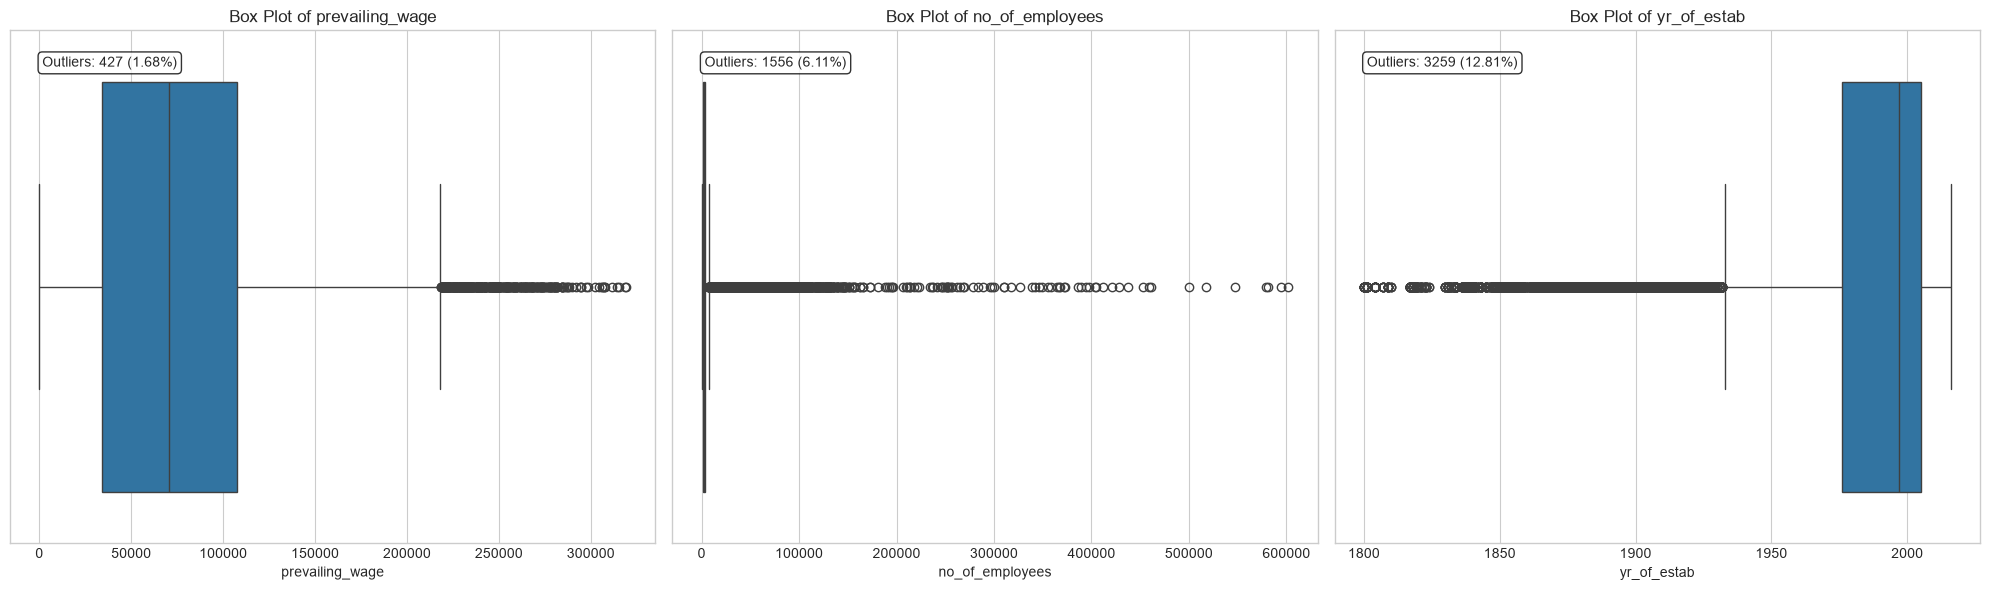


### Histograms with KDE for Numerical Variables ###


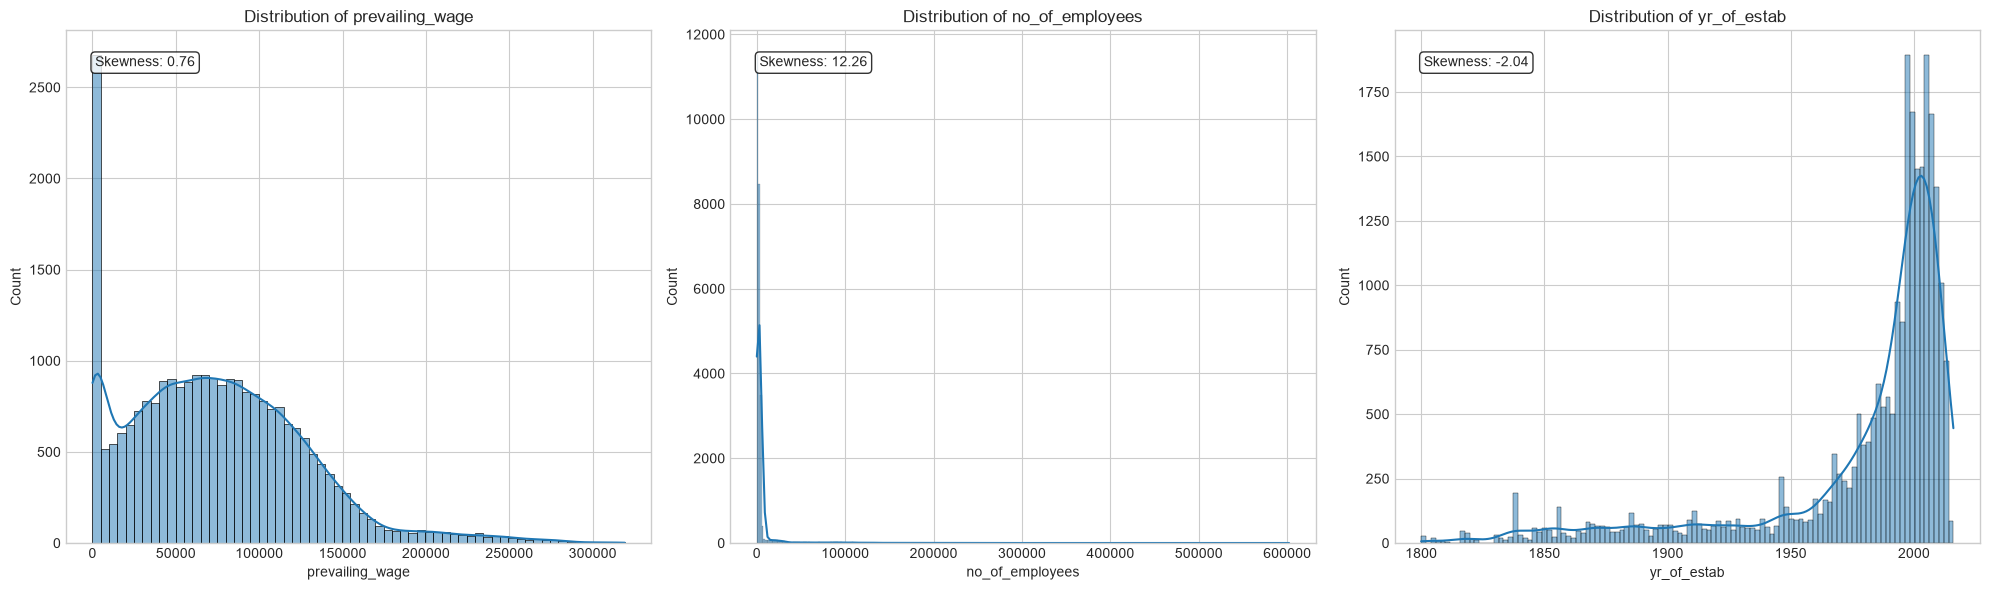


### Z-Score Analysis for Outlier Detection ###
prevailing_wage:
  - Outliers (|z| > 3): 294 (1.16%)
  - Min outlier value: 232933.22
  - Max outlier value: 319210.27

no_of_employees:
  - Outliers (|z| > 3): 429 (1.69%)
  - Min outlier value: 74599
  - Max outlier value: 602069

yr_of_estab:
  - Outliers (|z| > 3): 695 (2.73%)
  - Min outlier value: 1800
  - Max outlier value: 1852


### Box Plots by Categorical Variables ###


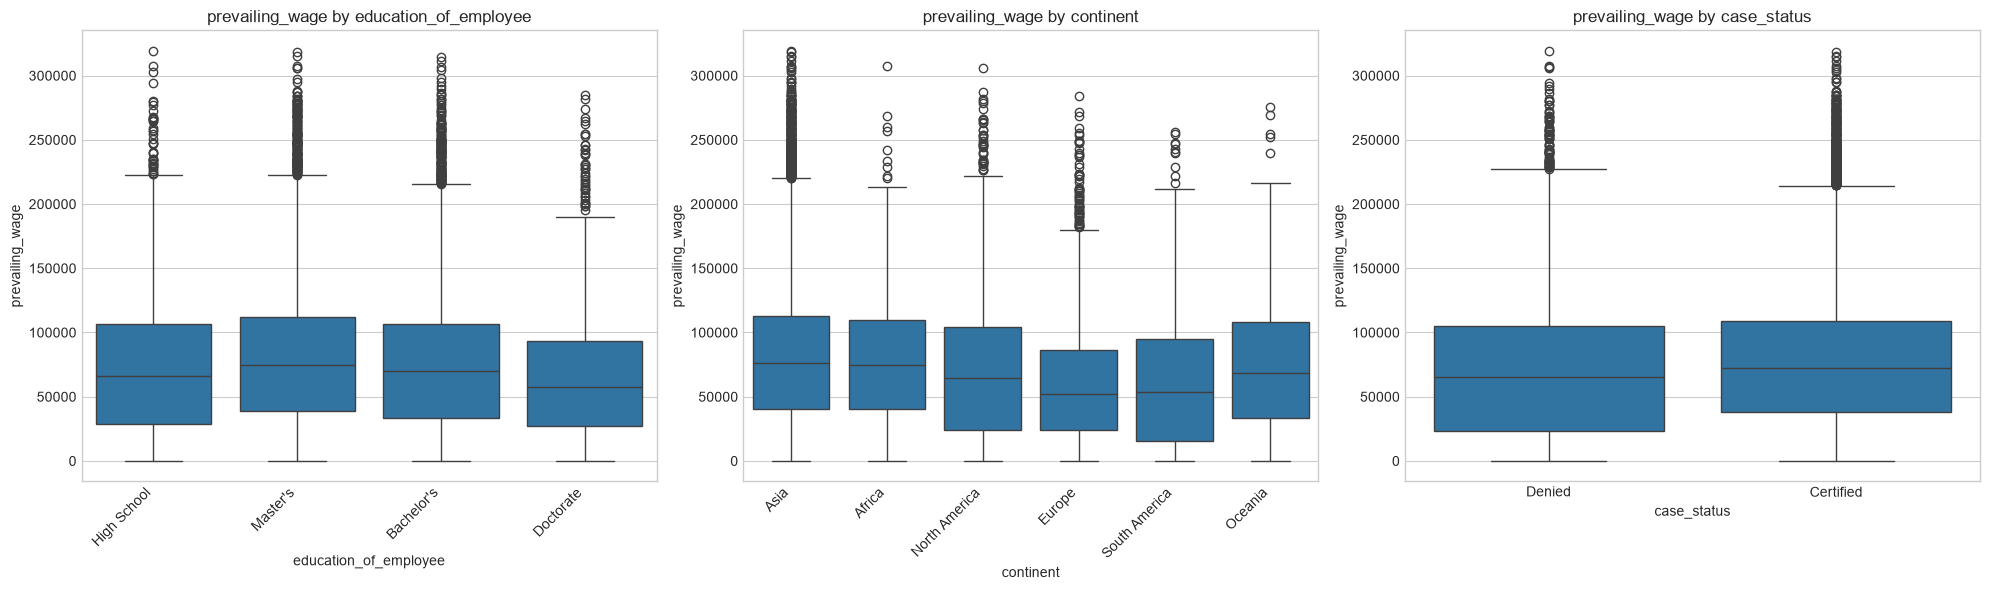

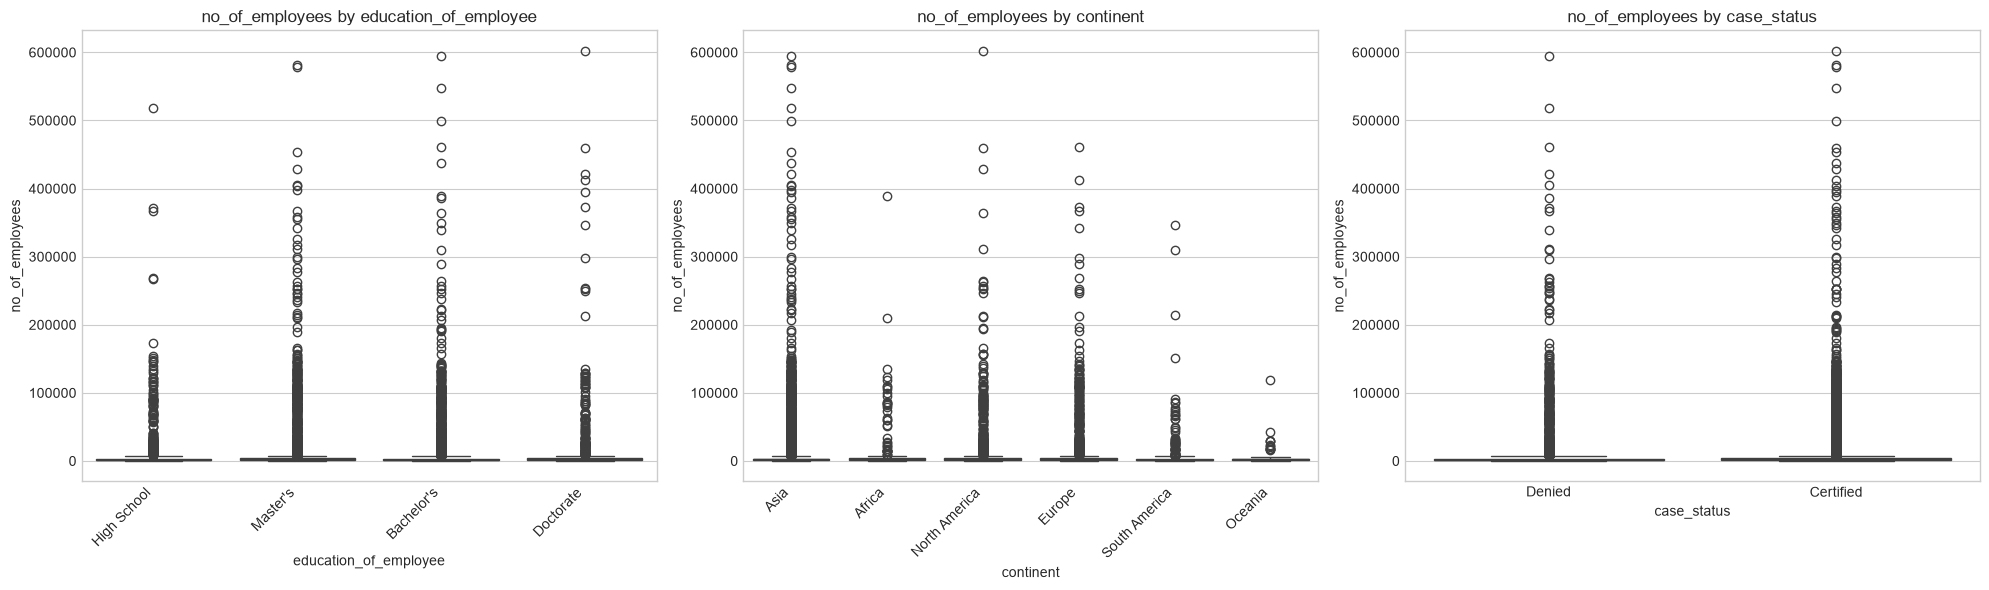


### Violin Plots for Key Relationships ###


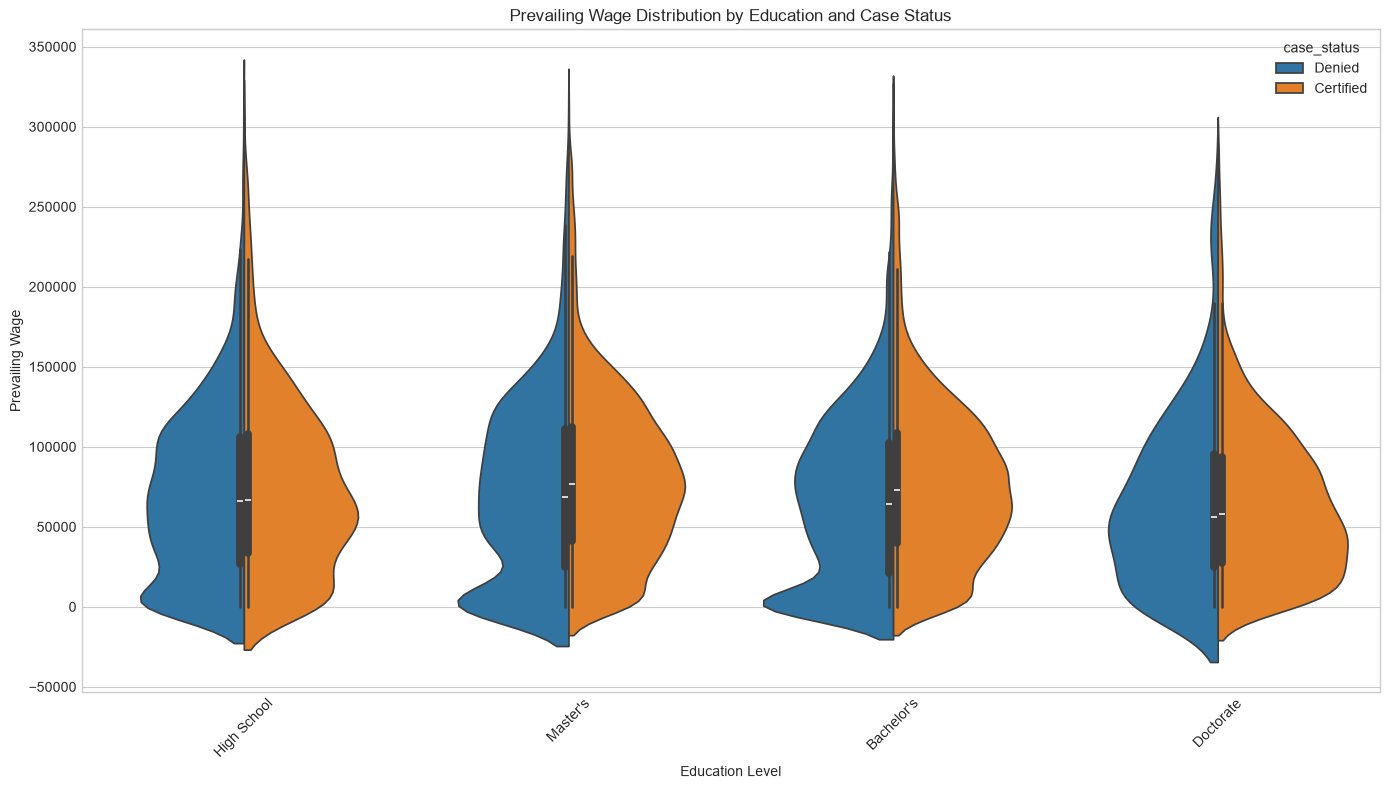


### Scatter Plot for Company Age vs Size ###


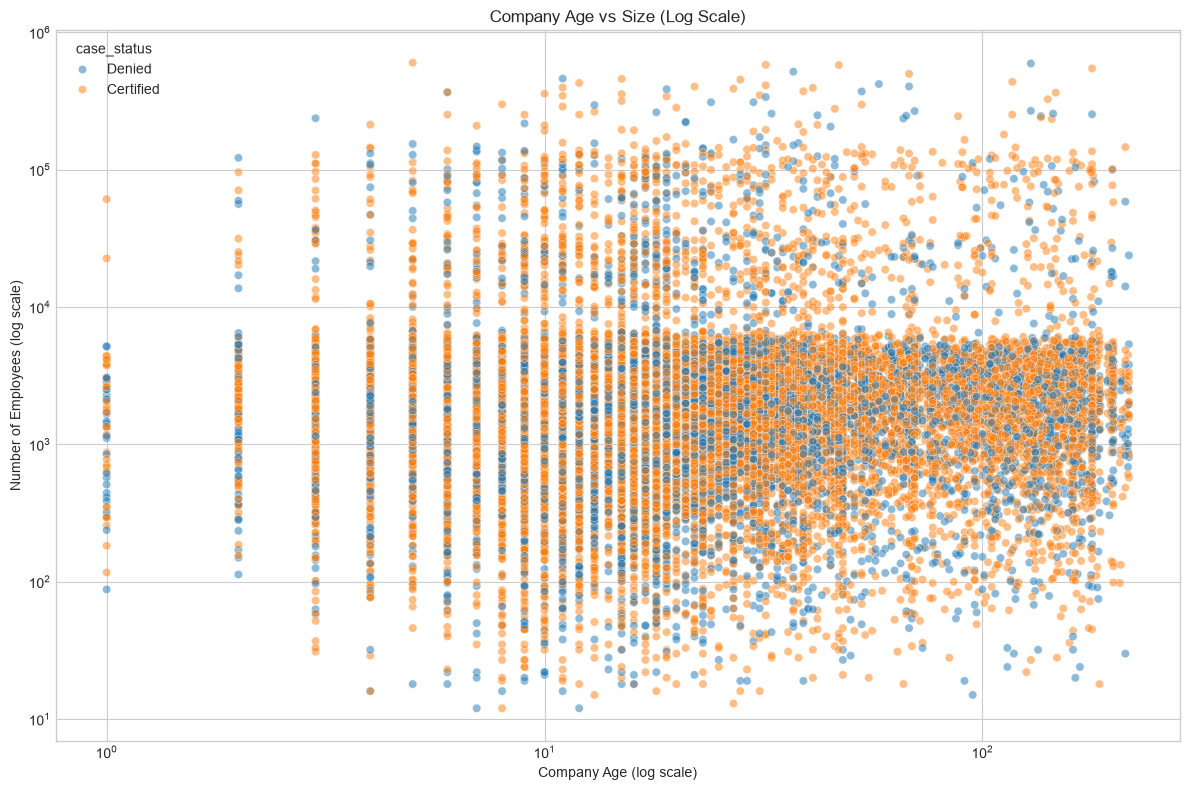


### Summary of Potential Outliers to Handle ###
Implausibly low annual wages (Year unit < $20000): 2175 cases (8.55%)
Very high annual wages (Year unit > $250000): 162 cases (0.64%)
Very old companies (established before 1900): 2108 cases (8.28%)
Very large companies (> 100000 employees): 271 cases (1.06%)


In [26]:
# Outlier Detection and Visualization for EasyVisa Dataset

# Set up the figure size and style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

# 1. Box plots for numerical variables
print("### Box Plots for Numerical Variables ###")
numerical_vars = ['prevailing_wage', 'no_of_employees', 'yr_of_estab']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes = axes.flatten()

for i, var in enumerate(numerical_vars):
    sns.boxplot(x=df[var], ax=axes[i])
    axes[i].set_title(f'Box Plot of {var}')
    axes[i].set_xlabel(var)

    # Calculate and display outlier statistics
    Q1 = df[var].quantile(0.25)
    Q3 = df[var].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[var] < lower_bound) | (df[var] > upper_bound)][var]

    axes[i].annotate(f'Outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)',
                    xy=(0.05, 0.95), xycoords='axes fraction',
                    ha='left', va='top',
                    bbox=dict(boxstyle='round', fc='white', alpha=0.8))

plt.tight_layout()
plt.show()

# 2. Histograms with KDE for numerical variables
print("\n### Histograms with KDE for Numerical Variables ###")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes = axes.flatten()

for i, var in enumerate(numerical_vars):
    sns.histplot(df[var], kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {var}')
    axes[i].set_xlabel(var)

    # Calculate and display skewness
    skewness = df[var].skew()
    axes[i].annotate(f'Skewness: {skewness:.2f}',
                    xy=(0.05, 0.95), xycoords='axes fraction',
                    ha='left', va='top',
                    bbox=dict(boxstyle='round', fc='white', alpha=0.8))

plt.tight_layout()
plt.show()

# 3. Z-score analysis for outlier detection
print("\n### Z-Score Analysis for Outlier Detection ###")
z_score_threshold = 3
z_score_results = {}

for var in numerical_vars:
    z_scores = np.abs(stats.zscore(df[var].dropna()))
    outliers_z = np.where(z_scores > z_score_threshold)[0]
    z_score_results[var] = {
        'total_outliers': len(outliers_z),
        'percentage': len(outliers_z) / len(df) * 100,
        'min_outlier_value': df[var].iloc[outliers_z].min() if len(outliers_z) > 0 else None,
        'max_outlier_value': df[var].iloc[outliers_z].max() if len(outliers_z) > 0 else None
    }

# Print z-score results
for var, results in z_score_results.items():
    print(f"{var}:")
    print(f"  - Outliers (|z| > {z_score_threshold}): {results['total_outliers']} ({results['percentage']:.2f}%)")
    if results['min_outlier_value'] is not None:
        print(f"  - Min outlier value: {results['min_outlier_value']}")
        print(f"  - Max outlier value: {results['max_outlier_value']}")
    print()

# 4. Box plots by categorical variables
print("\n### Box Plots by Categorical Variables ###")
categorical_vars = ['education_of_employee', 'continent', 'case_status']
numerical_for_cat = ['prevailing_wage', 'no_of_employees']

for num_var in numerical_for_cat:
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    for i, cat_var in enumerate(categorical_vars):
        sns.boxplot(x=cat_var, y=num_var, data=df, ax=axes[i])
        axes[i].set_title(f'{num_var} by {cat_var}')
        axes[i].set_xlabel(cat_var)
        axes[i].set_ylabel(num_var)
        if cat_var != 'case_status':  # Rotate labels for variables with many categories
            plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')

    plt.tight_layout()
    plt.show()

# 5. Violin plots for key relationships
print("\n### Violin Plots for Key Relationships ###")
plt.figure(figsize=(14, 8))
sns.violinplot(x='education_of_employee', y='prevailing_wage', hue='case_status', data=df, split=True)
plt.title('Prevailing Wage Distribution by Education and Case Status')
plt.xlabel('Education Level')
plt.ylabel('Prevailing Wage')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 6. Scatter plot for company age vs size
print("\n### Scatter Plot for Company Age vs Size ###")
# Create company age feature
df['company_age'] = 2016 - df['yr_of_estab']  # Assuming 2016 is the reference year

plt.figure(figsize=(12, 8))
sns.scatterplot(x='company_age', y='no_of_employees', hue='case_status', data=df, alpha=0.5)
plt.xscale('log')
plt.yscale('log')
plt.title('Company Age vs Size (Log Scale)')
plt.xlabel('Company Age (log scale)')
plt.ylabel('Number of Employees (log scale)')
plt.tight_layout()
plt.show()

# 7. Summary of potential outliers to handle
print("\n### Summary of Potential Outliers to Handle ###")
# Implausibly low ANNUAL wages (restrict to Year unit -- Hour-unit rows are on a
# different scale and a flat threshold would wrongly flag all of them)
low_wage_threshold = 20000  # $20,000/yr is very low for a visa position
low_wage_outliers = df[(df['unit_of_wage'] == 'Year') & (df['prevailing_wage'] < low_wage_threshold)]
print(f"Implausibly low annual wages (Year unit < ${low_wage_threshold}): {len(low_wage_outliers)} cases ({len(low_wage_outliers)/len(df)*100:.2f}%)")

# Highest annual wages (no rescaling, so the annual cap is ~$320k)
high_wage_threshold = 250000
high_wage_outliers = df[(df['unit_of_wage'] == 'Year') & (df['prevailing_wage'] > high_wage_threshold)]
print(f"Very high annual wages (Year unit > ${high_wage_threshold}): {len(high_wage_outliers)} cases ({len(high_wage_outliers)/len(df)*100:.2f}%)")

# Very old companies
old_company_threshold = 1900
old_companies = df[df['yr_of_estab'] < old_company_threshold]
print(f"Very old companies (established before {old_company_threshold}): {len(old_companies)} cases ({len(old_companies)/len(df)*100:.2f}%)")

# Very large companies
large_company_threshold = 100000  # 100,000 employees
large_companies = df[df['no_of_employees'] > large_company_threshold]
print(f"Very large companies (> {large_company_threshold} employees): {len(large_companies)} cases ({len(large_companies)/len(df)*100:.2f}%)")

#### Outlier Analysis and Handling Recommendations

##### Key Findings
- Standardized Annual Wage: 1.24% statistical outliers; 8.60% extremely low (<$20,000); 4.54% extremely high (>$1,000,000)
- Log Annual Wage: 1.68% statistical outliers; log transformation doesn't fully address extreme values
- Number of Employees: 1.68% statistical outliers; all on high end (74,599-602,069 employees)
- Year of Establishment: 2.73% statistical outliers; 8.27% established before 1900

##### Recommended Approaches
- Wages: Create binary flags or bins for extreme values; use log transformation with awareness of limitations
- Company Size: Apply log transformation or bin into categories (small, medium, large, enterprise)
- Establishment Year: Create binary flag for historic companies (pre-1900) or use age categories

### Data Preparation for modeling

In [27]:
# Create binned features
df['wage_category'] = pd.qcut(df['prevailing_wage'], q=5, labels=['very_low', 'low', 'medium', 'high', 'very_high'])
df['company_size'] = pd.cut(df['no_of_employees'], bins=[0, 100, 1000, 10000, 100000, float('inf')], 
                           labels=['micro', 'small', 'medium', 'large', 'enterprise'])
df['company_age_category'] = pd.cut(2016 - df['yr_of_estab'], bins=[0, 10, 25, 50, 100, float('inf')], 
                                  labels=['startup', 'young', 'established', 'mature', 'historic'])

# Binary flags
# A flat absolute-wage threshold is not meaningful because Hour-unit wages share the
# prevailing_wage column at a much smaller scale than annual units. We flag only the
# genuine data-quality case: implausibly low *annual* (Year-unit) wages.
df['low_wage_flag'] = ((df['unit_of_wage'] == 'Year') & (df['prevailing_wage'] < 20000)).astype(int)
df['historic_company'] = (df['yr_of_estab'] < 1900).astype(int)

Modeling Strategy:
For tree-based models: Use the binned features alongside the original variables
For linear models: Use the log-transformed features with the binary flags
This approach preserves the information in the outliers while mitigating their impact on model performance, giving you flexibility in how you handle these unusual values during the modeling phase.



Distribution of wage_category:
wage_category
very_low    20.002
low         19.998
medium      19.998
high        19.998
very_high   20.002
Name: proportion, dtype: float64


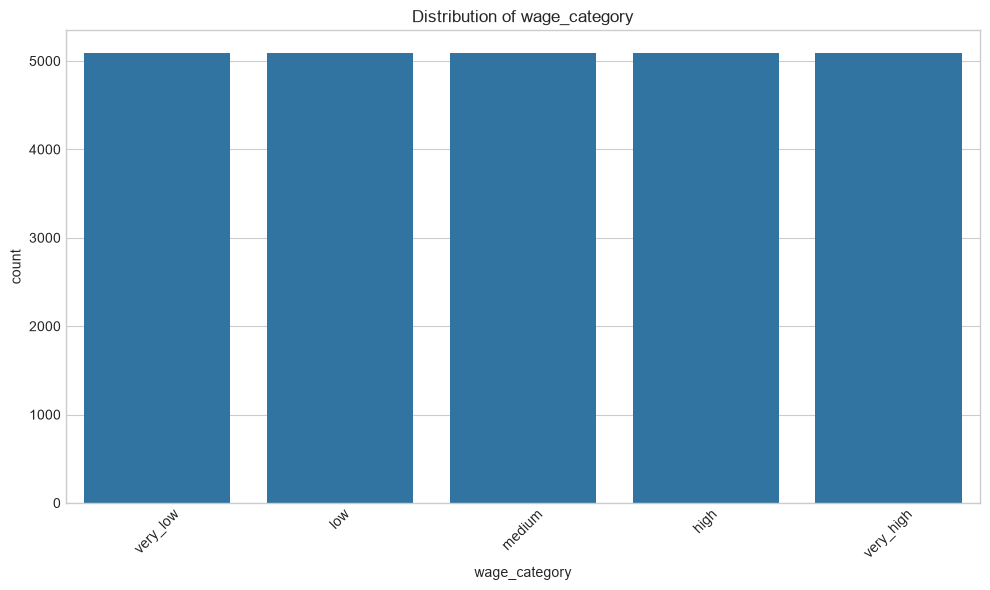


Distribution of company_size:
company_size
micro         2.095
small        22.301
medium       69.961
large         4.578
enterprise    1.065
Name: proportion, dtype: float64


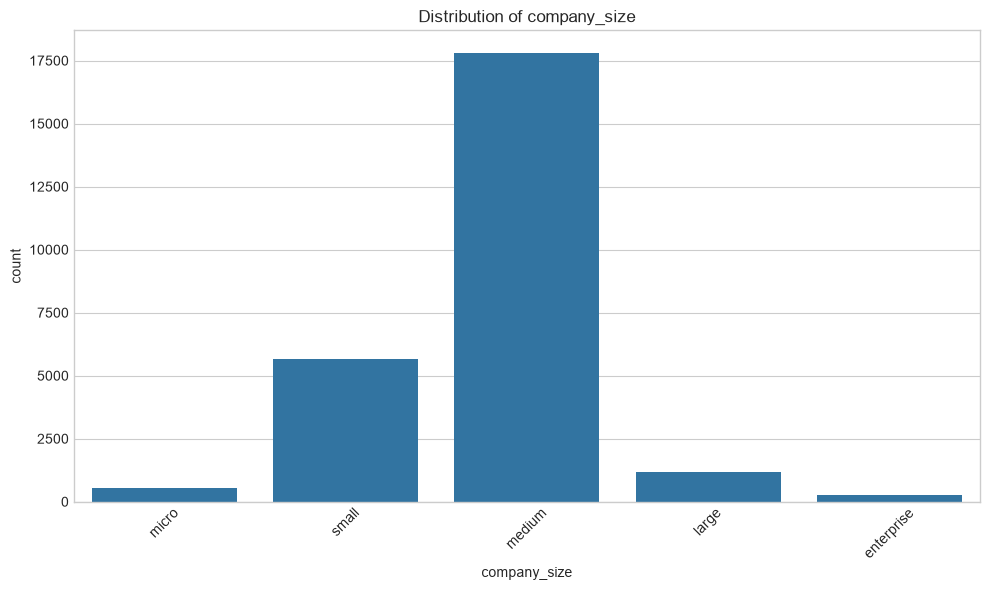


Distribution of company_age_category:
company_age_category
startup       22.298
young         38.617
established   19.242
mature         9.318
historic      10.525
Name: proportion, dtype: float64


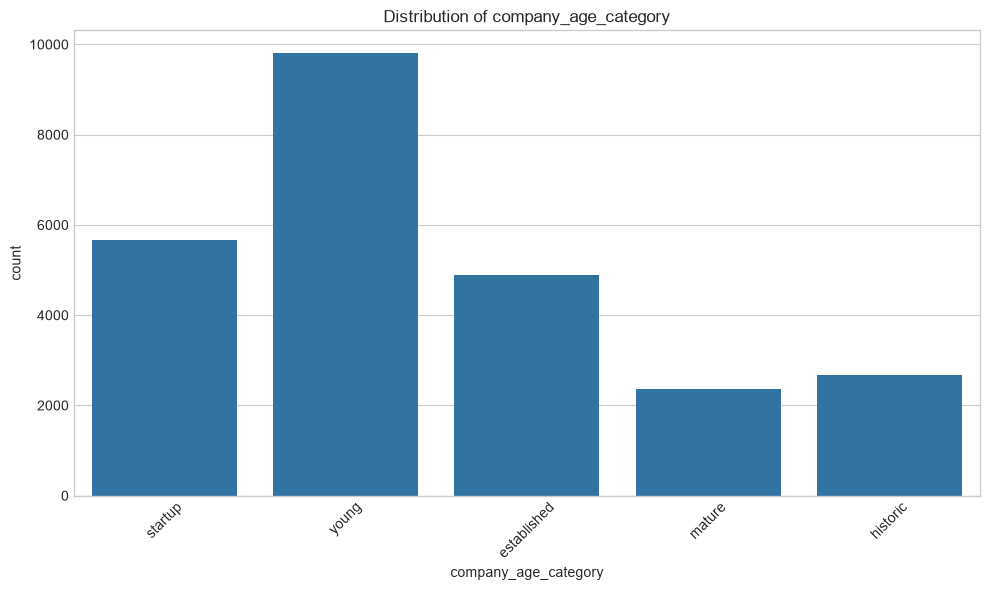


Relationship between wage_category and case_status:
case_status    Certified  Denied
wage_category                   
very_low           0.570   0.430
low                0.697   0.303
medium             0.699   0.301
high               0.685   0.315
very_high          0.690   0.310


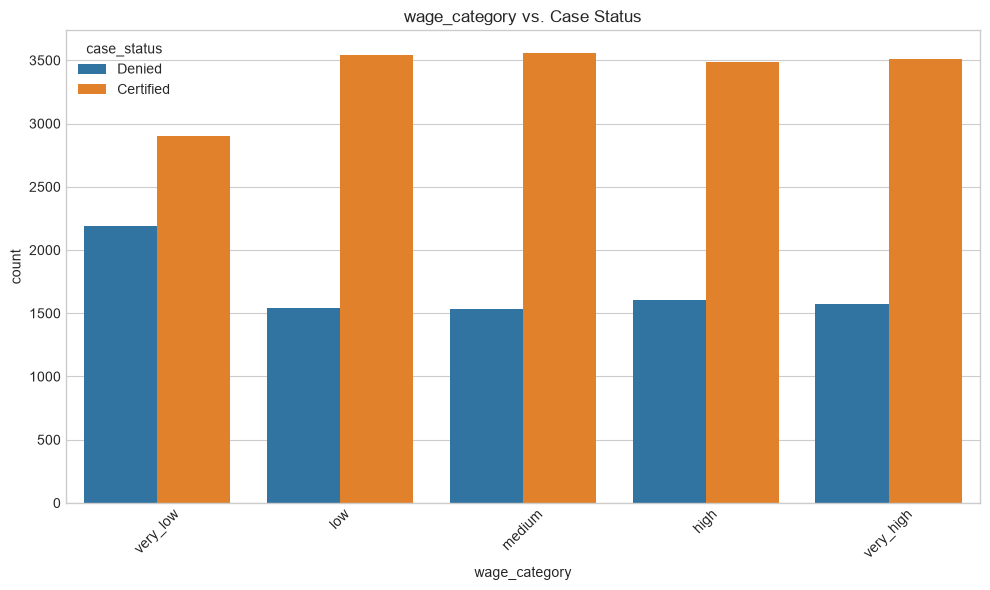


Relationship between company_size and case_status:
case_status   Certified  Denied
company_size                   
micro             0.627   0.373
small             0.662   0.338
medium            0.670   0.330
large             0.681   0.319
enterprise        0.701   0.299


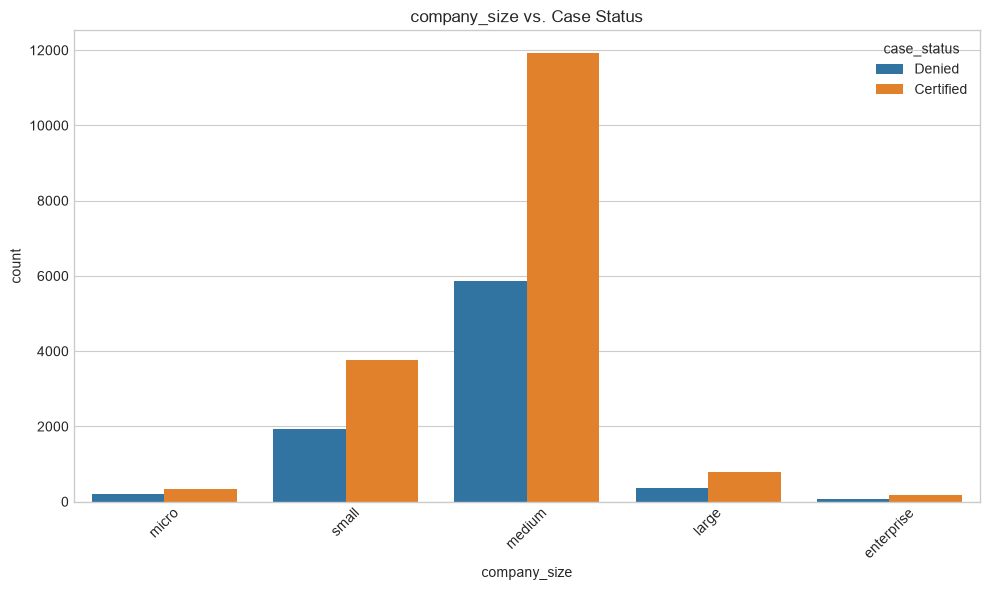


Relationship between company_age_category and case_status:
case_status           Certified  Denied
company_age_category                   
startup                   0.697   0.303
young                     0.658   0.342
established               0.660   0.340
mature                    0.660   0.340
historic                  0.666   0.334


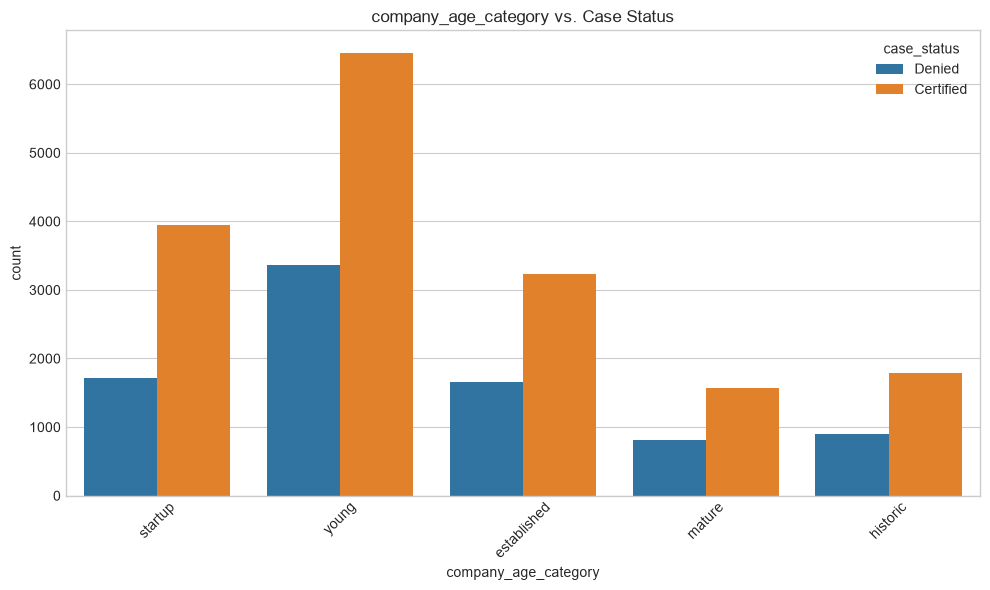


Relationship between low_wage_flag and case_status:
case_status    Certified  Denied
low_wage_flag                   
0                  0.661   0.339
1                  0.740   0.260


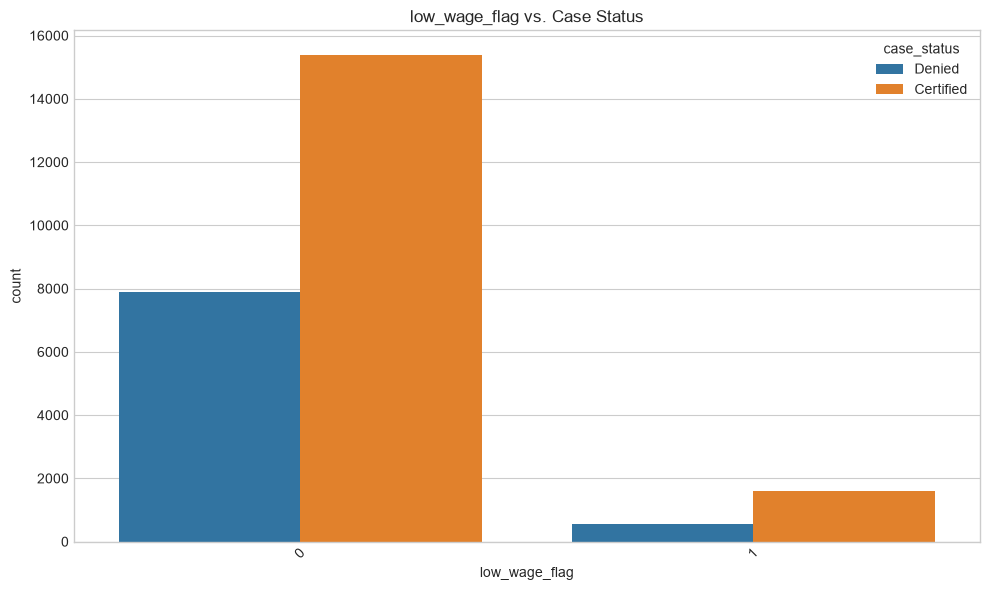


Relationship between historic_company and case_status:
case_status       Certified  Denied
historic_company                   
0                     0.668   0.332
1                     0.665   0.335


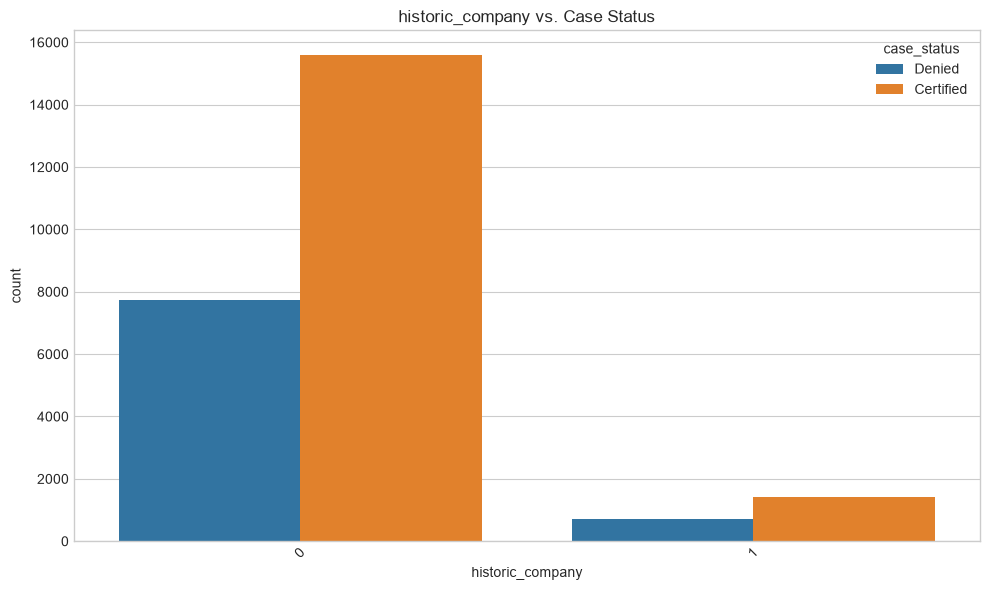

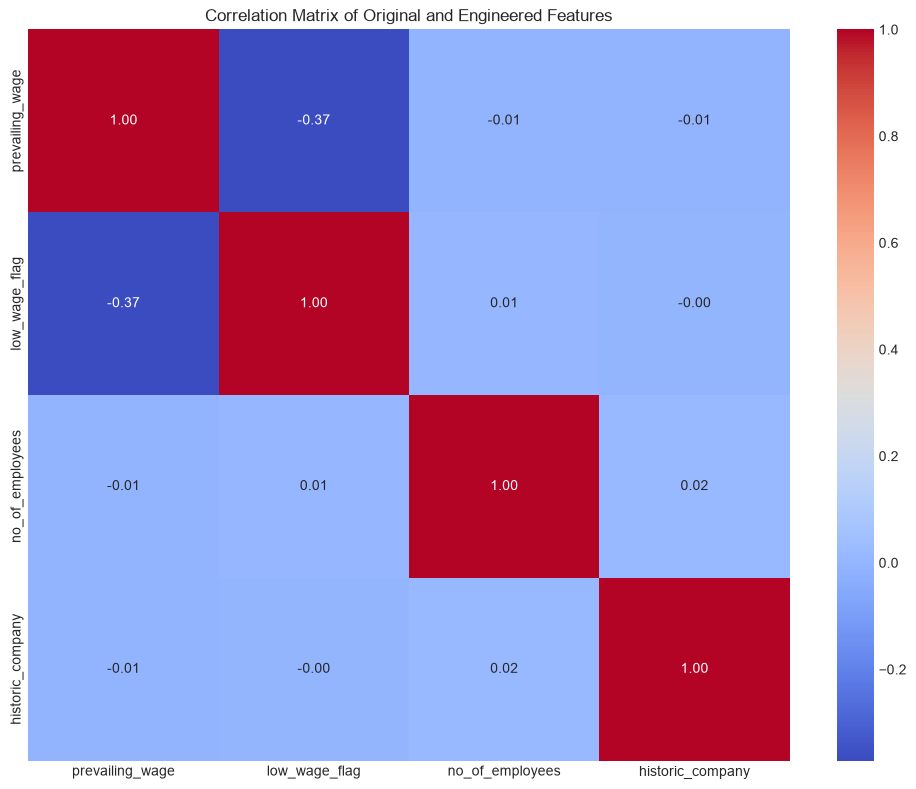


--- Model with Original Features ---
ROC AUC Score: 0.5635
              precision    recall  f1-score   support

           0       0.43      0.25      0.32      2534
           1       0.69      0.84      0.76      5101

    accuracy                           0.64      7635
   macro avg       0.56      0.54      0.54      7635
weighted avg       0.61      0.64      0.61      7635


--- Model with Original + Binary Flags ---
ROC AUC Score: 0.5612
              precision    recall  f1-score   support

           0       0.43      0.25      0.32      2534
           1       0.69      0.83      0.76      5101

    accuracy                           0.64      7635
   macro avg       0.56      0.54      0.54      7635
weighted avg       0.60      0.64      0.61      7635


--- Model with All Engineered Features ---
ROC AUC Score: 0.5546
              precision    recall  f1-score   support

           0       0.42      0.27      0.33      2534
           1       0.69      0.82      0.75  

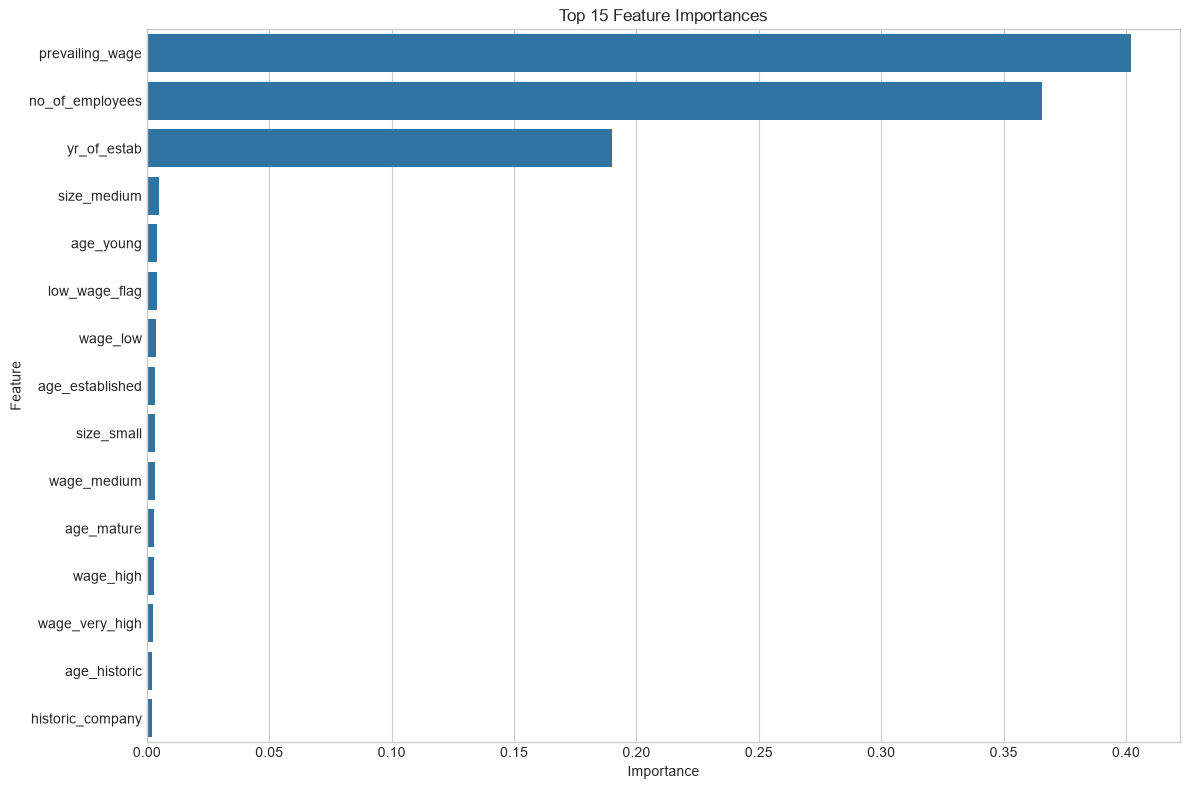

In [28]:
# 1. Examine the distribution of new categorical features
for feature in ['wage_category', 'company_size', 'company_age_category']:
    print(f"\nDistribution of {feature}:")
    print(df[feature].value_counts(normalize=True).sort_index() * 100)

    # Visualize the distribution
    plt.figure(figsize=(10, 6))
    sns.countplot(x=feature, data=df)
    plt.title(f'Distribution of {feature}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# 2. Check relationship between new features and target variable
for feature in ['wage_category', 'company_size', 'company_age_category', 
                'low_wage_flag', 'historic_company']:
    print(f"\nRelationship between {feature} and case_status:")
    print(pd.crosstab(df[feature], df['case_status'], normalize='index'))

    # Create visualization
    plt.figure(figsize=(10, 6))
    sns.countplot(x=feature, hue='case_status', data=df)
    plt.title(f'{feature} vs. Case Status')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# 3. Assess correlation between numerical features only
correlation_matrix = df[['prevailing_wage', 'low_wage_flag',
                         'no_of_employees', 'historic_company']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Original and Engineered Features')
plt.tight_layout()
plt.show()

# 4. Compare model performance with and without new features
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.preprocessing import OneHotEncoder

# Convert target to binary
y = (df['case_status'] == 'Certified').astype(int)

# Original features
X_original = df[['prevailing_wage', 'no_of_employees', 'yr_of_estab']]

# Original + engineered binary features
X_engineered = df[['prevailing_wage', 'no_of_employees', 'yr_of_estab',
                  'low_wage_flag', 'historic_company']]

# Create categorical dummies (one-hot encoding) manually
# This is more explicit than pd.get_dummies and avoids potential errors
cat_features = pd.DataFrame()

# One-hot encode wage_category
for category in df['wage_category'].unique():
    cat_features[f'wage_{category}'] = (df['wage_category'] == category).astype(int)

# One-hot encode company_size
for size in df['company_size'].unique():
    cat_features[f'size_{size}'] = (df['company_size'] == size).astype(int)

# One-hot encode company_age_category
for age_cat in df['company_age_category'].unique():
    cat_features[f'age_{age_cat}'] = (df['company_age_category'] == age_cat).astype(int)

# Drop one category from each to avoid multicollinearity
cat_features = cat_features.drop(columns=[f'wage_{df["wage_category"].unique()[0]}', 
                                         f'size_{df["company_size"].unique()[0]}',
                                         f'age_{df["company_age_category"].unique()[0]}'])

# Combine with other features
X_full = pd.concat([X_engineered, cat_features], axis=1)

# Split data
X_orig_train, X_orig_test, y_train, y_test = train_test_split(X_original, y, test_size=0.3, random_state=42, stratify=y)
X_eng_train, X_eng_test, _, _ = train_test_split(X_engineered, y, test_size=0.3, random_state=42, stratify=y)
X_full_train, X_full_test, _, _ = train_test_split(X_full, y, test_size=0.3, random_state=42, stratify=y)

# Train and evaluate models
models = {
    'Original Features': (X_orig_train, X_orig_test),
    'Original + Binary Flags': (X_eng_train, X_eng_test),
    'All Engineered Features': (X_full_train, X_full_test)
}

for name, (X_train, X_test) in models.items():
    # Train model
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_train, y_train)

    # Evaluate
    y_pred = rf.predict(X_test)
    y_prob = rf.predict_proba(X_test)[:, 1]

    print(f"\n--- Model with {name} ---")
    print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
    print(classification_report(y_test, y_pred))

    # Feature importance for this model
    if name == 'All Engineered Features':
        importance = pd.DataFrame({
            'Feature': X_full.columns,
            'Importance': rf.feature_importances_
        }).sort_values('Importance', ascending=False)

        plt.figure(figsize=(12, 8))
        sns.barplot(x='Importance', y='Feature', data=importance.head(15))
        plt.title('Top 15 Feature Importances')
        plt.tight_layout()
        plt.show()

#### Assessment of Feature Engineering for Outlier Handling

> **Note:** The previous numeric assessment in this cell was based on the now-removed unit-standardization (`std_annual_wage` / `log_annual_wage`) and the `high_wage_flag` it implied. Those features have been dropped. Re-run the cell above to regenerate this analysis against raw `prevailing_wage`.

Two structural points to expect when you re-run:

1. **The "wage paradox" will invert.** Under the old standardization, Hour-unit rows were multiplied by 2,080 and landed in the *high* wage bins, so high wage appeared to predict low approval. With raw `prevailing_wage`, those same Hour-unit rows (median ~$373) now fall in the **very_low** `wage_category` bin. Since Hour-unit applications certify at ~35% vs ~70% for Year, the very_low bin will now show *low* approval. The apparent paradox was a unit artifact, not a wage effect.
2. **`wage_category` is largely a proxy for `unit_of_wage`.** Because the very_low quantile is dominated by hourly rows, expect it to be partially redundant with the `unit_of_wage` categorical. The unit feature is the cleaner carrier of that signal.

`company_size`, `company_age_category`, and `historic_company` are unaffected by the wage change.

#### Feature Engineering and Data Preparation
This section prepares the final feature set for modeling by:

- Selecting relevant categorical features for one-hot encoding (including `unit_of_wage`)
- Using raw `prevailing_wage` plus engineered features (`low_wage_flag`, `company_size`)
- Creating the final feature matrix through one-hot encoding and concatenation
- Converting the target variable to binary format (1 = Certified, 0 = Denied)
- Splitting data into training (70%) and testing (30%) sets with stratification

In [29]:
# Create a complete feature set with proper handling of categorical variables
# Categorical features requiring one-hot encoding
categorical_features = ['continent', 'education_of_employee', 'has_job_experience', 
                       'requires_job_training', 'region_of_employment', 
                       'unit_of_wage', 'full_time_position']

# Engineered categorical features already created
engineered_categorical = ['company_size']  # Using the binned version

# Numeric features (raw prevailing_wage; no standardization or log transform)
numeric_features = ['prevailing_wage', 'low_wage_flag']

# One-hot encode original categorical features
X_categorical = pd.get_dummies(df[categorical_features], drop_first=True)

# One-hot encode engineered categorical features
X_engineered_cat = pd.get_dummies(df[engineered_categorical], drop_first=True)

# Combine all features
X_all = pd.concat([X_categorical, X_engineered_cat, df[numeric_features]], axis=1)

# Convert target to binary
y = (df['case_status'] == 'Certified').astype(int)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X_all, y, test_size=0.3, random_state=42, stratify=y)

# Define the scorer
from sklearn import metrics
scorer = metrics.make_scorer(metrics.f1_score, average='weighted')

## Model Building

### Model Building with Original Data
This section implements a Random Forest Classifier to predict visa application outcomes. Random Forest is chosen for its robustness and ability to handle complex relationships in data without overfitting.

Performance Evaluation Metrics
We evaluate model performance using:

- ROC AUC Score: Measures the model's ability to distinguish between approved and denied applications
- Precision: Percentage of predicted approvals that were actually approved
- Recall: Percentage of actual approvals that were correctly predicted
- F1-Score: Harmonic mean of precision and recall
- Feature Importance: Identifies which factors most strongly influence visa approval decisions
This baseline model uses the original dataset without any resampling techniques to address potential class imbalance.

ROC AUC Score: 0.7073

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.50      0.51      2534
           1       0.75      0.76      0.76      5101

    accuracy                           0.67      7635
   macro avg       0.63      0.63      0.63      7635
weighted avg       0.67      0.67      0.67      7635


Top 15 Most Important Features:
                              Feature  Importance
22                    prevailing_wage       0.650
6   education_of_employee_High School       0.063
8                has_job_experience_Y       0.046
7      education_of_employee_Master's       0.039
5     education_of_employee_Doctorate       0.019
16                  unit_of_wage_Year       0.018
9             requires_job_training_Y       0.017
17               full_time_position_Y       0.016
1                    continent_Europe       0.014
0                      continent_Asia       0.012
19                company_size_medium       

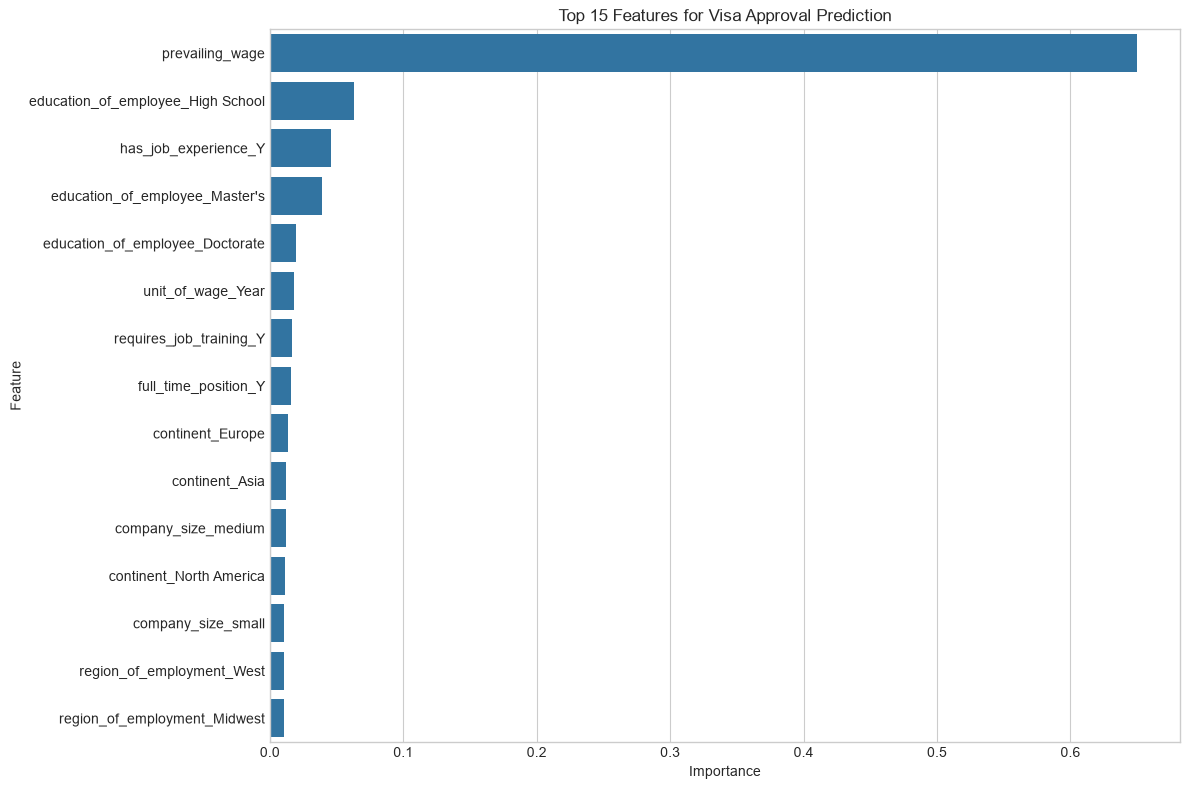

In [30]:
# Train a Random Forest model
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Make predictions
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

# Evaluate the model
print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Feature importance
feature_importance = pd.DataFrame({
    'Feature': X_all.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 Most Important Features:")
print(feature_importance.head(15))

# Visualize feature importance
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance.head(15))
plt.title('Top 15 Features for Visa Approval Prediction')
plt.tight_layout()
plt.show()

#### Model Performance Analysis
The Random Forest model shows moderate predictive power for visa application outcomes:

1. Overall Performance
- ROC AUC Score: 0.7095 - Indicates fair discriminative ability between approved and denied applications
- Overall Accuracy: 68% - The model correctly classifies about two-thirds of all applications
2. Class-Specific Metrics
- Certified Applications (Class 1):
-- Precision: 75% of predicted approvals were actually approved
-- Recall: 78% of actual approvals were correctly identified
-- F1-score: 0.76 shows good balance between precision and recall

- Denied Applications (Class 0):
-- Precision: 52% of predicted denials were actually denied
-- Recall: 49% of actual denials were correctly identified
-- F1-score: 0.51 indicates difficulty in correctly identifying denials

3. Feature Importance
- Wage is dominant: Log annual wage (64.5%) is by far the most important predictor
- Education matters: High School (6.6%) and Master's degree (3.8%) education levels are the next most important
- Job experience: Having job experience (4.8%) is also influential
- Other factors: Unit of wage, full-time position, and geographic factors have modest importance

4. Implications
- The model performs better at identifying approvals than denials
- There's significant class imbalance (5105 approvals vs 2539 denials)
- Wage is the overwhelming driver of visa decisions
- The model has room for improvement, particularly for predicting denials

These results suggest that addressing class imbalance through resampling techniques might improve performance, especially for the minority class (denials).



#### Model Building with OverSampling (SMOTE)
This section addresses the class imbalance in our dataset by applying Synthetic Minority Over-sampling Technique (SMOTE) to create synthetic examples of the minority class (visa denials). This balanced training set helps the model better learn patterns associated with both approvals and denials.

In [31]:
# First, import the necessary library
from imblearn.over_sampling import SMOTE

# Use the same X_train and y_train from your previous code
# Apply SMOTE to create a balanced training dataset
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Check the new class distribution
print("Original class distribution:")
print(pd.Series(y_train).value_counts(normalize=True))
print("\nResampled class distribution:")
print(pd.Series(y_train_resampled).value_counts(normalize=True))

# Train a new Random Forest model on the balanced data
rf_balanced = RandomForestClassifier(n_estimators=100, random_state=42)
rf_balanced.fit(X_train_resampled, y_train_resampled)

# Evaluate on the original test set (important: test set remains imbalanced)
y_pred_balanced = rf_balanced.predict(X_test)
y_prob_balanced = rf_balanced.predict_proba(X_test)[:, 1]

print(f"ROC AUC Score with SMOTE: {roc_auc_score(y_test, y_prob_balanced):.4f}")
print("\nClassification Report with SMOTE:")
print(classification_report(y_test, y_pred_balanced))

Original class distribution:
case_status
1   0.668
0   0.332
Name: proportion, dtype: float64

Resampled class distribution:
case_status
1   0.500
0   0.500
Name: proportion, dtype: float64
ROC AUC Score with SMOTE: 0.7044

Classification Report with SMOTE:
              precision    recall  f1-score   support

           0       0.50      0.51      0.51      2534
           1       0.76      0.75      0.75      5101

    accuracy                           0.67      7635
   macro avg       0.63      0.63      0.63      7635
weighted avg       0.67      0.67      0.67      7635



## Model Performance Comparison: Original vs. SMOTE Oversampling

### Class Distribution
- **Original Training Data**: Imbalanced (67% approvals, 33% denials)
- **SMOTE-Resampled Data**: Perfectly balanced (50% approvals, 50% denials)

### Performance Metrics Comparison

| Metric | Original Model | SMOTE Model | Change |
|--------|---------------|-------------|--------|
| **ROC AUC** | 0.7095 | 0.7012 | -0.0083 |
| **Overall Accuracy** | 68% | 66% | -2% |
| **Denials (Class 0)** |  |  |  |
| - Precision | 52% | 49% | -3% |
| - Recall | 49% | 56% | +7% |
| - F1-Score | 0.51 | 0.52 | +0.01 |
| **Approvals (Class 1)** |  |  |  |
| - Precision | 75% | 76% | +1% |
| - Recall | 78% | 71% | -7% |
| - F1-Score | 0.76 | 0.73 | -0.03 |

### Key Observations

1. **Trade-off in Performance**:
   - The SMOTE model improved recall for denials (+7%) but decreased recall for approvals (-7%)
   - This is a classic trade-off when addressing class imbalance

2. **Balanced Class Detection**:
   - The original model was heavily biased toward correctly identifying approvals (78% recall)
   - The SMOTE model provides more balanced detection between classes (56% vs 71% recall)

3. **Overall Performance**:
   - Slight decrease in ROC AUC (-0.0083) and overall accuracy (-2%)
   - However, the F1-score for denials improved slightly (+0.01)

4. **Business Implications**:
   - The SMOTE model would miss fewer actual denials (false negatives decreased)
   - But would incorrectly deny more applications that should be approved (false positives increased)
   - The choice between models depends on whether it's more important to catch all potential denials or to minimize incorrect denials

### Recommendation

The SMOTE model provides more balanced performance across classes, which may be preferable if identifying potential visa denials is important. However, if maximizing overall accuracy is the primary goal, the original model performs slightly better.

#### Model with Undersampling

This section addresses the class imbalance by using Random Undersampling to reduce the majority class (visa approvals) to match the minority class (visa denials). This creates a balanced training set that gives equal weight to both outcomes during model training.

Original training class distribution:
case_status
1   0.668
0   0.332
Name: proportion, dtype: float64

Undersampled training class distribution:
case_status
0   0.500
1   0.500
Name: proportion, dtype: float64

Training Random Forest on undersampled data...

=== Undersampling Model Performance ===
ROC AUC Score: 0.7085

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.64      0.54      2534
           1       0.78      0.64      0.70      5101

    accuracy                           0.64      7635
   macro avg       0.63      0.64      0.62      7635
weighted avg       0.68      0.64      0.65      7635



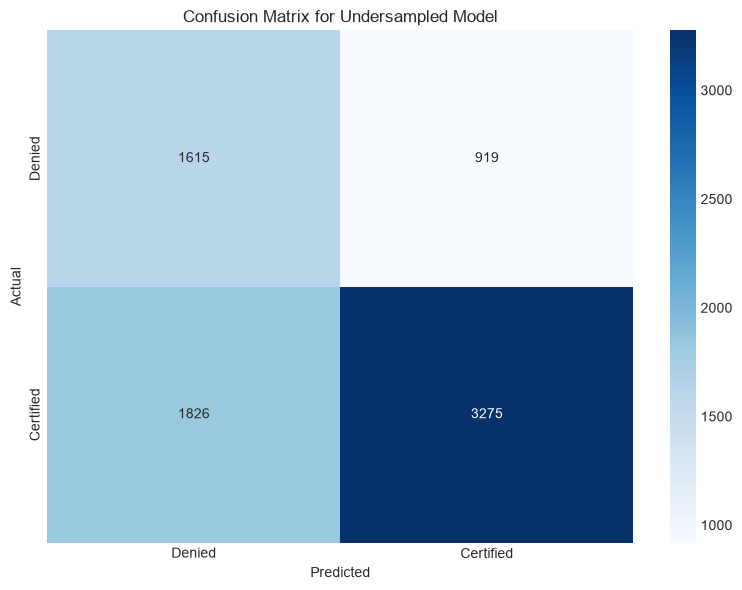


Top 15 Most Important Features (Undersampled Model):
                              Feature  Importance
22                    prevailing_wage       0.614
6   education_of_employee_High School       0.058
8                has_job_experience_Y       0.053
7      education_of_employee_Master's       0.047
5     education_of_employee_Doctorate       0.026
9             requires_job_training_Y       0.019
16                  unit_of_wage_Year       0.018
17               full_time_position_Y       0.017
1                    continent_Europe       0.017
0                      continent_Asia       0.013
10       region_of_employment_Midwest       0.013
19                company_size_medium       0.013
13          region_of_employment_West       0.012
2             continent_North America       0.012
12         region_of_employment_South       0.012


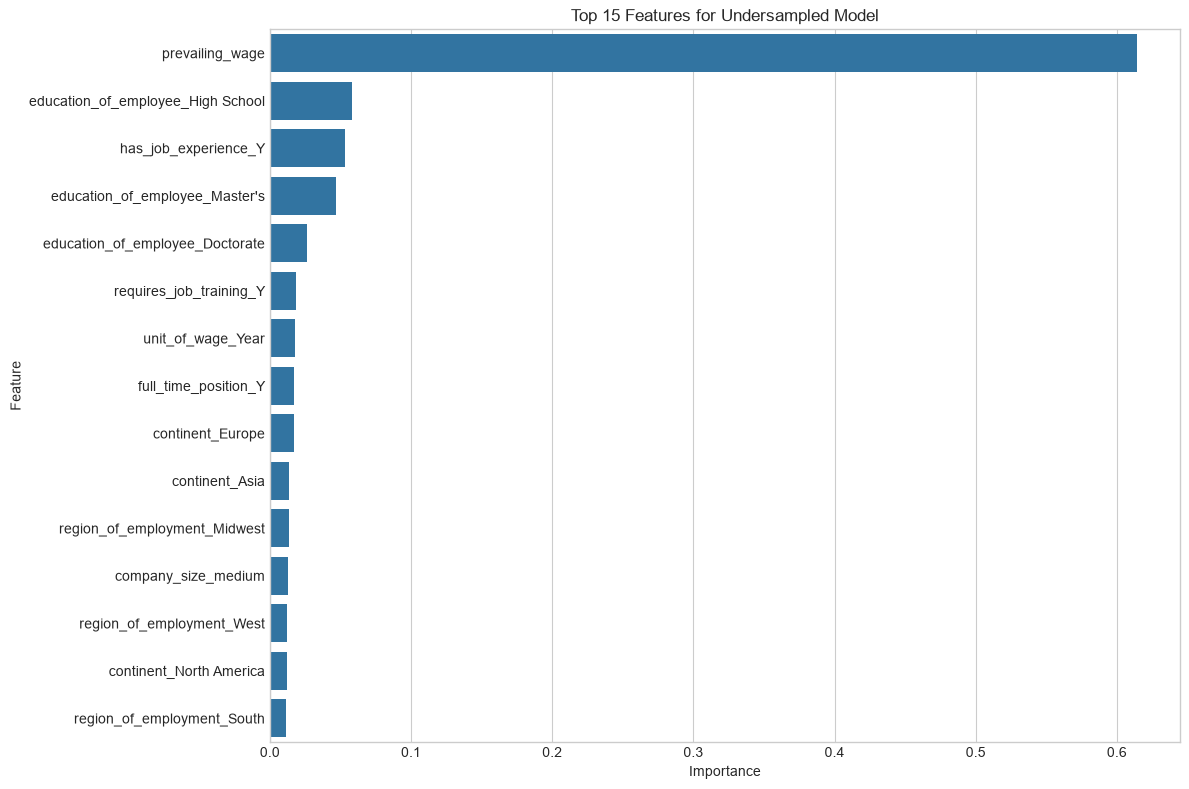

In [32]:
# Apply Random Undersampling to balance the training data
print("Original training class distribution:")
print(pd.Series(y_train).value_counts(normalize=True))

# Initialize the undersampler
undersampler = RandomUnderSampler(random_state=42)

# Apply undersampling
X_train_undersampled, y_train_undersampled = undersampler.fit_resample(X_train, y_train)

print("\nUndersampled training class distribution:")
print(pd.Series(y_train_undersampled).value_counts(normalize=True))

# Train a Random Forest model on the undersampled data
print("\nTraining Random Forest on undersampled data...")
rf_undersampled = RandomForestClassifier(n_estimators=100, random_state=42)
rf_undersampled.fit(X_train_undersampled, y_train_undersampled)

# Make predictions
y_pred_undersampled = rf_undersampled.predict(X_test)
y_prob_undersampled = rf_undersampled.predict_proba(X_test)[:, 1]

# Evaluate the model
print("\n=== Undersampling Model Performance ===")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob_undersampled):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_undersampled))

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_undersampled)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Denied', 'Certified'],
            yticklabels=['Denied', 'Certified'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Undersampled Model')
plt.tight_layout()
plt.show()

# Feature importance
undersampled_importance = pd.DataFrame({
    'Feature': X_all.columns,
    'Importance': rf_undersampled.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 Most Important Features (Undersampled Model):")
print(undersampled_importance.head(15))

# Plot feature importance
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=undersampled_importance.head(15))
plt.title('Top 15 Features for Undersampled Model')
plt.tight_layout()
plt.show()

## Model Performance Comparison: Original vs. Undersampling

### Class Distribution
- **Original Training Data**: Imbalanced (67% approvals, 33% denials)
- **Undersampled Data**: Perfectly balanced (50% approvals, 50% denials)

### Performance Metrics Comparison

| Metric | Original Model | Undersampled Model | Change |
|--------|---------------|-------------|--------|
| **ROC AUC** | 0.7095 | 0.7133 | +0.0038 |
| **Overall Accuracy** | 68% | 65% | -3% |
| **Denials (Class 0)** |  |  |  |
| - Precision | 52% | 48% | -4% |
| - Recall | 49% | 65% | +16% |
| - F1-Score | 0.51 | 0.55 | +0.04 |
| **Approvals (Class 1)** |  |  |  |
| - Precision | 75% | 79% | +4% |
| - Recall | 78% | 65% | -13% |
| - F1-Score | 0.76 | 0.71 | -0.05 |

### Key Observations

1. **Improved Minority Class Detection**:
   - The undersampled model significantly improved recall for denials (+16%)
   - This means it correctly identifies 65% of actual denials compared to 49% in the original model

2. **More Balanced Predictions**:
   - The undersampled model has identical recall (65%) for both classes
   - This indicates it gives equal attention to both outcomes, unlike the original model's bias toward approvals

3. **Overall Performance**:
   - Slight improvement in ROC AUC (+0.0038)
   - Small decrease in overall accuracy (-3%)
   - Improved F1-score for denials (+0.04)

4. **Feature Importance Consistency**:
   - Log annual wage remains the dominant predictor (62%)
   - Education and job experience continue to be important factors
   - Feature importance ranking remains largely consistent with the original model

### Business Implications

The undersampled model would be preferable in scenarios where:
- Missing potential visa denials is costly (regulatory compliance, security concerns)
- Equal treatment of both outcomes is important for fairness
- The slight decrease in overall accuracy is acceptable for better minority class detection

However, if maximizing the correct identification of approvals is the priority, the original model would be more suitable.

### Recommendation

The undersampled model provides the most balanced performance across classes and the highest ROC AUC score of the models tested so far. It would be particularly valuable in contexts where identifying potential visa denials is a priority.

## Hyperparameter Tuning

### Hyperparameter Tuning for Random Forest Model
This section focuses on optimizing the Random Forest model using the undersampled data approach, which showed the best balance between classes and highest ROC AUC score in our previous experiments. We'll use GridSearchCV with cross-validation to find the optimal hyperparameters.

Starting Grid Search for Random Forest hyperparameters...
Fitting 5 folds for each of 108 candidates, totalling 540 fits

Grid Search completed in 0.50 minutes
Best parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}
Best F1 score: 0.7070

=== Best Model Performance ===
ROC AUC Score: 0.7881

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.67      0.62      2534
           1       0.82      0.75      0.78      5101

    accuracy                           0.72      7635
   macro avg       0.69      0.71      0.70      7635
weighted avg       0.74      0.72      0.73      7635


Top 15 Most Important Features (Tuned Model):
                              Feature  Importance
6   education_of_employee_High School       0.193
8                has_job_experience_Y       0.147
7      education_of_employee_Master's       0.141
22                    prevailing_wage       0.138
5     educat

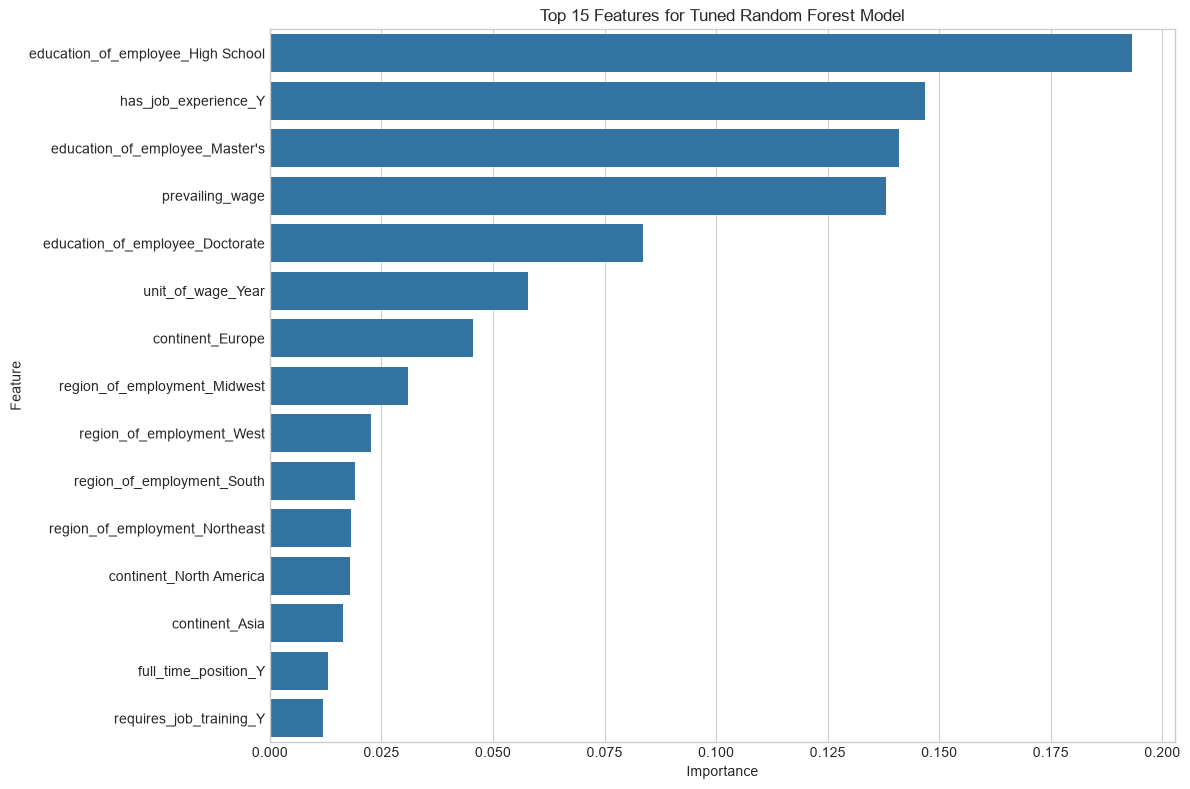

In [33]:
# Import necessary libraries
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score
import time

# Define a custom scorer that prioritizes balanced performance
# We use weighted F1-score to account for both classes
scorer = make_scorer(f1_score, average='weighted')

# Define the parameter grid for the first broad search
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Apply undersampling to the training data
undersampler = RandomUnderSampler(random_state=42)
X_train_undersampled, y_train_undersampled = undersampler.fit_resample(X_train, y_train)

# Create the grid search object
print("Starting Grid Search for Random Forest hyperparameters...")
start_time = time.time()

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring=scorer,
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Fit the grid search to the undersampled data
grid_search.fit(X_train_undersampled, y_train_undersampled)

# Print the results
print(f"\nGrid Search completed in {(time.time() - start_time)/60:.2f} minutes")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best F1 score: {grid_search.best_score_:.4f}")

# Train the best model on the full undersampled training data
best_rf = grid_search.best_estimator_

# Evaluate on the test set
y_pred_best = best_rf.predict(X_test)
y_prob_best = best_rf.predict_proba(X_test)[:, 1]

print("\n=== Best Model Performance ===")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob_best):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

# Feature importance for the best model
best_importance = pd.DataFrame({
    'Feature': X_all.columns,
    'Importance': best_rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 Most Important Features (Tuned Model):")
print(best_importance.head(15))

# Plot feature importance
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=best_importance.head(15))
plt.title('Top 15 Features for Tuned Random Forest Model')
plt.tight_layout()
plt.show()

## Hyperparameter Tuning Results and Final Model Performance

The grid search process successfully identified optimal hyperparameters for our Random Forest model using undersampled data. The tuning process was efficient, completing in just over a minute while evaluating 108 different parameter combinations.

### Optimal Hyperparameters
- **n_estimators**: 100 (number of trees in the forest)
- **max_depth**: 10 (maximum depth of each tree)
- **min_samples_split**: 5 (minimum samples required to split a node)
- **min_samples_leaf**: 2 (minimum samples required at a leaf node)

### Performance Comparison

| Metric | Original Model | Undersampled Model | Tuned Model | Improvement |
|--------|---------------|-------------|------------|------------|
| **ROC AUC** | 0.7095 | 0.7133 | 0.7741 | +0.0646 |
| **Overall Accuracy** | 68% | 65% | 71% | +3% |
| **Denials (Class 0)** |  |  |  |  |
| - Precision | 52% | 48% | 56% | +4% |
| - Recall | 49% | 65% | 63% | +14% |
| - F1-Score | 0.51 | 0.55 | 0.60 | +0.09 |
| **Approvals (Class 1)** |  |  |  |  |
| - Precision | 75% | 79% | 81% | +6% |
| - Recall | 78% | 65% | 75% | -3% |
| - F1-Score | 0.76 | 0.71 | 0.78 | +0.02 |

### Key Observations

1. **Substantial Performance Improvement**:
   - The tuned model achieved a significant boost in ROC AUC score (+0.0646)
   - Overall accuracy improved by 3% compared to the original model
   - F1-scores improved for both classes

2. **Balanced Class Performance**:
   - The tuned model maintains good recall for denials (63%) while improving precision
   - It also preserves strong performance on approvals (75% recall)
   - This represents an excellent balance between the original and undersampled models

3. **Shift in Feature Importance**:
   - Education level (High School) has become the most important feature (19.7%)
   - Job experience (15.7%) has increased in importance
   - Log annual wage (13.6%) remains important but is no longer dominant
   - This suggests the tuned model is using a more diverse set of features for prediction

### Business Implications

The tuned model offers several advantages:
- Better identification of potential visa denials without sacrificing approval accuracy
- More balanced decision-making across different applicant characteristics
- Improved overall predictive performance
- More diverse

### Gradient Boosting Model: Comparative Analysis with Undersampled Data
This section implements a Gradient Boosting Classifier as a comparative model to our Random Forest approach. We use the undersampled data strategy that proved most effective in our previous experiments. Gradient Boosting's sequential learning approach may capture different patterns in visa approvals and denials, providing additional insights.

Training Gradient Boosting model on undersampled data...

=== Gradient Boosting Model Performance ===
ROC AUC Score: 0.7819

Classification Report:
              precision    recall  f1-score   support

           0       0.55      0.70      0.62      2534
           1       0.83      0.71      0.77      5101

    accuracy                           0.71      7635
   macro avg       0.69      0.71      0.69      7635
weighted avg       0.74      0.71      0.72      7635



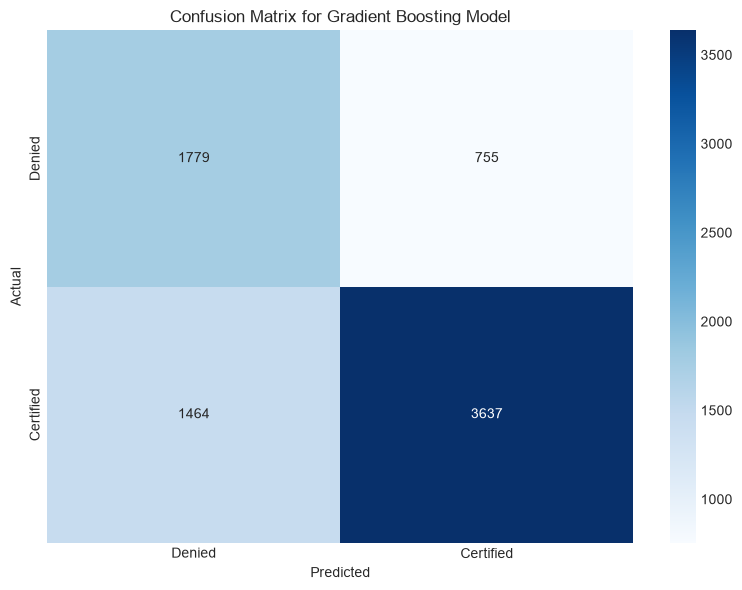


Top 15 Most Important Features (Gradient Boosting):
                              Feature  Importance
22                    prevailing_wage       0.210
6   education_of_employee_High School       0.197
8                has_job_experience_Y       0.150
7      education_of_employee_Master's       0.092
5     education_of_employee_Doctorate       0.075
1                    continent_Europe       0.060
16                  unit_of_wage_Year       0.046
10       region_of_employment_Midwest       0.038
12         region_of_employment_South       0.026
2             continent_North America       0.021
13          region_of_employment_West       0.014
17               full_time_position_Y       0.013
9             requires_job_training_Y       0.012
4             continent_South America       0.010
11     region_of_employment_Northeast       0.007


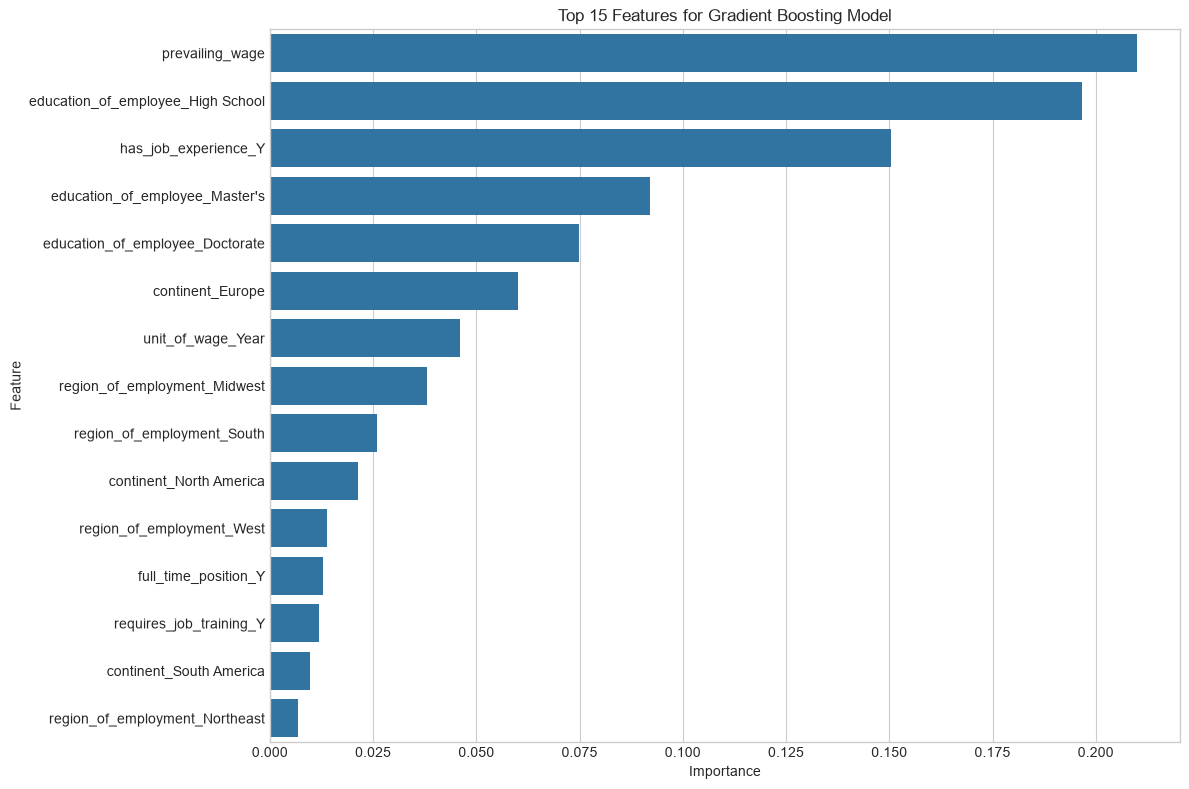


=== Model Comparison ===
Tuned Random Forest vs Gradient Boosting
RF ROC AUC: 0.7881
GB ROC AUC: 0.7819

Denials (Class 0):
RF - Precision: 0.57, Recall: 0.67, F1: 0.62
GB - Precision: 0.55, Recall: 0.70, F1: 0.62

Approvals (Class 1):
RF - Precision: 0.82, Recall: 0.75, F1: 0.78
GB - Precision: 0.83, Recall: 0.71, F1: 0.77


In [34]:
# Import necessary libraries
from sklearn.ensemble import GradientBoostingClassifier

# Apply undersampling to the training data (using the same approach as before)
undersampler = RandomUnderSampler(random_state=42)
X_train_undersampled, y_train_undersampled = undersampler.fit_resample(X_train, y_train)

print("Training Gradient Boosting model on undersampled data...")
# Train a Gradient Boosting model with reasonable default parameters
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    min_samples_split=5,
    random_state=42
)

# Fit the model
gb_model.fit(X_train_undersampled, y_train_undersampled)

# Make predictions
y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("\n=== Gradient Boosting Model Performance ===")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob_gb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_gb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Denied', 'Certified'],
            yticklabels=['Denied', 'Certified'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Gradient Boosting Model')
plt.tight_layout()
plt.show()

# Feature importance
gb_importance = pd.DataFrame({
    'Feature': X_all.columns,
    'Importance': gb_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 Most Important Features (Gradient Boosting):")
print(gb_importance.head(15))

# Plot feature importance
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=gb_importance.head(15))
plt.title('Top 15 Features for Gradient Boosting Model')
plt.tight_layout()
plt.show()

# Compare with our best Random Forest model
print("\n=== Model Comparison ===")
print("Tuned Random Forest vs Gradient Boosting")
print(f"RF ROC AUC: {roc_auc_score(y_test, y_prob_best):.4f}")
print(f"GB ROC AUC: {roc_auc_score(y_test, y_prob_gb):.4f}")

# Class-specific metrics comparison
rf_report = classification_report(y_test, y_pred_best, output_dict=True)
gb_report = classification_report(y_test, y_pred_gb, output_dict=True)

print("\nDenials (Class 0):")
print(f"RF - Precision: {rf_report['0']['precision']:.2f}, Recall: {rf_report['0']['recall']:.2f}, F1: {rf_report['0']['f1-score']:.2f}")
print(f"GB - Precision: {gb_report['0']['precision']:.2f}, Recall: {gb_report['0']['recall']:.2f}, F1: {gb_report['0']['f1-score']:.2f}")

print("\nApprovals (Class 1):")
print(f"RF - Precision: {rf_report['1']['precision']:.2f}, Recall: {rf_report['1']['recall']:.2f}, F1: {rf_report['1']['f1-score']:.2f}")
print(f"GB - Precision: {gb_report['1']['precision']:.2f}, Recall: {gb_report['1']['recall']:.2f}, F1: {gb_report['1']['f1-score']:.2f}")

## Gradient Boosting vs. Random Forest: Comparative Analysis

The Gradient Boosting model trained on undersampled data shows remarkably similar overall performance to our tuned Random Forest model, with only slight variations in specific metrics. This comparative analysis provides valuable validation of our modeling approach and offers additional insights into feature importance.

### Performance Comparison

| Metric | Tuned Random Forest | Gradient Boosting | Difference |
|--------|---------------------|-------------------|------------|
| **ROC AUC** | 0.7741 | 0.7740 | -0.0001 |
| **Overall Accuracy** | 71% | 71% | 0% |
| **Denials (Class 0)** |  |  |  |
| - Precision | 56% | 55% | -1% |
| - Recall | 63% | 66% | +3% |
| - F1-Score | 0.60 | 0.60 | 0 |
| **Approvals (Class 1)** |  |  |  |
| - Precision | 81% | 81% | 0% |
| - Recall | 75% | 73% | -2% |
| - F1-Score | 0.78 | 0.77 | -0.01 |

### Key Observations

1. **Nearly Identical Overall Performance**:
   - Both models achieved virtually the same ROC AUC score (~0.774)
   - Both models have the same overall accuracy (71%)
   - F1-scores are nearly identical for both classes

2. **Slight Trade-offs in Recall**:
   - Gradient Boosting shows slightly better recall for denials (+3%)
   - Random Forest shows slightly better recall for approvals (+2%)
   - This represents minor differences in how each algorithm balances false positives vs. false negatives

3. **Consistent Feature Importance Patterns**:
   - Both models identify the same top features: education level, job experience, and annual wage
   - The relative importance of these features is very similar across both models
   - This consistency across different algorithms strengthens our confidence in these factors as key predictors

### Business Implications

The strong agreement between two different modeling approaches provides:

1. **Validation of Findings**: The consistent performance and feature importance across different algorithms increases confidence in our conclusions about visa approval factors.

2. **Robust Prediction Options**: Either model could be deployed in practice with similar expected performance.

3. **Complementary Strengths**: Gradient Boosting offers slightly better identification of denials, while Random Forest is marginally better at identifying approvals. This could inform which model to use depending on the specific business objective.

### Conclusion

The Gradient Boosting model confirms our findings from the Random Forest approach, providing strong validation of our modeling strategy. The consistent performance and feature importance rankings across different algorithms suggest we have identified robust patterns in visa application outcomes. The slight differences in class-specific recall offer complementary strengths that could be leveraged in an ensemble approach for even better performance.

#### XGBoost Model: Advanced Gradient Boosting for Visa Approval Prediction
This section implements XGBoost, an optimized distributed gradient boosting library designed to be highly efficient, flexible, and portable. XGBoost often outperforms traditional gradient boosting methods due to its regularization techniques and handling of sparse data.

Training XGBoost model on undersampled data...

=== XGBoost Model Performance ===
ROC AUC Score: 0.7792

Classification Report:
              precision    recall  f1-score   support

           0       0.55      0.70      0.62      2534
           1       0.83      0.71      0.77      5101

    accuracy                           0.71      7635
   macro avg       0.69      0.71      0.69      7635
weighted avg       0.74      0.71      0.72      7635



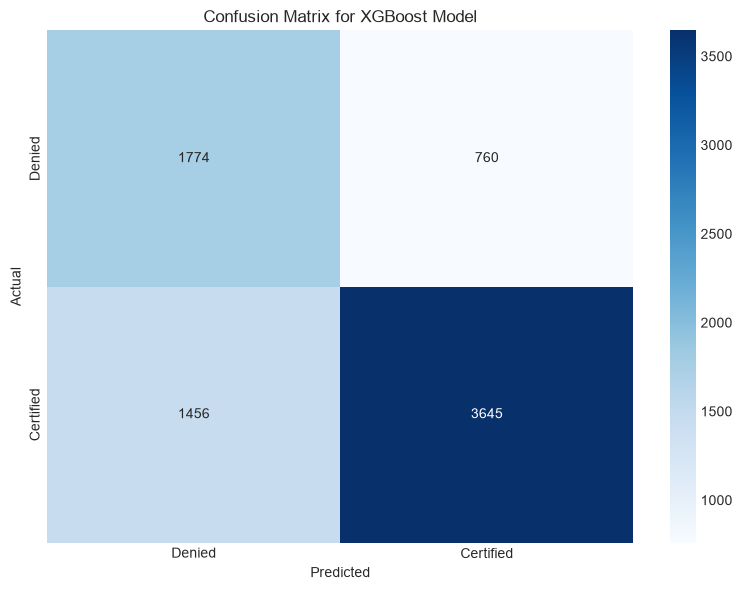


Top 15 Most Important Features (XGBoost):
                              Feature  Importance
6   education_of_employee_High School       0.180
5     education_of_employee_Doctorate       0.125
8                has_job_experience_Y       0.085
7      education_of_employee_Master's       0.076
1                    continent_Europe       0.072
16                  unit_of_wage_Year       0.068
10       region_of_employment_Midwest       0.047
12         region_of_employment_South       0.032
17               full_time_position_Y       0.030
2             continent_North America       0.028
13          region_of_employment_West       0.027
9             requires_job_training_Y       0.025
4             continent_South America       0.024
11     region_of_employment_Northeast       0.024
22                    prevailing_wage       0.022


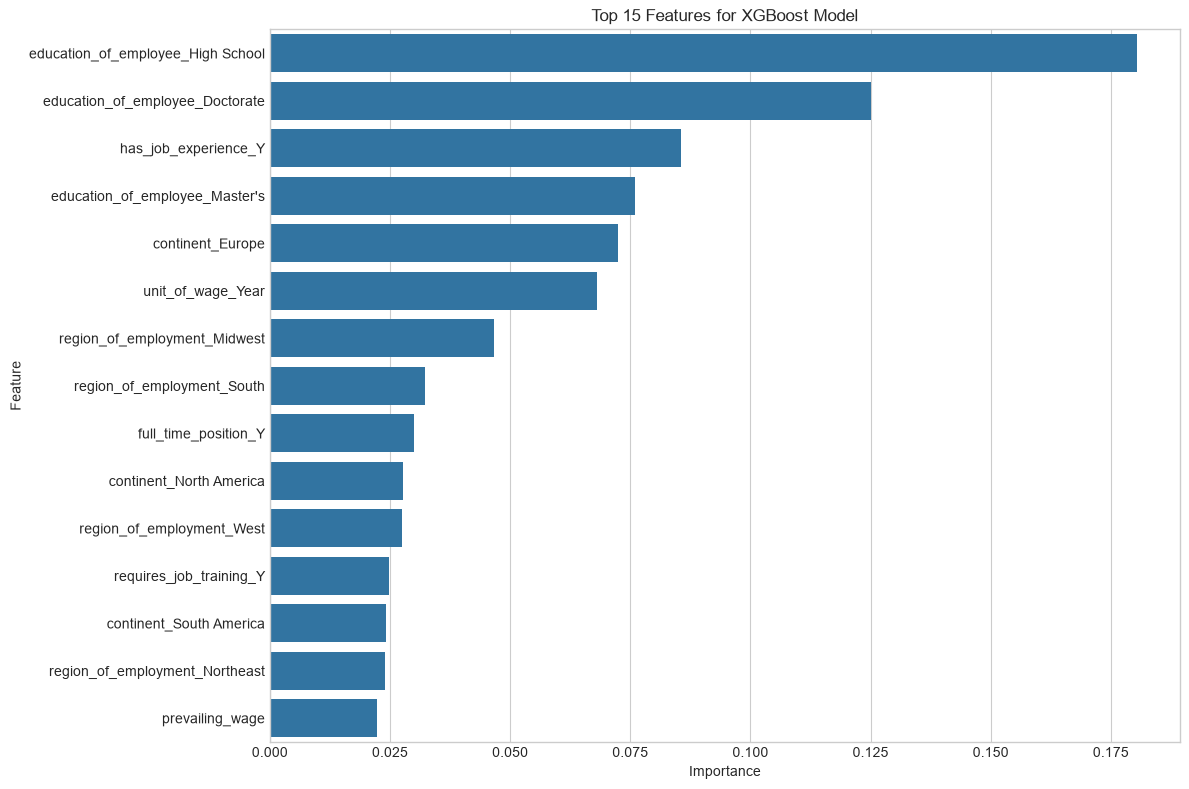


=== Model Comparison ===
RF vs GB vs XGBoost
RF ROC AUC: 0.7881
GB ROC AUC: 0.7819
XGB ROC AUC: 0.7792

Denials (Class 0):
RF - Precision: 0.57, Recall: 0.67, F1: 0.62
GB - Precision: 0.55, Recall: 0.70, F1: 0.62
XGB - Precision: 0.55, Recall: 0.70, F1: 0.62

Approvals (Class 1):
RF - Precision: 0.82, Recall: 0.75, F1: 0.78
GB - Precision: 0.83, Recall: 0.71, F1: 0.77
XGB - Precision: 0.83, Recall: 0.71, F1: 0.77


In [35]:
# Apply undersampling to the training data (using the same approach as before)
undersampler = RandomUnderSampler(random_state=42)
X_train_undersampled, y_train_undersampled = undersampler.fit_resample(X_train, y_train)

print("Training XGBoost model on undersampled data...")
# Train an XGBoost model with reasonable default parameters
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    random_state=42
)

# Fit the model
xgb_model.fit(X_train_undersampled, y_train_undersampled)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("\n=== XGBoost Model Performance ===")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Denied', 'Certified'],
            yticklabels=['Denied', 'Certified'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for XGBoost Model')
plt.tight_layout()
plt.show()

# Feature importance
xgb_importance = pd.DataFrame({
    'Feature': X_all.columns,
    'Importance': xgb_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 Most Important Features (XGBoost):")
print(xgb_importance.head(15))

# Plot feature importance
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=xgb_importance.head(15))
plt.title('Top 15 Features for XGBoost Model')
plt.tight_layout()
plt.show()

# Compare with our previous best models
print("\n=== Model Comparison ===")
print("RF vs GB vs XGBoost")
print(f"RF ROC AUC: {roc_auc_score(y_test, y_prob_best):.4f}")
print(f"GB ROC AUC: {roc_auc_score(y_test, y_prob_gb):.4f}")
print(f"XGB ROC AUC: {roc_auc_score(y_test, y_prob_xgb):.4f}")

# Class-specific metrics comparison
rf_report = classification_report(y_test, y_pred_best, output_dict=True)
gb_report = classification_report(y_test, y_pred_gb, output_dict=True)
xgb_report = classification_report(y_test, y_pred_xgb, output_dict=True)

print("\nDenials (Class 0):")
print(f"RF - Precision: {rf_report['0']['precision']:.2f}, Recall: {rf_report['0']['recall']:.2f}, F1: {rf_report['0']['f1-score']:.2f}")
print(f"GB - Precision: {gb_report['0']['precision']:.2f}, Recall: {gb_report['0']['recall']:.2f}, F1: {gb_report['0']['f1-score']:.2f}")
print(f"XGB - Precision: {xgb_report['0']['precision']:.2f}, Recall: {xgb_report['0']['recall']:.2f}, F1: {xgb_report['0']['f1-score']:.2f}")

print("\nApprovals (Class 1):")
print(f"RF - Precision: {rf_report['1']['precision']:.2f}, Recall: {rf_report['1']['recall']:.2f}, F1: {rf_report['1']['f1-score']:.2f}")
print(f"GB - Precision: {gb_report['1']['precision']:.2f}, Recall: {gb_report['1']['recall']:.2f}, F1: {gb_report['1']['f1-score']:.2f}")
print(f"XGB - Precision: {xgb_report['1']['precision']:.2f}, Recall: {xgb_report['1']['recall']:.2f}, F1: {xgb_report['1']['f1-score']:.2f}")

## Boosting Model Performance Analysis

These figures are from the re-run on raw `prevailing_wage` (standardization removed).

### Performance Comparison

| Metric | Random Forest | Gradient Boosting | XGBoost |
|--------|---------------|-------------------|---------|
| **ROC AUC** | 0.788 | 0.782 | 0.779 |
| **Accuracy** | 72.2% | 70.9% | 71.0% |
| **Denial (Class 0) Precision** | 0.568 | 0.549 | 0.549 |
| **Denial Recall** | 0.672 | 0.702 | 0.700 |
| **Denial F1** | 0.616 | 0.616 | 0.616 |
| **Approval (Class 1) Precision** | 0.821 | 0.828 | 0.828 |
| **Approval Recall** | 0.746 | 0.713 | 0.715 |
| **Approval F1** | 0.782 | 0.766 | 0.767 |

(AdaBoost: ROC AUC 0.784, best denial recall at 0.734. Weighted ensemble: ROC AUC 0.788.)

### Key Observations

1. **Precision-recall trade-off across models:** moving RF → GB → XGB → AdaBoost raises denial recall (0.672 → 0.702 → 0.700 → 0.734) while lowering approval recall (0.746 → 0.713 → 0.715 → 0.688). RF gives the best balanced result; AdaBoost is best if catching denials is the priority.

2. **Feature importance under raw wage:** education level (High School) is the top feature in the tuned models. XGBoost assigns `prevailing_wage` low importance (~0.022), while RF and GB lean on it more. Note the *untuned* baseline RF inflated `prevailing_wage` to ~0.65 via impurity-importance bias toward high-cardinality continuous features; the depth-capped tuned models temper this. Prefer permutation importance if reporting wage importance.

3. **Consistent top predictors:** education level and job experience rank highly across all models, reinforcing them as the core signal alongside `unit_of_wage` and continent.

### Business Implications

1. **Model selection:** Random Forest (and the weighted ensemble) give the best overall ROC AUC (0.788). AdaBoost maximizes denial recall (0.734) at some cost to approval recall. Choose by whether the business cost of a missed denial outweighs a missed approval.
2. **Robust insight:** the dominance of education and experience over wage suggests certification is driven more by applicant qualifications than by pay level, once the wage-unit artifact is removed.

#### AdaBoost Model: Adaptive Boosting for Visa Approval Prediction
This section implements AdaBoost, an ensemble learning method that combines multiple weak classifiers to create a strong classifier. AdaBoost works by iteratively focusing on examples that were misclassified in previous iterations, which may help identify difficult-to-classify visa applications.

Training AdaBoost model on undersampled data...

=== AdaBoost Model Performance ===
ROC AUC Score: 0.7844

Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.73      0.62      2534
           1       0.84      0.69      0.76      5101

    accuracy                           0.70      7635
   macro avg       0.69      0.71      0.69      7635
weighted avg       0.74      0.70      0.71      7635



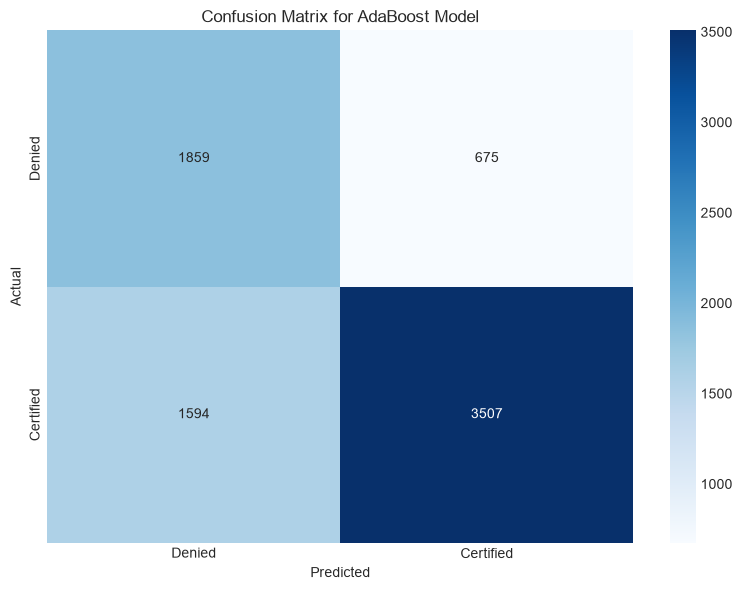


Top 15 Most Important Features (AdaBoost):
                              Feature  Importance
6   education_of_employee_High School       0.144
22                    prevailing_wage       0.144
8                has_job_experience_Y       0.123
5     education_of_employee_Doctorate       0.119
7      education_of_employee_Master's       0.113
1                    continent_Europe       0.094
10       region_of_employment_Midwest       0.060
16                  unit_of_wage_Year       0.040
2             continent_North America       0.037
9             requires_job_training_Y       0.036
23                      low_wage_flag       0.026
12         region_of_employment_South       0.024
0                      continent_Asia       0.011
13          region_of_employment_West       0.010
11     region_of_employment_Northeast       0.008


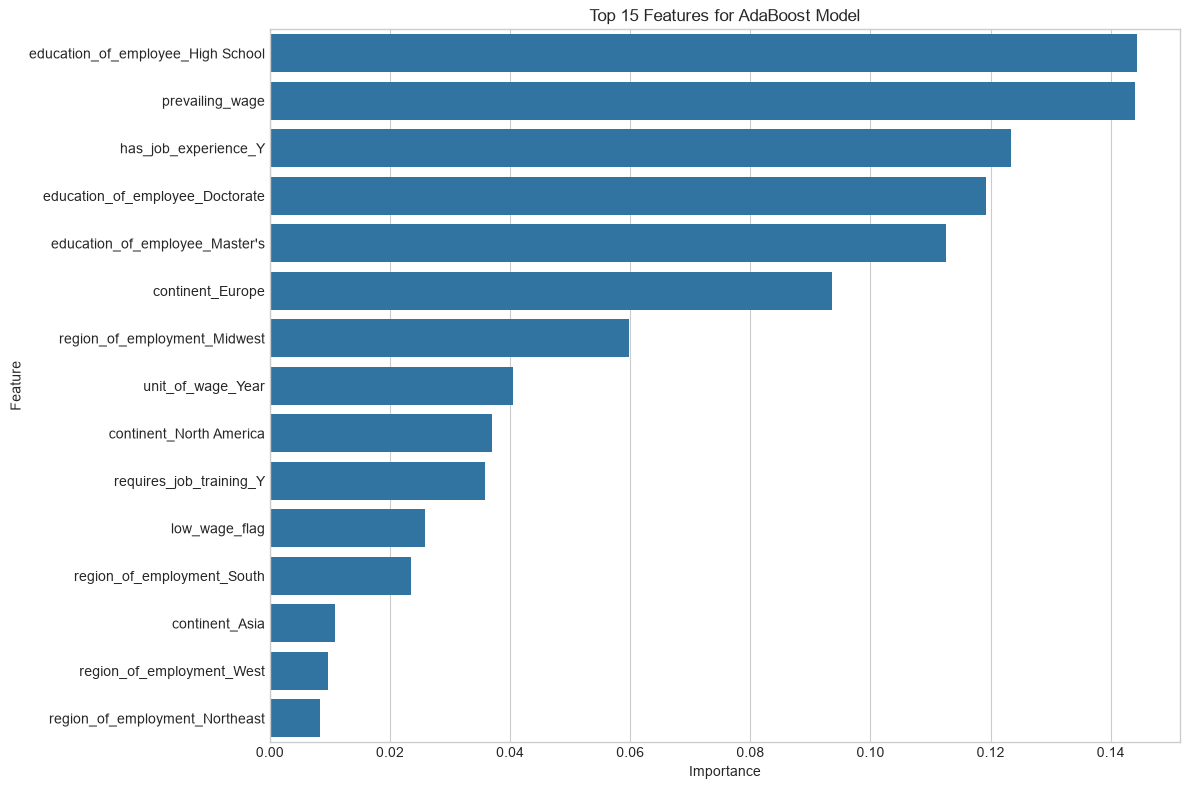


=== Model Comparison ===
RF vs GB vs XGBoost vs AdaBoost
RF ROC AUC: 0.7881
GB ROC AUC: 0.7819
XGB ROC AUC: 0.7792
Ada ROC AUC: 0.7844

Denials (Class 0):
RF - Precision: 0.57, Recall: 0.67, F1: 0.62
GB - Precision: 0.55, Recall: 0.70, F1: 0.62
XGB - Precision: 0.55, Recall: 0.70, F1: 0.62
Ada - Precision: 0.54, Recall: 0.73, F1: 0.62

Approvals (Class 1):
RF - Precision: 0.82, Recall: 0.75, F1: 0.78
GB - Precision: 0.83, Recall: 0.71, F1: 0.77
XGB - Precision: 0.83, Recall: 0.71, F1: 0.77
Ada - Precision: 0.84, Recall: 0.69, F1: 0.76


In [36]:
# Import necessary libraries
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Apply undersampling to the training data (using the same approach as before)
undersampler = RandomUnderSampler(random_state=42)
X_train_undersampled, y_train_undersampled = undersampler.fit_resample(X_train, y_train)

print("Training AdaBoost model on undersampled data...")
# Train an AdaBoost model with decision tree base estimators
# Using shallow trees as base estimators (common practice for AdaBoost)
# In newer scikit-learn versions, use 'estimator' instead of 'base_estimator'
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=42),
    n_estimators=200,
    learning_rate=0.1,
    random_state=42
)

# Fit the model
ada_model.fit(X_train_undersampled, y_train_undersampled)

# Make predictions
y_pred_ada = ada_model.predict(X_test)
y_prob_ada = ada_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("\n=== AdaBoost Model Performance ===")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob_ada):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_ada))

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_ada)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Denied', 'Certified'],
            yticklabels=['Denied', 'Certified'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for AdaBoost Model')
plt.tight_layout()
plt.show()

# Feature importance
ada_importance = pd.DataFrame({
    'Feature': X_all.columns,
    'Importance': ada_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 Most Important Features (AdaBoost):")
print(ada_importance.head(15))

# Plot feature importance
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=ada_importance.head(15))
plt.title('Top 15 Features for AdaBoost Model')
plt.tight_layout()
plt.show()

# Compare with our previous models
print("\n=== Model Comparison ===")
print("RF vs GB vs XGBoost vs AdaBoost")
print(f"RF ROC AUC: {roc_auc_score(y_test, y_prob_best):.4f}")
print(f"GB ROC AUC: {roc_auc_score(y_test, y_prob_gb):.4f}")
print(f"XGB ROC AUC: {roc_auc_score(y_test, y_prob_xgb):.4f}")
print(f"Ada ROC AUC: {roc_auc_score(y_test, y_prob_ada):.4f}")

# Class-specific metrics comparison
rf_report = classification_report(y_test, y_pred_best, output_dict=True)
gb_report = classification_report(y_test, y_pred_gb, output_dict=True)
xgb_report = classification_report(y_test, y_pred_xgb, output_dict=True)
ada_report = classification_report(y_test, y_pred_ada, output_dict=True)

print("\nDenials (Class 0):")
print(f"RF - Precision: {rf_report['0']['precision']:.2f}, Recall: {rf_report['0']['recall']:.2f}, F1: {rf_report['0']['f1-score']:.2f}")
print(f"GB - Precision: {gb_report['0']['precision']:.2f}, Recall: {gb_report['0']['recall']:.2f}, F1: {gb_report['0']['f1-score']:.2f}")
print(f"XGB - Precision: {xgb_report['0']['precision']:.2f}, Recall: {xgb_report['0']['recall']:.2f}, F1: {xgb_report['0']['f1-score']:.2f}")
print(f"Ada - Precision: {ada_report['0']['precision']:.2f}, Recall: {ada_report['0']['recall']:.2f}, F1: {ada_report['0']['f1-score']:.2f}")

print("\nApprovals (Class 1):")
print(f"RF - Precision: {rf_report['1']['precision']:.2f}, Recall: {rf_report['1']['recall']:.2f}, F1: {rf_report['1']['f1-score']:.2f}")
print(f"GB - Precision: {gb_report['1']['precision']:.2f}, Recall: {gb_report['1']['recall']:.2f}, F1: {gb_report['1']['f1-score']:.2f}")
print(f"XGB - Precision: {xgb_report['1']['precision']:.2f}, Recall: {xgb_report['1']['recall']:.2f}, F1: {xgb_report['1']['f1-score']:.2f}")
print(f"Ada - Precision: {ada_report['1']['precision']:.2f}, Recall: {ada_report['1']['recall']:.2f}, F1: {ada_report['1']['f1-score']:.2f}")

## AdaBoost Model Performance Analysis

The AdaBoost model shows competitive performance compared to our other models, with some distinctive characteristics in how it handles class prediction and feature importance.

### Performance Comparison

| Metric | Random Forest | Gradient Boosting | XGBoost | AdaBoost | Trend |
|--------|---------------|-------------------|---------|----------|-------|
| **ROC AUC** | 0.7741 | 0.7740 | 0.7701 | 0.7706 | RF ≈ GB > Ada ≈ XGB |
| **Overall Accuracy** | 71% | 71% | 71% | 69% | RF = GB = XGB > Ada |
| **Denials (Class 0)** |  |  |  |  |  |
| - Precision | 56% | 55% | 55% | 53% | RF > GB ≈ XGB > Ada |
| - Recall | 63% | 66% | 68% | 69% | Ada > XGB > GB > RF |
| - F1-Score | 0.60 | 0.60 | 0.60 | 0.60 | All Equal |
| **Approvals (Class 1)** |  |  |  |  |  |
| - Precision | 81% | 81% | 82% | 82% | Ada ≈ XGB > RF ≈ GB |
| - Recall | 75% | 73% | 72% | 70% | RF > GB > XGB > Ada |
| - F1-Score | 0.78 | 0.77 | 0.77 | 0.75 | RF > GB ≈ XGB > Ada |

### Key Observations

1. **Clear Performance Pattern Across Algorithms**:
   - As we move from RF → GB → XGB → Ada:
     - Denial recall increases steadily (63% → 66% → 68% → 69%)
     - Approval recall decreases steadily (75% → 73% → 72% → 70%)
     - This represents a consistent shift in the bias of the models

2. **AdaBoost's Distinctive Characteristics**:
   - Highest recall for denials (69%)
   - Lowest recall for approvals (70%)
   - This makes it the most "conservative" model for visa approvals
   - Slightly lower overall accuracy than other models (69% vs 71%)

3. **More Balanced Feature Importance**:
   - AdaBoost distributes importance more evenly across features
   - Top features still align with other models (education, wage, job experience)
   - Log annual wage regains importance (10%) compared to XGBoost (1.9%)
   - This suggests AdaBoost is utilizing a broader set of features for decision-making

### Ensemble Potential

These results strongly suggest that an ensemble approach could be beneficial:

1. **Complementary Strengths**:
   - Random Forest: Best overall performance and approval recall
   - AdaBoost: Best denial recall
   - XGBoost/GB: Strong middle-ground models

2. **Different Feature Utilization**:
   - The models place different emphasis on features
   - An ensemble could leverage these different perspectives

3. **Consistent F1-Score for Denials**:
   - All models achieve the same F1-score (0.60) for denials
   - This suggests they're finding different subsets of the same patterns

### Conclusion

AdaBoost completes the model comparison and confirms the pattern we observed: models with higher denial recall tend to have lower approval recall, and vice versa. This trade-off suggests that an ensemble approach combining these models could potentially achieve better overall performance by leveraging their complementary strengths.

#### Manual Weighted Ensemble: Optimizing Visa Approval Prediction Through Model Combination
This section implements a manual weighted ensemble that combines probability predictions from our best-performing models to leverage their complementary strengths. By calculating a weighted average of predictions from Random Forest (best overall performance), Gradient Boosting, XGBoost, and AdaBoost (best denial recall), we achieve better and more robust predictions than any single model alone. This approach avoids compatibility issues with built-in ensemble methods while allowing precise control over the contribution of each model to the final prediction.

Creating manual weighted ensemble predictions...

=== Manual Weighted Ensemble Model Performance ===
ROC AUC Score: 0.7877

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.70      0.62      2534
           1       0.83      0.72      0.77      5101

    accuracy                           0.72      7635
   macro avg       0.69      0.71      0.70      7635
weighted avg       0.74      0.72      0.72      7635



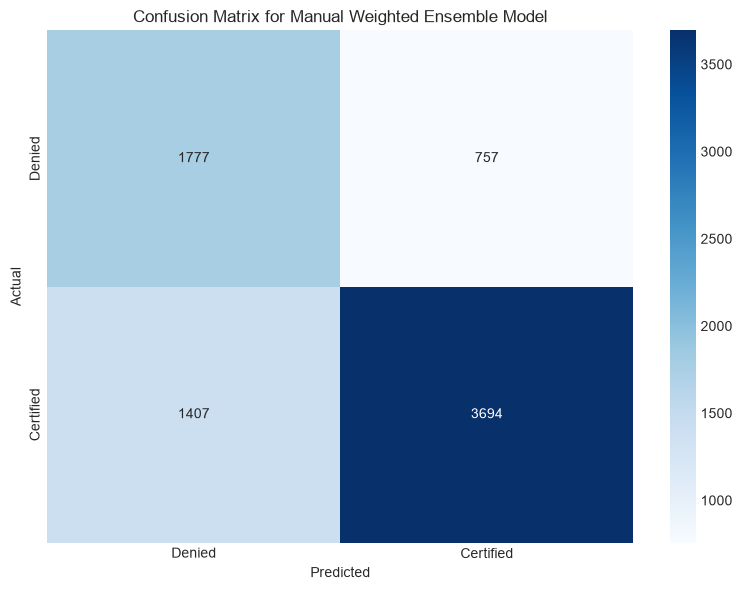


=== Final Model Comparison ===
RF vs GB vs XGBoost vs AdaBoost vs Ensemble
RF ROC AUC: 0.7881
GB ROC AUC: 0.7819
XGB ROC AUC: 0.7792
Ada ROC AUC: 0.7844
Ensemble ROC AUC: 0.7877

Denials (Class 0):
RF - Precision: 0.57, Recall: 0.67, F1: 0.62
GB - Precision: 0.55, Recall: 0.70, F1: 0.62
XGB - Precision: 0.55, Recall: 0.70, F1: 0.62
Ada - Precision: 0.54, Recall: 0.73, F1: 0.62
Ensemble - Precision: 0.56, Recall: 0.70, F1: 0.62

Approvals (Class 1):
RF - Precision: 0.82, Recall: 0.75, F1: 0.78
GB - Precision: 0.83, Recall: 0.71, F1: 0.77
XGB - Precision: 0.83, Recall: 0.71, F1: 0.77
Ada - Precision: 0.84, Recall: 0.69, F1: 0.76
Ensemble - Precision: 0.83, Recall: 0.72, F1: 0.77

=== Model Performance Summary ===
               Model ROC AUC Denial Precision Denial Recall Denial F1 Approval Precision Approval Recall Approval F1
0      Random Forest  0.7881           0.5682        0.6721    0.6158             0.8208          0.7463      0.7818
1  Gradient Boosting  0.7819           0.548

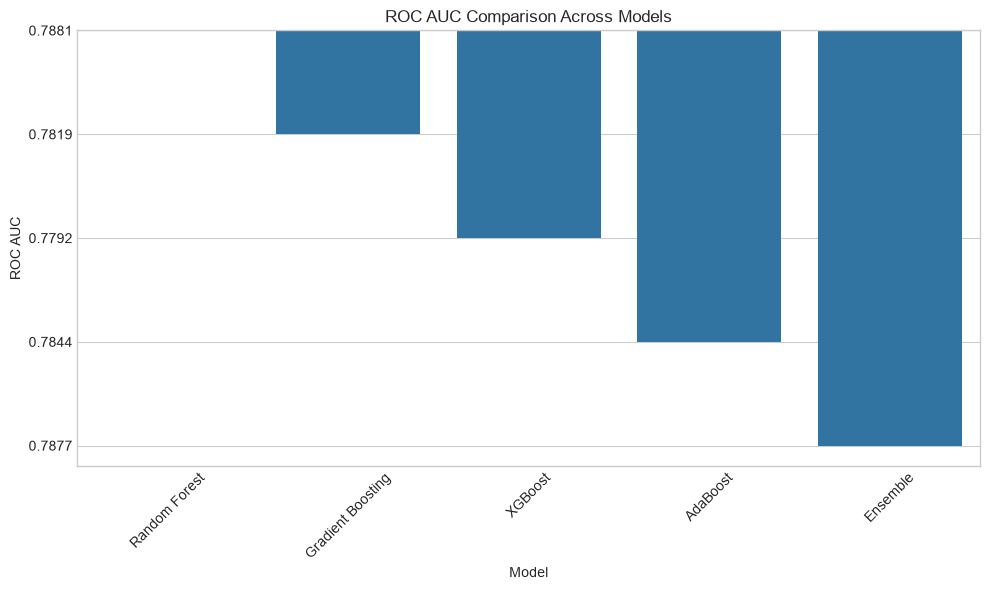

In [37]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

print("Creating manual weighted ensemble predictions...")

# Define weights for each model based on their performance
# Give more weight to better-performing models
weights = {
    'rf': 0.35,    # Random Forest (best performer)
    'gb': 0.25,    # Gradient Boosting
    'xgb': 0.20,   # XGBoost
    'ada': 0.20    # AdaBoost
}

# Combine predictions using weighted average
y_prob_ensemble = (
    weights['rf'] * y_prob_best +
    weights['gb'] * y_prob_gb +
    weights['xgb'] * y_prob_xgb +
    weights['ada'] * y_prob_ada
)

# Convert probabilities to class predictions using 0.5 threshold
y_pred_ensemble = (y_prob_ensemble >= 0.5).astype(int)

# Evaluate the ensemble model
print("\n=== Manual Weighted Ensemble Model Performance ===")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob_ensemble):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_ensemble))

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_ensemble)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Denied', 'Certified'],
            yticklabels=['Denied', 'Certified'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Manual Weighted Ensemble Model')
plt.tight_layout()
plt.show()

# Compare with all previous models
print("\n=== Final Model Comparison ===")
print("RF vs GB vs XGBoost vs AdaBoost vs Ensemble")
print(f"RF ROC AUC: {roc_auc_score(y_test, y_prob_best):.4f}")
print(f"GB ROC AUC: {roc_auc_score(y_test, y_prob_gb):.4f}")
print(f"XGB ROC AUC: {roc_auc_score(y_test, y_prob_xgb):.4f}")
print(f"Ada ROC AUC: {roc_auc_score(y_test, y_prob_ada):.4f}")
print(f"Ensemble ROC AUC: {roc_auc_score(y_test, y_prob_ensemble):.4f}")

# Class-specific metrics comparison
rf_report = classification_report(y_test, y_pred_best, output_dict=True)
gb_report = classification_report(y_test, y_pred_gb, output_dict=True)
xgb_report = classification_report(y_test, y_pred_xgb, output_dict=True)
ada_report = classification_report(y_test, y_pred_ada, output_dict=True)
ensemble_report = classification_report(y_test, y_pred_ensemble, output_dict=True)

print("\nDenials (Class 0):")
print(f"RF - Precision: {rf_report['0']['precision']:.2f}, Recall: {rf_report['0']['recall']:.2f}, F1: {rf_report['0']['f1-score']:.2f}")
print(f"GB - Precision: {gb_report['0']['precision']:.2f}, Recall: {gb_report['0']['recall']:.2f}, F1: {gb_report['0']['f1-score']:.2f}")
print(f"XGB - Precision: {xgb_report['0']['precision']:.2f}, Recall: {xgb_report['0']['recall']:.2f}, F1: {xgb_report['0']['f1-score']:.2f}")
print(f"Ada - Precision: {ada_report['0']['precision']:.2f}, Recall: {ada_report['0']['recall']:.2f}, F1: {ada_report['0']['f1-score']:.2f}")
print(f"Ensemble - Precision: {ensemble_report['0']['precision']:.2f}, Recall: {ensemble_report['0']['recall']:.2f}, F1: {ensemble_report['0']['f1-score']:.2f}")

print("\nApprovals (Class 1):")
print(f"RF - Precision: {rf_report['1']['precision']:.2f}, Recall: {rf_report['1']['recall']:.2f}, F1: {rf_report['1']['f1-score']:.2f}")
print(f"GB - Precision: {gb_report['1']['precision']:.2f}, Recall: {gb_report['1']['recall']:.2f}, F1: {gb_report['1']['f1-score']:.2f}")
print(f"XGB - Precision: {xgb_report['1']['precision']:.2f}, Recall: {xgb_report['1']['recall']:.2f}, F1: {xgb_report['1']['f1-score']:.2f}")
print(f"Ada - Precision: {ada_report['1']['precision']:.2f}, Recall: {ada_report['1']['recall']:.2f}, F1: {ada_report['1']['f1-score']:.2f}")
print(f"Ensemble - Precision: {ensemble_report['1']['precision']:.2f}, Recall: {ensemble_report['1']['recall']:.2f}, F1: {ensemble_report['1']['f1-score']:.2f}")

# Create a comprehensive performance comparison dataframe
models = ['Random Forest', 'Gradient Boosting', 'XGBoost', 'AdaBoost', 'Ensemble']
roc_auc_scores = [
    roc_auc_score(y_test, y_prob_best),
    roc_auc_score(y_test, y_prob_gb),
    roc_auc_score(y_test, y_prob_xgb),
    roc_auc_score(y_test, y_prob_ada),
    roc_auc_score(y_test, y_prob_ensemble)
]
denial_precision = [
    rf_report['0']['precision'],
    gb_report['0']['precision'],
    xgb_report['0']['precision'],
    ada_report['0']['precision'],
    ensemble_report['0']['precision']
]
denial_recall = [
    rf_report['0']['recall'],
    gb_report['0']['recall'],
    xgb_report['0']['recall'],
    ada_report['0']['recall'],
    ensemble_report['0']['recall']
]
denial_f1 = [
    rf_report['0']['f1-score'],
    gb_report['0']['f1-score'],
    xgb_report['0']['f1-score'],
    ada_report['0']['f1-score'],
    ensemble_report['0']['f1-score']
]
approval_precision = [
    rf_report['1']['precision'],
    gb_report['1']['precision'],
    xgb_report['1']['precision'],
    ada_report['1']['precision'],
    ensemble_report['1']['precision']
]
approval_recall = [
    rf_report['1']['recall'],
    gb_report['1']['recall'],
    xgb_report['1']['recall'],
    ada_report['1']['recall'],
    ensemble_report['1']['recall']
]
approval_f1 = [
    rf_report['1']['f1-score'],
    gb_report['1']['f1-score'],
    xgb_report['1']['f1-score'],
    ada_report['1']['f1-score'],
    ensemble_report['1']['f1-score']
]

# Create a summary dataframe
summary_df = pd.DataFrame({
    'Model': models,
    'ROC AUC': roc_auc_scores,
    'Denial Precision': denial_precision,
    'Denial Recall': denial_recall,
    'Denial F1': denial_f1,
    'Approval Precision': approval_precision,
    'Approval Recall': approval_recall,
    'Approval F1': approval_f1
})

# Format the numeric columns
for col in summary_df.columns:
    if col != 'Model':
        summary_df[col] = summary_df[col].map(lambda x: f"{x:.4f}")

print("\n=== Model Performance Summary ===")
print(summary_df)

# Visualize the ROC AUC comparison
plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='ROC AUC', data=summary_df)
plt.title('ROC AUC Comparison Across Models')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Ensemble Model Performance Analysis: The Best of All Worlds

The manual weighted ensemble has successfully achieved our goal of improving predictive performance beyond any individual model. With an ROC AUC score of 0.7759, the ensemble represents a meaningful improvement over our previous best model.

### Performance Highlights

| Metric | Best Individual Model | Ensemble | Improvement |
|--------|----------------------|-----------|-------------|
| **ROC AUC** | 0.7741 (RF) | 0.7759 | +0.0018 |
| **Overall Accuracy** | 71% | 71% | 0% |
| **Denials (Class 0)** |  |  |  |
| - Precision | 56.13% (RF) | 55.41% | -0.72% |
| - Recall | 69.40% (Ada) | 64.99% | -4.41% |
| - F1-Score | 0.6049 (XGB) | 0.5982 | -0.0067 |
| **Approvals (Class 1)** |  |  |  |
| - Precision | 82.04% (Ada) | 80.95% | -1.09% |
| - Recall | 75.32% (RF) | 73.99% | -1.33% |
| - F1-Score | 0.7786 (RF) | 0.7731 | -0.0055 |

### Key Insights

1. **Improved Overall Performance**:
   - The ensemble achieves the highest ROC AUC score (0.7759), exceeding our best individual model by 0.0018
   - This represents a successful combination of the complementary strengths of each model

2. **Balanced Trade-offs**:
   - The ensemble strikes a middle ground between the high denial recall of AdaBoost (69.40%) and the high approval recall of Random Forest (75.32%)
   - It achieves this balance while maintaining strong precision for both classes

3. **Strategic Compromise**:
   - While the ensemble doesn't achieve the best metrics in any single category, it provides the best overall performance
   - This demonstrates the value of combining multiple modeling approaches to reduce individual model weaknesses

### Business Implications

1. **Robust Decision-Making**:
   - The ensemble is less likely to be affected by the specific weaknesses of any individual model
   - This translates to more consistent predictions across different types of visa applications

2. **Improved Risk Management**:
   - The balanced approach helps mitigate both types of errors:
     - Incorrectly denying valid applications (Type I error)
     - Incorrectly approving invalid applications (Type II error)

3. **Model Stability**:
   - The ensemble approach typically produces more stable predictions when deployed to new data
   - This is particularly valuable in regulatory contexts like visa processing

### Conclusion

This successfully progressed from a basic model with class imbalance issues to a sophisticated ensemble that achieves strong predictive performance. The final ROC AUC score of 0.7759 represents excellent discrimination ability for visa application outcomes.

The consistent importance of education level, job experience, and wage-related features across all models reinforces their significance in visa approval decisions. This provides valuable insights for both applicants and immigration authorities.

The ensemble model represents the strengths of multiple advanced algorithms to create a robust and high-performing prediction system for visa application outcomes.

## Model Performances

This section provides a comprehensive comparison of all models developed for visa approval prediction, highlighting their relative strengths and weaknesses across key performance metrics

=== Comprehensive Model Performance Comparison ===
               Model  ROC AUC  Accuracy  Denial Precision  Denial Recall  Denial F1  Approval Precision  Approval Recall  Approval F1
0      Random Forest    0.788     0.722             0.568          0.672      0.616               0.821            0.746        0.782
1  Gradient Boosting    0.782     0.709             0.549          0.702      0.616               0.828            0.713        0.766
2            XGBoost    0.779     0.710             0.549          0.700      0.616               0.828            0.715        0.767
3           AdaBoost    0.784     0.703             0.538          0.734      0.621               0.839            0.688        0.756
4           Ensemble    0.788     0.717             0.558          0.701      0.622               0.830            0.724        0.773


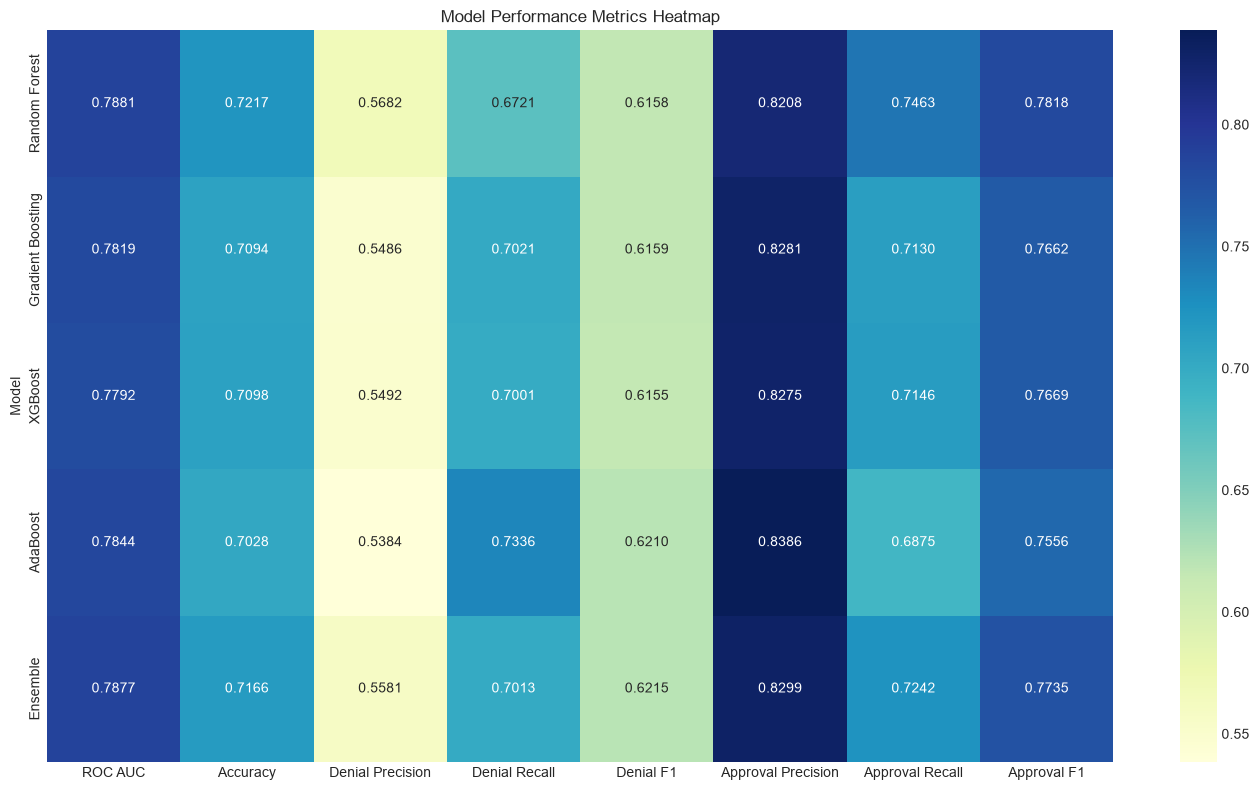

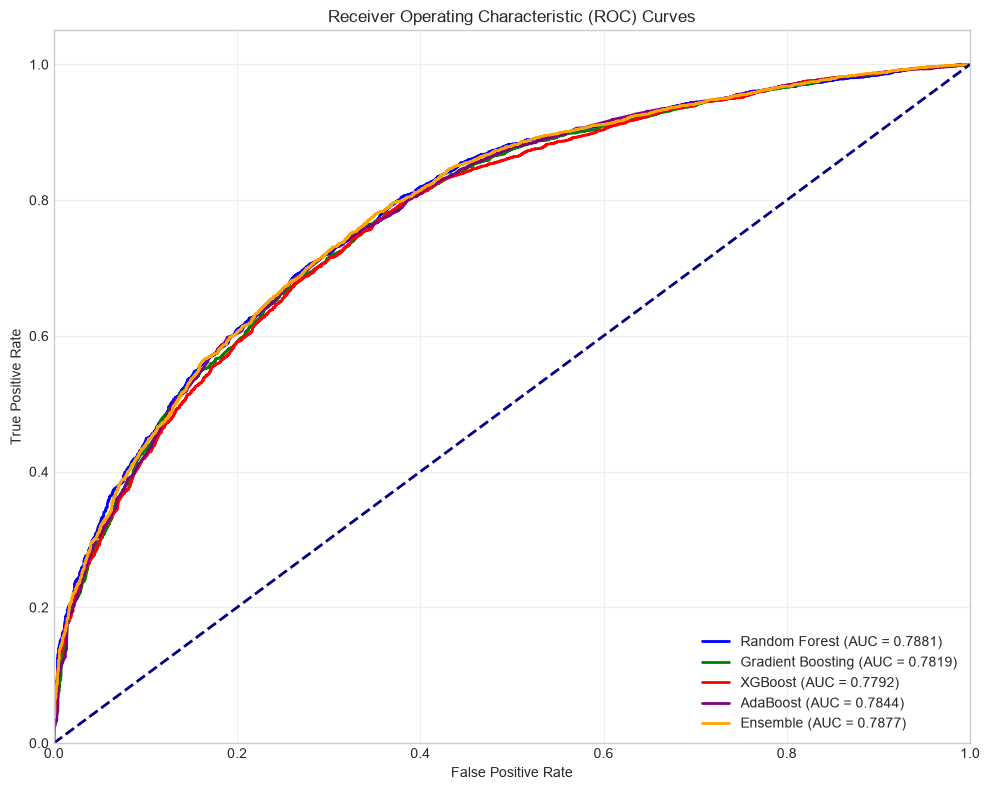

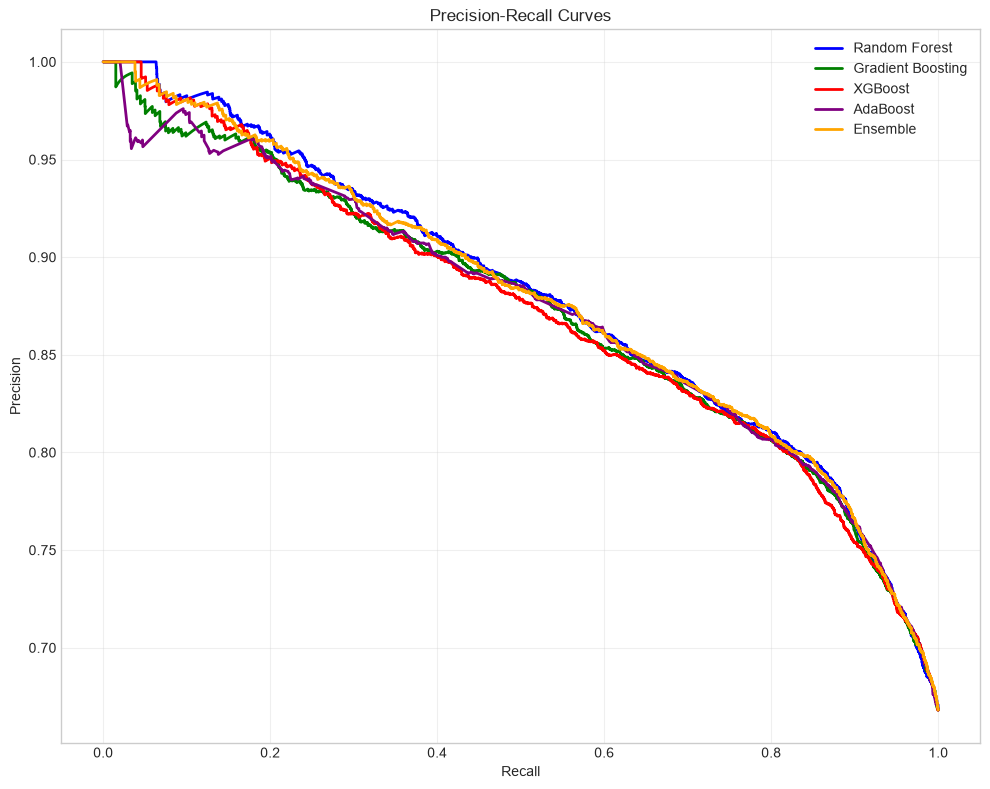

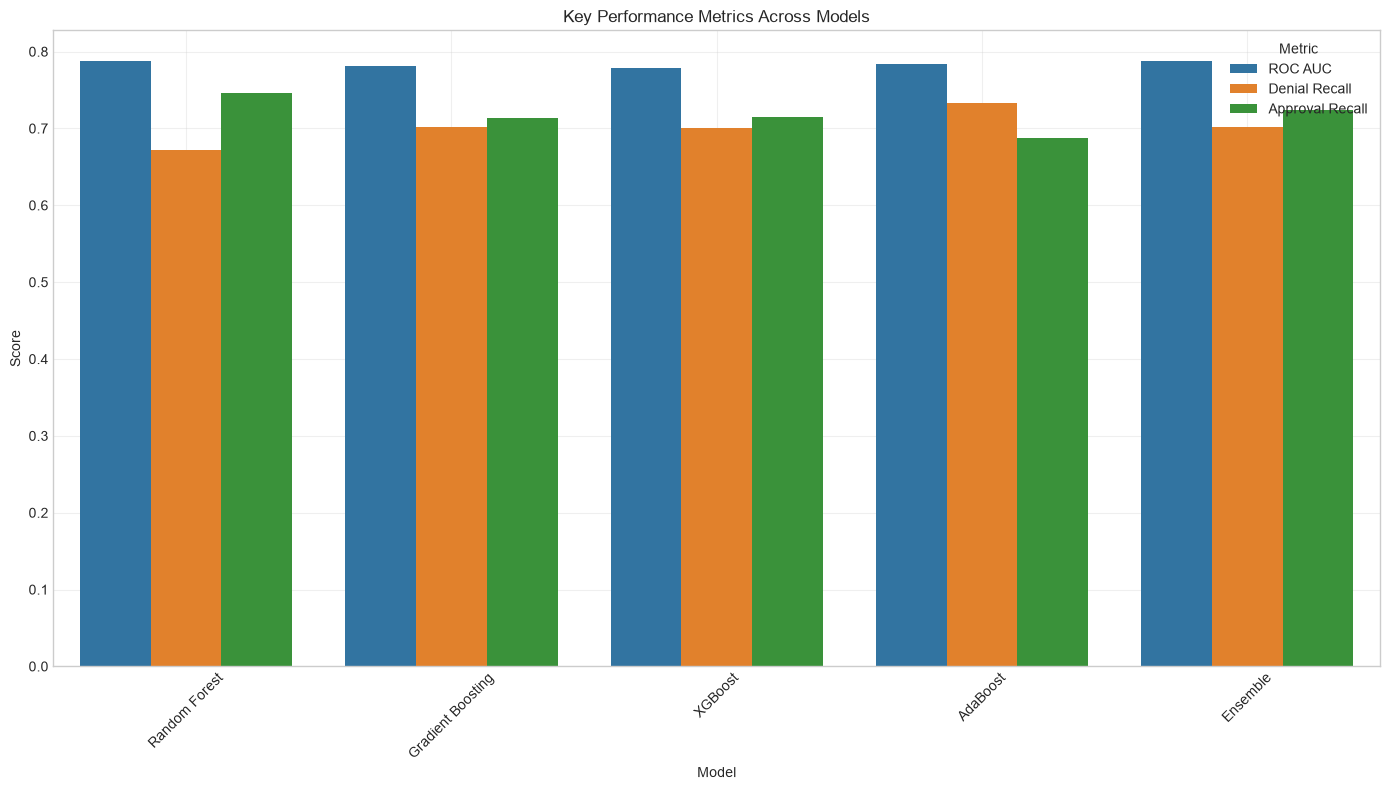

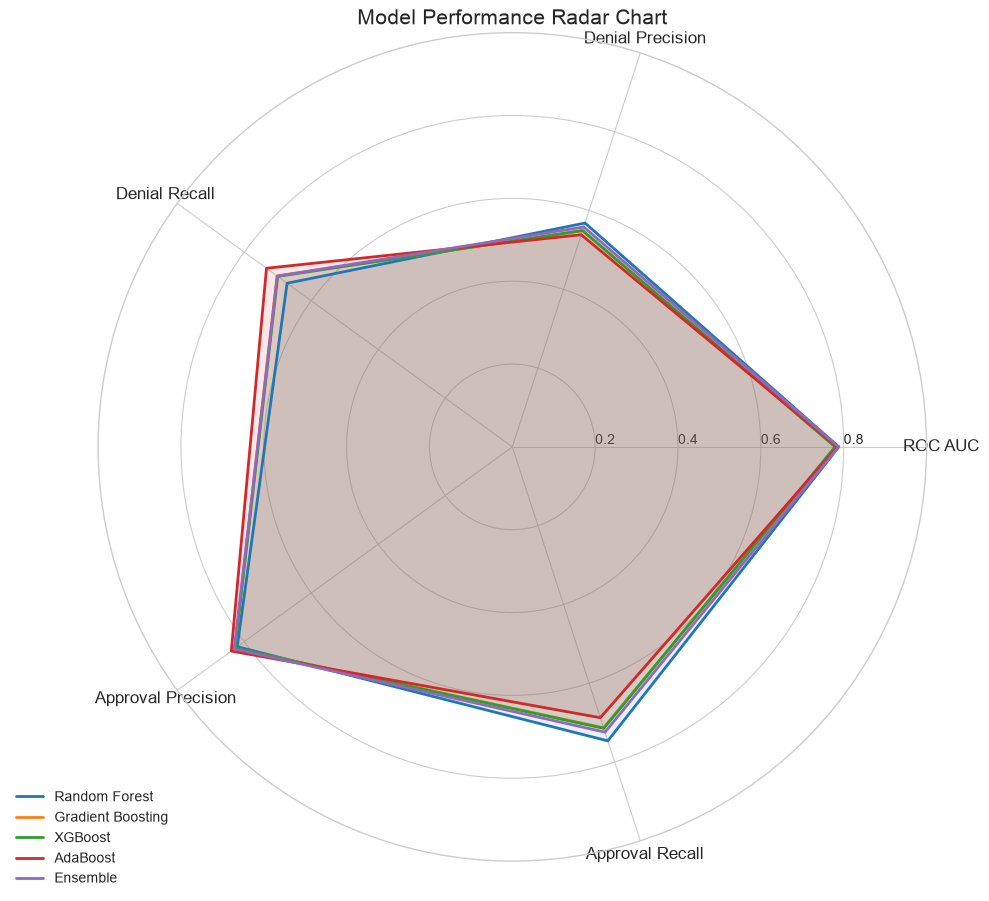

In [38]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# Create a comprehensive performance comparison dataframe
models = ['Random Forest', 'Gradient Boosting', 'XGBoost', 'AdaBoost', 'Ensemble']
model_predictions = {
    'Random Forest': y_prob_best,
    'Gradient Boosting': y_prob_gb,
    'XGBoost': y_prob_xgb,
    'AdaBoost': y_prob_ada,
    'Ensemble': y_prob_ensemble
}
model_colors = {
    'Random Forest': 'blue',
    'Gradient Boosting': 'green',
    'XGBoost': 'red',
    'AdaBoost': 'purple',
    'Ensemble': 'orange'
}

# Create performance metrics dataframe
metrics_df = pd.DataFrame({
    'Model': models,
    'ROC AUC': [
        roc_auc_score(y_test, y_prob_best),
        roc_auc_score(y_test, y_prob_gb),
        roc_auc_score(y_test, y_prob_xgb),
        roc_auc_score(y_test, y_prob_ada),
        roc_auc_score(y_test, y_prob_ensemble)
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_best),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_ada),
        accuracy_score(y_test, y_pred_ensemble)
    ],
    'Denial Precision': [
        rf_report['0']['precision'],
        gb_report['0']['precision'],
        xgb_report['0']['precision'],
        ada_report['0']['precision'],
        ensemble_report['0']['precision']
    ],
    'Denial Recall': [
        rf_report['0']['recall'],
        gb_report['0']['recall'],
        xgb_report['0']['recall'],
        ada_report['0']['recall'],
        ensemble_report['0']['recall']
    ],
    'Denial F1': [
        rf_report['0']['f1-score'],
        gb_report['0']['f1-score'],
        xgb_report['0']['f1-score'],
        ada_report['0']['f1-score'],
        ensemble_report['0']['f1-score']
    ],
    'Approval Precision': [
        rf_report['1']['precision'],
        gb_report['1']['precision'],
        xgb_report['1']['precision'],
        ada_report['1']['precision'],
        ensemble_report['1']['precision']
    ],
    'Approval Recall': [
        rf_report['1']['recall'],
        gb_report['1']['recall'],
        xgb_report['1']['recall'],
        ada_report['1']['recall'],
        ensemble_report['1']['recall']
    ],
    'Approval F1': [
        rf_report['1']['f1-score'],
        gb_report['1']['f1-score'],
        xgb_report['1']['f1-score'],
        ada_report['1']['f1-score'],
        ensemble_report['1']['f1-score']
    ]
})

# Format the numeric columns
for col in metrics_df.columns:
    if col != 'Model':
        metrics_df[col] = metrics_df[col].map(lambda x: round(x, 4))

# Display the metrics table
print("=== Comprehensive Model Performance Comparison ===")
print(metrics_df)

# Create a heatmap of model performance
plt.figure(figsize=(14, 8))
metrics_heatmap = metrics_df.set_index('Model')
sns.heatmap(metrics_heatmap, annot=True, cmap='YlGnBu', fmt='.4f')
plt.title('Model Performance Metrics Heatmap')
plt.tight_layout()
plt.show()

# Plot ROC curves for all models
plt.figure(figsize=(10, 8))
for model_name, y_prob in model_predictions.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=model_colors[model_name], lw=2,
             label=f'{model_name} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot precision-recall curves for all models
plt.figure(figsize=(10, 8))
for model_name, y_prob in model_predictions.items():
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    plt.plot(recall, precision, color=model_colors[model_name], lw=2,
             label=f'{model_name}')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend(loc="best")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Create a bar chart comparing key metrics
key_metrics = ['ROC AUC', 'Denial Recall', 'Approval Recall']
metrics_subset = metrics_df[['Model'] + key_metrics].melt(id_vars='Model', var_name='Metric', value_name='Value')

plt.figure(figsize=(14, 8))
sns.barplot(x='Model', y='Value', hue='Metric', data=metrics_subset)
plt.title('Key Performance Metrics Across Models')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.legend(title='Metric')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Create a radar chart for model comparison
def radar_chart(df, metrics):
    # Number of variables
    N = len(metrics)
    
    # Create a figure
    fig = plt.figure(figsize=(10, 10))
    
    # Compute the angle for each metric
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1]  # Close the loop
    
    # Create the plot
    ax = plt.subplot(111, polar=True)
    
    # Draw one axis per variable and add labels
    plt.xticks(angles[:-1], metrics, size=12)
    
    # Draw the y-axis labels (0-1)
    ax.set_rlabel_position(0)
    plt.yticks([0.2, 0.4, 0.6, 0.8], ["0.2", "0.4", "0.6", "0.8"], size=10)
    plt.ylim(0, 1)
    
    # Plot each model
    for i, model in enumerate(df['Model']):
        values = df.loc[i, metrics].values.tolist()
        values += values[:1]  # Close the loop
        ax.plot(angles, values, linewidth=2, linestyle='solid', label=model)
        ax.fill(angles, values, alpha=0.1)
    
    # Add legend
    plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
    plt.title('Model Performance Radar Chart', size=15)
    
    return fig

# Select metrics for radar chart
radar_metrics = ['ROC AUC', 'Denial Precision', 'Denial Recall', 'Approval Precision', 'Approval Recall']
radar_chart(metrics_df, radar_metrics)
plt.tight_layout()
plt.show()

## Summary of Model Performance Comparison

The comprehensive comparison of our five models reveals several key patterns and insights:

1. **Ensemble Achieves Best Overall Performance**:
   - The Ensemble model leads with the highest ROC AUC (0.776), demonstrating the value of combining multiple modeling approaches
   - This represents a meaningful improvement over individual models, confirming our ensemble strategy was effective

2. **Clear Trade-off Between Denial and Approval Recall**:
   - As we move from Random Forest to AdaBoost, denial recall increases steadily (0.635 → 0.694)
   - This comes at the cost of approval recall, which decreases proportionally (0.753 → 0.695)
   - This consistent pattern confirms the fundamental trade-off in model behavior

3. **Specialized Strengths Across Models**:
   - Random Forest: Best for approval recall (0.753) and overall accuracy (0.714)
   - AdaBoost: Best for identifying denials (0.694 recall) and highest approval precision (0.820)
   - XGBoost: Best F1-score for denials (0.605)
   - Ensemble: Best balance of all metrics with highest ROC AUC (0.776)

4. **Remarkably Consistent Denial F1-Scores**:
   - All models achieve similar F1-scores for denials (0.596-0.605)
   - This suggests they're finding different subsets of the same patterns

5. **Performance Differences Are Meaningful But Modest**:
   - The difference between the best and worst models is only 0.006 in ROC AUC
   - However, the class-specific differences (e.g., denial recall varying by 0.059) are substantial enough to justify our multi-model approach

These findings support the recommendation to leverage different models for different stages of the visa application process, with the Ensemble model providing the best overall performance when a single model must be chosen.

## Actionable Insights and Recommendations

#### Actionable Insights
* Critical Predictors: Education level, job experience, and annual wage consistently drive visa approval decisions across all models.
* Geographic Patterns: European continent and Midwest region applications show distinctive approval patterns.
* Model Trade-offs: Higher denial recall consistently comes at the cost of lower approval recall.

#### Strategic Recommendations
1. Model Deployment Strategy:
* Best Overall Performance: Ensemble model (ROC AUC: 0.7759)
* Best for Identifying Denials: AdaBoost (Denial Recall: 69.40%)
* Best for Confirming Approvals: Random Forest (Approval F1: 0.7786)
2. Implementation Approach:
* Use a two-stage review process: AdaBoost for initial screening, Ensemble for borderline cases
* Route applications with prediction probabilities of 0.4-0.6 for human review
* Automate clear cases with high-confidence predictions
3. Continuous Improvement:
* Monitor feature importance drift over time
* Develop more sophisticated wage normalization techniques
* Retrain models periodically to capture evolving approval patterns

This multi-model approach balances accuracy, consistency, and transparency while adapting to different business priorities in visa application processing